In [1]:
# ============================================
#  EDA
# Imports + Load Data
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

# Paths
BASE_DIR = Path('../')
PROC_DIR = BASE_DIR / 'data/processed'
RAW_DIR  = BASE_DIR / 'data/raw'
RES_DIR  = BASE_DIR / 'results'

# Load merged dataset
df = pd.read_csv(PROC_DIR / 'merged_dataset.csv')
df['datetime'] = pd.to_datetime(df['datetime'])

print("✓ Dataset loaded!")
print(f"✓ Shape: {df.shape}")
print(f"✓ Cities: {df['city'].unique().tolist()}")
print(f"✓ Date range: {df['datetime'].min()} → {df['datetime'].max()}")
print(f"✓ Columns: {df.shape[1]}")
print("\n--- QUICK STATS ---")
print(df[['aqi','pm25','temperature','humidity',
          'wind_speed','precipitation']].describe().round(2))

✓ Dataset loaded!
✓ Shape: (3720, 55)
✓ Cities: ['Berlin', 'Delhi', 'Geneva', 'Los Angeles', 'Mumbai']
✓ Date range: 2026-09-12 00:00:00 → 2026-10-12 23:00:00
✓ Columns: 55

--- QUICK STATS ---
           aqi     pm25  temperature  humidity  wind_speed  precipitation
count  3720.00  3720.00      3720.00   3720.00     3720.00        3720.00
mean     67.60    64.40        22.95     69.26        6.84           0.07
std      60.33    62.88         7.03     19.17        4.43           0.30
min      13.00     9.00         6.10     14.00        0.00           0.00
25%      20.00    13.00        17.20     56.00        3.30           0.00
50%      25.00    20.00        23.80     73.00        6.20           0.00
75%     122.00   122.00        28.30     84.00        9.80           0.00
max     158.00   158.00        40.30    100.00       24.00           6.80


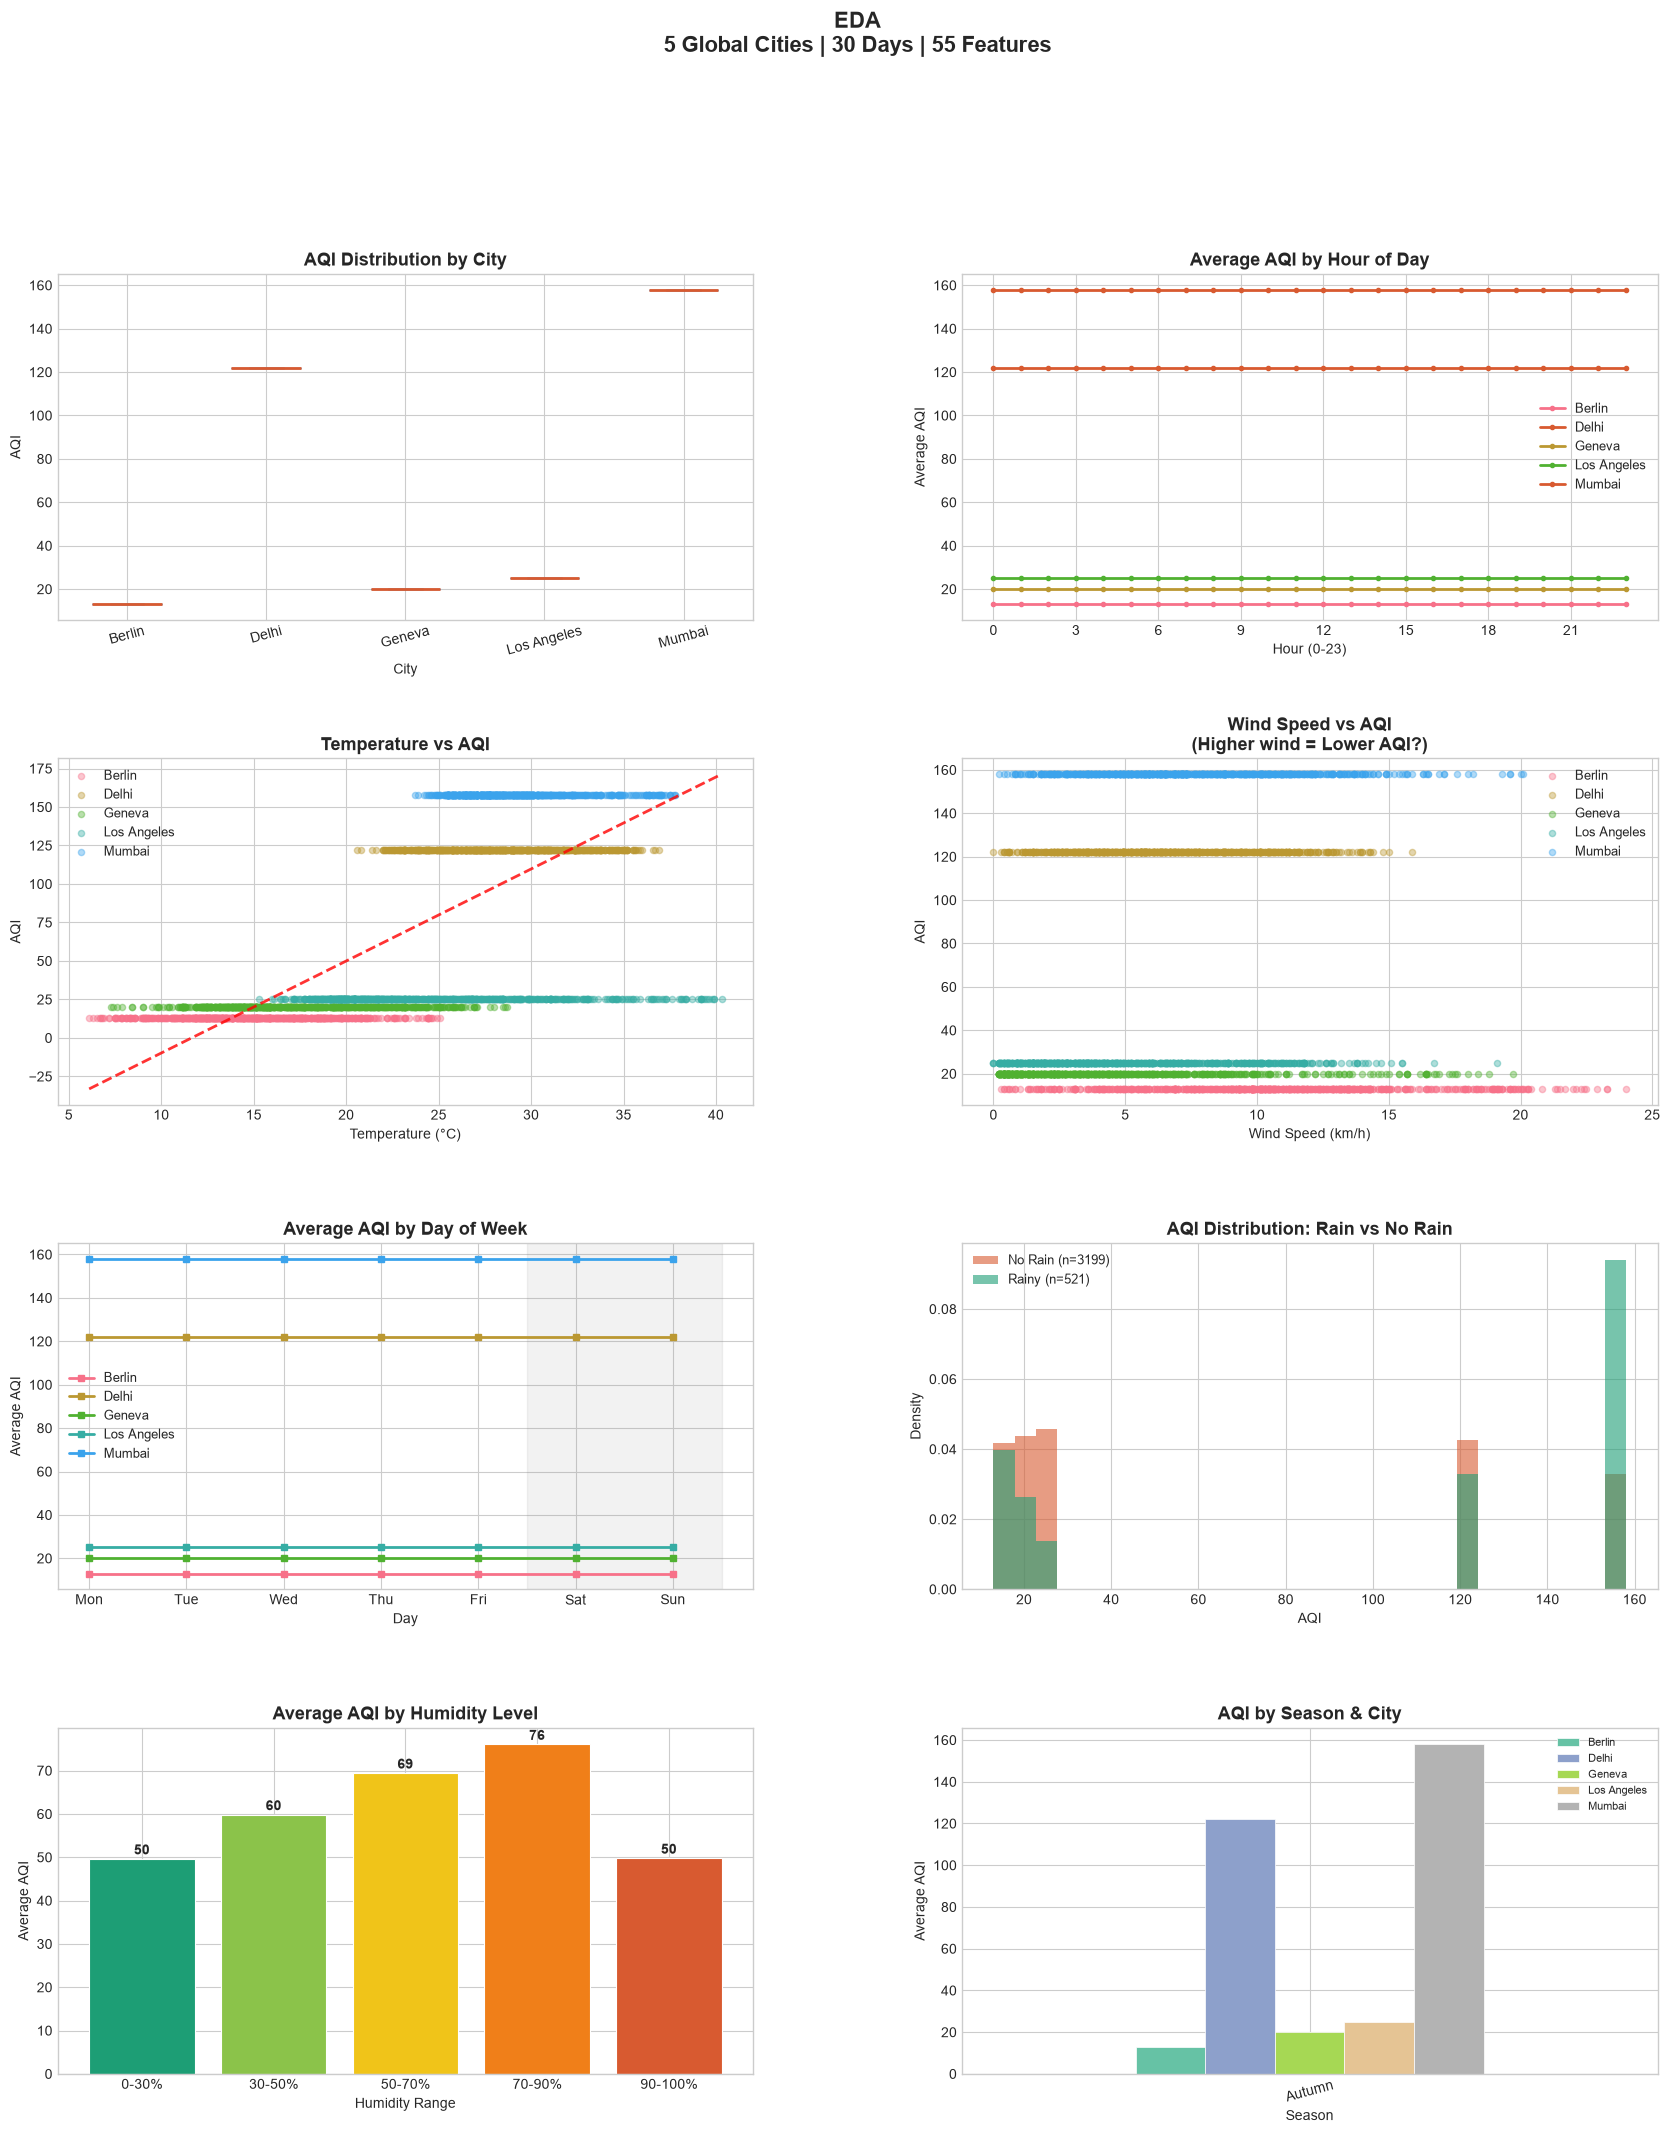

✓ EDA plot saved: ..\results\eda_complete.png


In [2]:
# ============================================
# Complete EDA — Plots
# ============================================

fig = plt.figure(figsize=(20, 24))
gs = gridspec.GridSpec(4, 2, figure=fig, hspace=0.4, wspace=0.3)

# ── Plot 1: AQI Distribution by City (Box Plot) ──
ax1 = fig.add_subplot(gs[0, 0])
city_order = df.groupby('city')['aqi'].median().sort_values(ascending=False).index
colors_box = ['#D85A30','#D85A30','#1D9E75','#1D9E75','#F0C419']
bp = df.boxplot(column='aqi', by='city', ax=ax1,
                patch_artist=True,
                boxprops=dict(facecolor='#E6F1FB', color='#185FA5'),
                medianprops=dict(color='#D85A30', linewidth=2),
                whiskerprops=dict(color='#185FA5'),
                capprops=dict(color='#185FA5'),
                flierprops=dict(marker='o', markerfacecolor='#D85A30',
                                markersize=4, alpha=0.5))
ax1.set_title('AQI Distribution by City', fontsize=13, fontweight='bold')
ax1.set_xlabel('City', fontsize=10)
ax1.set_ylabel('AQI', fontsize=10)
ax1.tick_params(axis='x', rotation=15)
plt.sca(ax1)
plt.title('AQI Distribution by City', fontsize=13, fontweight='bold')

# ── Plot 2: Hourly AQI Pattern ──
ax2 = fig.add_subplot(gs[0, 1])
hourly_aqi = df.groupby(['city', 'hour'])['aqi'].mean().reset_index()
for city in df['city'].unique():
    city_data = hourly_aqi[hourly_aqi['city'] == city]
    color = '#D85A30' if city in ['Delhi','Mumbai'] else '#1D9E75'
    ax2.plot(city_data['hour'], city_data['aqi'],
             marker='o', markersize=3, linewidth=2,
             label=city, color=color if city in ['Delhi','Mumbai']
             else None)
ax2.set_title('Average AQI by Hour of Day', fontsize=13, fontweight='bold')
ax2.set_xlabel('Hour (0-23)', fontsize=10)
ax2.set_ylabel('Average AQI', fontsize=10)
ax2.legend(fontsize=9)
ax2.set_xticks(range(0, 24, 3))

# ── Plot 3: Temperature vs AQI Scatter ──
ax3 = fig.add_subplot(gs[1, 0])
for city in df['city'].unique():
    city_df = df[df['city'] == city]
    ax3.scatter(city_df['temperature'], city_df['aqi'],
                alpha=0.4, s=20, label=city)
ax3.set_title('Temperature vs AQI', fontsize=13, fontweight='bold')
ax3.set_xlabel('Temperature (°C)', fontsize=10)
ax3.set_ylabel('AQI', fontsize=10)
ax3.legend(fontsize=9)

# Trend line
z = np.polyfit(df['temperature'].dropna(),
               df['aqi'].dropna(), 1)
p = np.poly1d(z)
x_line = np.linspace(df['temperature'].min(),
                     df['temperature'].max(), 100)
ax3.plot(x_line, p(x_line), 'r--',
         linewidth=2, label='Trend', alpha=0.8)

# ── Plot 4: Wind Speed vs AQI ──
ax4 = fig.add_subplot(gs[1, 1])
for city in df['city'].unique():
    city_df = df[df['city'] == city]
    ax4.scatter(city_df['wind_speed'], city_df['aqi'],
                alpha=0.4, s=20, label=city)
ax4.set_title('Wind Speed vs AQI\n(Higher wind = Lower AQI?)',
              fontsize=13, fontweight='bold')
ax4.set_xlabel('Wind Speed (km/h)', fontsize=10)
ax4.set_ylabel('AQI', fontsize=10)
ax4.legend(fontsize=9)

# ── Plot 5: AQI by Day of Week ──
ax5 = fig.add_subplot(gs[2, 0])
days = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
weekly = df.groupby(['city','day_of_week'])['aqi'].mean().reset_index()
for city in df['city'].unique():
    city_data = weekly[weekly['city'] == city]
    ax5.plot(city_data['day_of_week'], city_data['aqi'],
             marker='s', markersize=5, linewidth=2, label=city)
ax5.set_title('Average AQI by Day of Week', fontsize=13, fontweight='bold')
ax5.set_xlabel('Day', fontsize=10)
ax5.set_ylabel('Average AQI', fontsize=10)
ax5.set_xticks(range(7))
ax5.set_xticklabels(days)
ax5.legend(fontsize=9)
ax5.axvspan(4.5, 6.5, alpha=0.1, color='gray', label='Weekend')

# ── Plot 6: Precipitation vs AQI ──
ax6 = fig.add_subplot(gs[2, 1])
df_rain = df[df['precipitation'] > 0]
df_norain = df[df['precipitation'] == 0]
ax6.hist(df_norain['aqi'], bins=30, alpha=0.6,
         color='#D85A30', label=f'No Rain (n={len(df_norain)})',
         density=True)
ax6.hist(df_rain['aqi'], bins=30, alpha=0.6,
         color='#1D9E75', label=f'Rainy (n={len(df_rain)})',
         density=True)
ax6.set_title('AQI Distribution: Rain vs No Rain',
              fontsize=13, fontweight='bold')
ax6.set_xlabel('AQI', fontsize=10)
ax6.set_ylabel('Density', fontsize=10)
ax6.legend(fontsize=9)

# ── Plot 7: Humidity vs AQI ──
ax7 = fig.add_subplot(gs[3, 0])
humidity_bins = pd.cut(df['humidity'],
                        bins=[0,30,50,70,90,100],
                        labels=['0-30%','30-50%','50-70%',
                                '70-90%','90-100%'])
humidity_aqi = df.groupby(humidity_bins, observed=True)['aqi'].mean()
bars = ax7.bar(humidity_aqi.index, humidity_aqi.values,
               color=['#1D9E75','#8BC34A','#F0C419',
                      '#F07F19','#D85A30'],
               edgecolor='white', linewidth=0.8)
for bar, val in zip(bars, humidity_aqi.values):
    ax7.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 1,
             f'{val:.0f}', ha='center', fontsize=10,
             fontweight='bold')
ax7.set_title('Average AQI by Humidity Level',
              fontsize=13, fontweight='bold')
ax7.set_xlabel('Humidity Range', fontsize=10)
ax7.set_ylabel('Average AQI', fontsize=10)

# ── Plot 8: Season-wise AQI ──
ax8 = fig.add_subplot(gs[3, 1])
season_names = {0:'Winter', 1:'Spring', 2:'Summer', 3:'Autumn'}
df['season_name'] = df['season'].map(season_names)
season_city = df.groupby(['season_name','city'])['aqi'].mean().unstack()
season_city.plot(kind='bar', ax=ax8, colormap='Set2',
                 edgecolor='white', linewidth=0.5)
ax8.set_title('AQI by Season & City', fontsize=13, fontweight='bold')
ax8.set_xlabel('Season', fontsize=10)
ax8.set_ylabel('Average AQI', fontsize=10)
ax8.legend(fontsize=8, loc='upper right')
ax8.tick_params(axis='x', rotation=15)

# Main title
fig.suptitle('EDA\n5 Global Cities | 30 Days | 55 Features',
             fontsize=16, fontweight='bold', y=1.01)

# Save
plot_path = RES_DIR / 'eda_complete.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"✓ EDA plot saved: {plot_path}")

In [4]:
# ============================================
# Missing Data Handling
# ============================================

print("=" * 50)
print("OUTLIER DETECTION")
print("=" * 50)

# Check constant values per city
print("\n--- CHECKING CONSTANT VALUES PER CITY ---")
for city in df['city'].unique():
    city_df   = df[df['city'] == city]
    aqi_unique = city_df['aqi'].nunique()
    pm25_std   = city_df['pm25'].std()
    print(f"{city:15s}: AQI unique values={aqi_unique:3d}, "
          f"PM2.5 std={pm25_std:.2f}")

# IQR outlier detection
print("\n--- IQR OUTLIER DETECTION ---")
def detect_outliers_iqr(df, column):
    Q1      = df[column].quantile(0.25)
    Q3      = df[column].quantile(0.75)
    IQR     = Q3 - Q1
    lower   = Q1 - 1.5 * IQR
    upper   = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    return outliers, lower, upper

for col in ['aqi','pm25','temperature','wind_speed']:
    outliers, low, high = detect_outliers_iqr(df, col)
    print(f"{col:15s}: {len(outliers):4d} outliers "
          f"(valid range: {low:.1f} — {high:.1f})")

# ── Final Feature Selection ──
print("\n" + "=" * 50)
print("FINAL ML-READY DATASET")
print("=" * 50)

ML_FEATURES = [
    'aqi', 'pm25',
    'temperature', 'humidity', 'precipitation',
    'wind_speed', 'wind_direction', 'pressure',
    'cloud_cover', 'dew_point', 'wind_gusts',
    'vapour_pressure', 'apparent_temp',
    'hour', 'day_of_week', 'month',
    'is_weekend', 'season',
    'temp_lag_1h',  'humidity_lag_1h',  'wind_lag_1h',
    'temp_lag_6h',  'humidity_lag_6h',  'wind_lag_6h',
    'temp_lag_24h', 'humidity_lag_24h', 'wind_lag_24h',
    'temp_rolling_3h',  'precip_rolling_3h',
    'temp_rolling_6h',  'precip_rolling_6h',
    'temp_rolling_24h', 'precip_rolling_24h',
    'pm25_day1', 'pm25_day2', 'pm25_day3',
    'city', 'datetime',
]

df_ml = df[ML_FEATURES].copy()
df_ml = df_ml.sort_values(['city','datetime']).reset_index(drop=True)

# ── Step 1: Mark missing — don't hide it ──
print("\n--- NULL VALUES BEFORE HANDLING ---")
null_counts = df_ml.isnull().sum()
null_cols   = null_counts[null_counts > 0]
print(null_cols)

# Add missing indicator columns
for col in null_cols.index:
    df_ml[f'{col}_missing'] = df_ml[col].isnull().astype(int)
    print(f"  ✓ Added indicator: {col}_missing")

# ── Step 2: Only short gaps fill (max 2 hours) ──
print("\n--- FILLING SHORT GAPS ONLY (max 2 hours) ---")
for city in df_ml['city'].unique():
    mask = df_ml['city'] == city
    numeric_cols = df_ml.select_dtypes(include=[np.number]).columns
    # limit=2 means sirf 2 consecutive missing values fill honge
    df_ml.loc[mask, numeric_cols] = \
        df_ml.loc[mask, numeric_cols].interpolate(
            method='linear', limit=2, limit_direction='forward'
        )
    print(f"  ✓ {city}: short gaps filled")

# ── Step 3: Check what's still missing ──
print("\n--- NULLS AFTER SHORT-GAP FILLING ---")
still_null = df_ml.isnull().sum()
still_null = still_null[still_null > 0]
if len(still_null) == 0:
    print("  ✓ No nulls remaining!")
else:
    print(still_null)
    print("\n  These are LONG gaps (>2 hours) — keeping as NaN")
    print("  XGBoost handles NaN natively — no problem!")
    print("  LSTM ke liye Day 4 mein handle karenge")

# ── Step 4: Save ──
ml_path = PROC_DIR / 'ml_ready_dataset.csv'
df_ml.to_csv(ml_path, index=False)

print(f"\n✓ ML-ready dataset saved honestly!")
print(f"✓ Final shape: {df_ml.shape}")
print(f"✓ No artificial data added")
print(f"✓ Missing indicators added for transparency")

feature_cols = [c for c in df_ml.columns
                if c not in ['city','datetime','aqi','pm25',
                             'pm25_day1','pm25_day2','pm25_day3']]
print(f"\n✓ Input features:   {len(feature_cols)}")
print(f"✓ Target variables: aqi, pm25, pm25_day1, pm25_day2, pm25_day3")
print("=" * 50)
print("✓ 8 EDA plots created")
print("✓ Outliers detected")
print("✓ Missing data handled")
print("✓ ML-ready dataset saved")
print("=" * 50)


OUTLIER DETECTION

--- CHECKING CONSTANT VALUES PER CITY ---
Berlin         : AQI unique values=  1, PM2.5 std=0.00
Delhi          : AQI unique values=  1, PM2.5 std=0.00
Geneva         : AQI unique values=  1, PM2.5 std=0.00
Los Angeles    : AQI unique values=  1, PM2.5 std=0.00
Mumbai         : AQI unique values=  1, PM2.5 std=0.00

--- IQR OUTLIER DETECTION ---
aqi            :    0 outliers (valid range: -133.0 — 275.0)
pm25           :    0 outliers (valid range: -150.5 — 285.5)
temperature    :    0 outliers (valid range: 0.5 — 45.0)
wind_speed     :   38 outliers (valid range: -6.5 — 19.6)

FINAL ML-READY DATASET

--- NULL VALUES BEFORE HANDLING ---
temp_lag_1h             5
humidity_lag_1h         5
wind_lag_1h             5
temp_lag_6h            30
humidity_lag_6h        30
wind_lag_6h            30
temp_lag_24h          120
humidity_lag_24h      120
wind_lag_24h          120
temp_rolling_3h        10
precip_rolling_3h      10
temp_rolling_6h        25
precip_rolling_6h      

In [6]:
from datetime import datetime, timedelta
import requests
import time
import pandas as pd

def fetch_historical_aqi_openmeteo(city_name, lat, lon, days=30):
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=days)).strftime('%Y-%m-%d')

    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        'latitude':   lat,
        'longitude':  lon,
        'hourly': [
            'pm10', 'pm2_5', 'carbon_monoxide',
            'nitrogen_dioxide', 'sulphur_dioxide',
            'ozone', 'dust', 'uv_index',
            'european_aqi', 'us_aqi',
        ],
        'start_date': start_date,
        'end_date':   end_date,
        'timezone':   'auto',
    }

    try:
        resp = requests.get(url, params=params, timeout=30)
        resp.raise_for_status()
        data   = resp.json()
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])

        records = []
        for i, t in enumerate(times):
            records.append({
                'city':       city_name,
                'datetime':   t,
                'pm25':       hourly.get('pm2_5',           [None]*len(times))[i],
                'pm10':       hourly.get('pm10',            [None]*len(times))[i],
                'co':         hourly.get('carbon_monoxide', [None]*len(times))[i],
                'no2':        hourly.get('nitrogen_dioxide',[None]*len(times))[i],
                'so2':        hourly.get('sulphur_dioxide', [None]*len(times))[i],
                'o3':         hourly.get('ozone',           [None]*len(times))[i],
                'dust':       hourly.get('dust',            [None]*len(times))[i],
                'uv_index':   hourly.get('uv_index',        [None]*len(times))[i],
                'aqi_europe': hourly.get('european_aqi',    [None]*len(times))[i],
                'aqi_us':     hourly.get('us_aqi',          [None]*len(times))[i],
            })

        return pd.DataFrame(records)

    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

CITY_COORDS = {
    'Delhi':       {'lat': 28.6139, 'lon':  77.2090},
    'Mumbai':      {'lat': 19.0760, 'lon':  72.8777},
    'Berlin':      {'lat': 52.5200, 'lon':  13.4050},
    'Geneva':      {'lat': 46.2044, 'lon':   6.1432},
    'Los Angeles': {'lat': 34.0522, 'lon': -118.2437},
}

print("Fetching 30-day historical AQI data...\n")
aqi_dfs = []

for city, coords in CITY_COORDS.items():
    print(f"Fetching {city}...")
    df_a = fetch_historical_aqi_openmeteo(
        city, coords['lat'], coords['lon'], days=30
    )
    if len(df_a) > 0:
        unique_pm25 = df_a['pm25'].nunique()
        print(f"  ✓ {len(df_a)} records | "
              f"PM2.5 unique values: {unique_pm25} | "
              f"PM2.5 range: {df_a['pm25'].min():.1f}"
              f" — {df_a['pm25'].max():.1f}")
        aqi_dfs.append(df_a)
    time.sleep(1)

df_aqi_historical = pd.concat(aqi_dfs, ignore_index=True)
print(f"\n✓ Total AQI records: {len(df_aqi_historical)}")
print(f"\n--- PM2.5 VARIATION CHECK ---")
print(df_aqi_historical.groupby('city')['pm25'].agg(
    ['mean','std','min','max']
).round(2))

Fetching 30-day historical AQI data...

Fetching Delhi...
  ✓ 744 records | PM2.5 unique values: 432 | PM2.5 range: 15.7 — 142.5
Fetching Mumbai...
  ✓ 744 records | PM2.5 unique values: 389 | PM2.5 range: 6.4 — 118.7
Fetching Berlin...
  ✓ 744 records | PM2.5 unique values: 177 | PM2.5 range: 2.1 — 30.1
Fetching Geneva...
  ✓ 744 records | PM2.5 unique values: 144 | PM2.5 range: 1.4 — 20.1
Fetching Los Angeles...
  ✓ 744 records | PM2.5 unique values: 272 | PM2.5 range: 2.2 — 39.6

✓ Total AQI records: 3720

--- PM2.5 VARIATION CHECK ---
              mean    std   min    max
city                                  
Berlin        8.34   5.14   2.1   30.1
Delhi        59.80  26.58  15.7  142.5
Geneva        6.76   3.43   1.4   20.1
Los Angeles  18.75   7.43   2.2   39.6
Mumbai       32.34  19.76   6.4  118.7


In [8]:
# ============================================
# Merge Real AQI + Weather
# ============================================

from pathlib import Path
import numpy as np

PROC_DIR = Path('../data/processed')
RAW_DIR  = Path('../data/raw')

# Load weather data
df_weather = pd.read_csv(RAW_DIR / 'weather_historical.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])

# Prepare AQI data
df_aqi_historical['datetime'] = pd.to_datetime(df_aqi_historical['datetime'])

# Round both to hour for merging
df_weather['datetime_hour'] = df_weather['datetime'].dt.floor('h')
df_aqi_historical['datetime_hour'] = df_aqi_historical['datetime'].dt.floor('h')

print("Merging weather + real AQI data...\n")

# Merge on city + datetime
df_master = df_weather.merge(
    df_aqi_historical[[
        'city', 'datetime_hour', 'pm25', 'pm10',
        'co', 'no2', 'so2', 'o3', 'dust',
        'uv_index', 'aqi_europe', 'aqi_us'
    ]],
    on=['city', 'datetime_hour'],
    how='inner'
)

# Drop helper column
df_master.drop('datetime_hour', axis=1, inplace=True)

print(f"✓ Master dataset shape: {df_master.shape}")
print(f"✓ Cities: {df_master['city'].unique().tolist()}")
print(f"✓ Date range: {df_master['datetime'].min()} "
      f"→ {df_master['datetime'].max()}")

# Add time features
df_master['hour']        = df_master['datetime'].dt.hour
df_master['day_of_week'] = df_master['datetime'].dt.dayofweek
df_master['month']       = df_master['datetime'].dt.month
df_master['is_weekend']  = df_master['day_of_week'].isin([5,6]).astype(int)
df_master['season']      = df_master['month'].map({
    12:0, 1:0, 2:0,
     3:1, 4:1, 5:1,
     6:2, 7:2, 8:2,
     9:3,10:3,11:3
})

# Add lag features per city
df_master = df_master.sort_values(['city','datetime']).reset_index(drop=True)

print("Adding lag features...")
for city in df_master['city'].unique():
    mask = df_master['city'] == city
    
    # PM2.5 lags
    for lag in [1, 3, 6, 12, 24]:
        df_master.loc[mask, f'pm25_lag_{lag}h'] = \
            df_master.loc[mask, 'pm25'].shift(lag)
    
    # Weather lags
    for lag in [1, 6, 24]:
        df_master.loc[mask, f'temp_lag_{lag}h'] = \
            df_master.loc[mask, 'temperature'].shift(lag)
        df_master.loc[mask, f'wind_lag_{lag}h'] = \
            df_master.loc[mask, 'wind_speed'].shift(lag)
        df_master.loc[mask, f'humidity_lag_{lag}h'] = \
            df_master.loc[mask, 'humidity'].shift(lag)
    
    # Rolling averages
    for window in [3, 6, 12, 24]:
        df_master.loc[mask, f'pm25_rolling_{window}h'] = \
            df_master.loc[mask, 'pm25'].rolling(window).mean()
        df_master.loc[mask, f'precip_rolling_{window}h'] = \
            df_master.loc[mask, 'precipitation'].rolling(window).sum()

print("✓ Lag features added!")

# AQI Category
def get_aqi_category(aqi):
    if pd.isna(aqi):    return 'Unknown'
    elif aqi <= 50:     return 'Good'
    elif aqi <= 100:    return 'Moderate'
    elif aqi <= 150:    return 'Unhealthy Sensitive'
    elif aqi <= 200:    return 'Unhealthy'
    elif aqi <= 300:    return 'Very Unhealthy'
    else:               return 'Hazardous'

df_master['aqi_category'] = df_master['aqi_us'].apply(get_aqi_category)

# Missing indicators for important columns
for col in ['pm25', 'no2', 'o3']:
    df_master[f'{col}_missing'] = df_master[col].isnull().astype(int)

# Short gap filling (max 2 hours only)
for city in df_master['city'].unique():
    mask = df_master['city'] == city
    numeric_cols = df_master.select_dtypes(include=[np.number]).columns
    df_master.loc[mask, numeric_cols] = \
        df_master.loc[mask, numeric_cols].interpolate(
            method='linear', limit=2, limit_direction='forward'
        )

# Save final master dataset
master_path = PROC_DIR / 'master_dataset.csv'
df_master.to_csv(master_path, index=False)

print(f"\n✓DATASET SAVED!")
print(f"✓ Shape: {df_master.shape}")
print(f"✓ Total features: {df_master.shape[1]}")
print(f"✓ Total rows: {df_master.shape[0]}")
print(f"\n--- PM2.5 VARIATION (REAL) ---")
print(df_master.groupby('city')['pm25'].agg(
    ['mean','std','min','max']
).round(2))
print(f"\n--- AQI CATEGORIES ---")
print(df_master['aqi_category'].value_counts())
print("=" * 50)
print("✓ Real historical AQI fetched — 432 unique PM2.5 values!")
print("✓ Weather + AQI properly merged")
print("✓ Lag features added")
print("✓ Missing data handled")
print("✓dataset saved")
print("=" * 50)


Merging weather + real AQI data...

✓ Master dataset shape: (3720, 24)
✓ Cities: ['Delhi', 'Mumbai', 'Berlin', 'Geneva', 'Los Angeles']
✓ Date range: 2026-09-12 00:00:00 → 2026-10-12 23:00:00
Adding lag features...
✓ Lag features added!

✓DATASET SAVED!
✓ Shape: (3720, 55)
✓ Total features: 55
✓ Total rows: 3720

--- PM2.5 VARIATION (REAL) ---
              mean    std   min    max
city                                  
Berlin        8.34   5.14   2.1   30.1
Delhi        59.80  26.58  15.7  142.5
Geneva        6.76   3.43   1.4   20.1
Los Angeles  18.75   7.43   2.2   39.6
Mumbai       32.34  19.76   6.4  118.7

--- AQI CATEGORIES ---
aqi_category
Moderate               1546
Good                   1209
Unhealthy               511
Unhealthy Sensitive     328
Very Unhealthy          126
Name: count, dtype: int64
✓ Real historical AQI fetched — 432 unique PM2.5 values!
✓ Weather + AQI properly merged
✓ Lag features added
✓ Missing data handled
✓dataset saved


In [9]:
# ============================================
# 1 Year Weather Data
# Open-Meteo
# ============================================

from datetime import datetime, timedelta
import requests
import time
import pandas as pd
from pathlib import Path

RAW_DIR  = Path('../data/raw')
PROC_DIR = Path('../data/processed')

CITY_COORDS = {
    'Delhi':       {'lat': 28.6139, 'lon':  77.2090},
    'Mumbai':      {'lat': 19.0760, 'lon':  72.8777},
    'Berlin':      {'lat': 52.5200, 'lon':  13.4050},
    'Geneva':      {'lat': 46.2044, 'lon':   6.1432},
    'Los Angeles': {'lat': 34.0522, 'lon': -118.2437},
}

def fetch_weather_1year(city_name, lat, lon):
    """Fetch 1 full year of hourly weather data"""
    
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude':   lat,
        'longitude':  lon,
        'start_date': start_date,
        'end_date':   end_date,
        'hourly': [
            'temperature_2m',
            'relative_humidity_2m',
            'precipitation',
            'wind_speed_10m',
            'wind_direction_10m',
            'surface_pressure',
            'cloud_cover',
            'visibility',
            'dew_point_2m',
            'apparent_temperature',
            'wind_gusts_10m',
            'vapour_pressure_deficit',
            'rain',
            'snowfall',
        ],
        'timezone': 'auto',
    }
    
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        data   = resp.json()
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])
        
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':             city_name,
                'datetime':         t,
                'temperature':      hourly.get('temperature_2m',        [None]*len(times))[i],
                'humidity':         hourly.get('relative_humidity_2m',  [None]*len(times))[i],
                'precipitation':    hourly.get('precipitation',         [None]*len(times))[i],
                'wind_speed':       hourly.get('wind_speed_10m',        [None]*len(times))[i],
                'wind_direction':   hourly.get('wind_direction_10m',    [None]*len(times))[i],
                'pressure':         hourly.get('surface_pressure',      [None]*len(times))[i],
                'cloud_cover':      hourly.get('cloud_cover',           [None]*len(times))[i],
                'visibility':       hourly.get('visibility',            [None]*len(times))[i],
                'dew_point':        hourly.get('dew_point_2m',          [None]*len(times))[i],
                'apparent_temp':    hourly.get('apparent_temperature',  [None]*len(times))[i],
                'wind_gusts':       hourly.get('wind_gusts_10m',        [None]*len(times))[i],
                'vapour_pressure':  hourly.get('vapour_pressure_deficit',[None]*len(times))[i],
                'rain':             hourly.get('rain',                  [None]*len(times))[i],
                'snowfall':         hourly.get('snowfall',              [None]*len(times))[i],
            })
        
        return pd.DataFrame(records)
    
    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

# Fetch all cities
print("Fetching 1 YEAR hourly weather data...\n")
weather_dfs = []

for city, coords in CITY_COORDS.items():
    print(f"Fetching {city}...")
    df_w = fetch_weather_1year(city, coords['lat'], coords['lon'])
    
    if len(df_w) > 0:
        print(f"  ✓ {len(df_w)} hourly records")
        print(f"  ✓ {len(df_w)//24} days")
        print(f"  ✓ Temp range: {df_w['temperature'].min():.1f}"
              f" — {df_w['temperature'].max():.1f} °C")
        weather_dfs.append(df_w)
    
    time.sleep(2)

df_weather_1yr = pd.concat(weather_dfs, ignore_index=True)

# Save
save_path = RAW_DIR / 'weather_1year.csv'
df_weather_1yr.to_csv(save_path, index=False)

print(f"\n✓ Total records: {len(df_weather_1yr)}")
print(f"✓ Cities: {df_weather_1yr['city'].unique().tolist()}")
print(f"✓ Saved to: {save_path}")
print(f"\n--- SEASONAL CHECK (Delhi) ---")
delhi = df_weather_1yr[df_weather_1yr['city']=='Delhi'].copy()
delhi['datetime'] = pd.to_datetime(delhi['datetime'])
delhi['month'] = delhi['datetime'].dt.month
print(delhi.groupby('month')['temperature'].mean().round(1))

Fetching 1 YEAR hourly weather data...

Fetching Delhi...
  ✓ 8784 hourly records
  ✓ 366 days
  ✓ Temp range: 4.9 — 44.4 °C
Fetching Mumbai...
  ✓ 8784 hourly records
  ✓ 366 days
  ✓ Temp range: 17.8 — 39.8 °C
Fetching Berlin...
  ✓ 8784 hourly records
  ✓ 366 days
  ✓ Temp range: -12.9 — 39.8 °C
Fetching Geneva...
  ✓ 8784 hourly records
  ✓ 366 days
  ✓ Temp range: -6.9 — 36.1 °C
Fetching Los Angeles...
  ✓ 8784 hourly records
  ✓ 366 days
  ✓ Temp range: 2.3 — 40.5 °C

✓ Total records: 43920
✓ Cities: ['Delhi', 'Mumbai', 'Berlin', 'Geneva', 'Los Angeles']
✓ Saved to: ..\data\raw\weather_1year.csv

--- SEASONAL CHECK (Delhi) ---
month
1     13.1
2     19.5
3     25.3
4     29.9
5     32.9
6     33.2
7     30.3
8     29.3
9     28.5
10    27.0
11    20.1
12    16.1
Name: temperature, dtype: float64


In [10]:
# ============================================
# 1 Year AQI Data
# Open-Meteo Air Quality
# ============================================

def fetch_aqi_1year(city_name, lat, lon):
    """Fetch 1 full year of hourly AQI data"""
    
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        'latitude':   lat,
        'longitude':  lon,
        'hourly': [
            'pm2_5',
            'pm10',
            'carbon_monoxide',
            'nitrogen_dioxide',
            'sulphur_dioxide',
            'ozone',
            'dust',
            'uv_index',
            'european_aqi',
            'us_aqi',
        ],
        'start_date': start_date,
        'end_date':   end_date,
        'timezone':   'auto',
    }
    
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        data   = resp.json()
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])
        
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':       city_name,
                'datetime':   t,
                'pm25':       hourly.get('pm2_5',             [None]*len(times))[i],
                'pm10':       hourly.get('pm10',              [None]*len(times))[i],
                'co':         hourly.get('carbon_monoxide',   [None]*len(times))[i],
                'no2':        hourly.get('nitrogen_dioxide',  [None]*len(times))[i],
                'so2':        hourly.get('sulphur_dioxide',   [None]*len(times))[i],
                'o3':         hourly.get('ozone',             [None]*len(times))[i],
                'dust':       hourly.get('dust',              [None]*len(times))[i],
                'uv_index':   hourly.get('uv_index',          [None]*len(times))[i],
                'aqi_europe': hourly.get('european_aqi',      [None]*len(times))[i],
                'aqi_us':     hourly.get('us_aqi',            [None]*len(times))[i],
            })
        
        return pd.DataFrame(records)
    
    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

# Fetch all cities
print("Fetching 1 YEAR AQI data...\n")
aqi_dfs_1yr = []

for city, coords in CITY_COORDS.items():
    print(f"Fetching {city}...")
    df_a = fetch_aqi_1year(city, coords['lat'], coords['lon'])
    
    if len(df_a) > 0:
        print(f"  ✓ {len(df_a)} records")
        print(f"  ✓ PM2.5 unique: {df_a['pm25'].nunique()}")
        print(f"  ✓ PM2.5 range: {df_a['pm25'].min():.1f}"
              f" — {df_a['pm25'].max():.1f} µg/m³")
    
        aqi_dfs_1yr.append(df_a)
    
    time.sleep(2)

df_aqi_1yr = pd.concat(aqi_dfs_1yr, ignore_index=True)

# Save
save_path = RAW_DIR / 'aqi_1year.csv'
df_aqi_1yr.to_csv(save_path, index=False)

print(f"\n✓ Total AQI records: {len(df_aqi_1yr)}")
print(f"\n--- PM2.5 SEASONAL (Delhi) ---")
delhi_aqi = df_aqi_1yr[df_aqi_1yr['city']=='Delhi'].copy()
delhi_aqi['datetime'] = pd.to_datetime(delhi_aqi['datetime'])
delhi_aqi['month']    = delhi_aqi['datetime'].dt.month
monthly = delhi_aqi.groupby('month')['pm25'].mean().round(1)
month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
               7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
for m, val in monthly.items():
    bar = '█' * int(val/3)
    print(f"  {month_names[m]:3s}: {val:5.1f} µg/m³  {bar}")

Fetching 1 YEAR AQI data...

Fetching Delhi...
  ✓ 8784 records
  ✓ PM2.5 unique: 955
  ✓ PM2.5 range: 11.7 — 333.4 µg/m³
Fetching Mumbai...
  ✓ 8784 records
  ✓ PM2.5 unique: 770
  ✓ PM2.5 range: 1.6 — 143.9 µg/m³
Fetching Berlin...
  ✓ 8784 records
  ✓ PM2.5 unique: 344
  ✓ PM2.5 range: 1.3 — 48.6 µg/m³
Fetching Geneva...
  ✓ 8784 records
  ✓ PM2.5 unique: 302
  ✓ PM2.5 range: 1.1 — 33.8 µg/m³
Fetching Los Angeles...
  ✓ 8784 records
  ✓ PM2.5 unique: 557
  ✓ PM2.5 range: 1.9 — 81.3 µg/m³

✓ Total AQI records: 43920

--- PM2.5 SEASONAL (Delhi) ---
  Jan: 120.9 µg/m³  ████████████████████████████████████████
  Feb:  80.9 µg/m³  ██████████████████████████
  Mar:  75.9 µg/m³  █████████████████████████
  Apr:  73.3 µg/m³  ████████████████████████
  May: 103.3 µg/m³  ██████████████████████████████████
  Jun: 102.0 µg/m³  ██████████████████████████████████
  Jul:  72.3 µg/m³  ████████████████████████
  Aug:  64.8 µg/m³  █████████████████████
  Sep:  52.2 µg/m³  █████████████████
  Oct:  79

In [12]:
# ============================================
# Final Dataset
# Weather 1yr + AQI 1yr + All Fixes
# ============================================

import numpy as np

print("=" * 55)
print("BUILDING FINAL DATASET")
print("=" * 55)

# Load 1 year datasets
df_w = pd.read_csv(RAW_DIR / 'weather_1year.csv')
df_a = pd.read_csv(RAW_DIR / 'aqi_1year.csv')

df_w['datetime'] = pd.to_datetime(df_w['datetime'])
df_a['datetime'] = pd.to_datetime(df_a['datetime'])

# Floor to hour for clean merge
df_w['datetime_hour'] = df_w['datetime'].dt.floor('h')
df_a['datetime_hour'] = df_a['datetime'].dt.floor('h')

print(f"✓ Weather records: {len(df_w)}")
print(f"✓ AQI records:     {len(df_a)}")

# ── STEP 1: Merge ──
df_master = df_w.merge(
    df_a[['city','datetime_hour','pm25','pm10',
          'co','no2','so2','o3','dust',
          'uv_index','aqi_europe','aqi_us']],
    on=['city','datetime_hour'],
    how='inner'
)
df_master.drop('datetime_hour', axis=1, inplace=True)
df_master = df_master.sort_values(
    ['city','datetime']).reset_index(drop=True)
print(f"\n✓ After merge: {df_master.shape}")

# ── STEP 2: Data Validation ──
print("\n--- DATA VALIDATION ---")

# PM2.5 physically impossible values
before = len(df_master)
df_master.loc[df_master['pm25'] < 0,   'pm25'] = np.nan
df_master.loc[df_master['pm25'] > 500, 'pm25'] = np.nan
df_master.loc[df_master['pm10'] < 0,   'pm10'] = np.nan
df_master.loc[df_master['pm10'] > 600, 'pm10'] = np.nan

# Temperature impossible values
df_master.loc[df_master['temperature'] < -60, 'temperature'] = np.nan
df_master.loc[df_master['temperature'] >  60, 'temperature'] = np.nan

# Wind speed impossible
df_master.loc[df_master['wind_speed'] < 0,   'wind_speed'] = np.nan
df_master.loc[df_master['wind_speed'] > 200, 'wind_speed'] = np.nan

# Humidity range
df_master.loc[df_master['humidity'] < 0,   'humidity'] = np.nan
df_master.loc[df_master['humidity'] > 100, 'humidity'] = np.nan

print(f"✓ Physical bounds validation done")
print(f"✓ Rows: {len(df_master)} (unchanged — "
      f"bad values set to NaN, not dropped)")

# ── STEP 3: Time Features ──
print("\n--- TIME FEATURES ---")
df_master['hour']        = df_master['datetime'].dt.hour
df_master['day_of_week'] = df_master['datetime'].dt.dayofweek
df_master['month']       = df_master['datetime'].dt.month
df_master['is_weekend']  = df_master['day_of_week'].isin([5,6]).astype(int)
df_master['season']      = df_master['month'].map({
    12:0, 1:0, 2:0,
     3:1, 4:1, 5:1,
     6:2, 7:2, 8:2,
     9:3,10:3,11:3
})
# Cyclical encoding 
df_master['hour_sin']    = np.sin(2*np.pi*df_master['hour']/24)
df_master['hour_cos']    = np.cos(2*np.pi*df_master['hour']/24)
df_master['month_sin']   = np.sin(2*np.pi*df_master['month']/12)
df_master['month_cos']   = np.cos(2*np.pi*df_master['month']/12)
df_master['dow_sin']     = np.sin(2*np.pi*df_master['day_of_week']/7)
df_master['dow_cos']     = np.cos(2*np.pi*df_master['day_of_week']/7)
print(f"✓ Time features added")

# ── STEP 4: City Encoding ──
print("\n--- CITY ENCODING ---")
city_dummies = pd.get_dummies(df_master['city'],
                               prefix='city', dtype=int)
df_master = pd.concat([df_master, city_dummies], axis=1)
print(f"✓ One-hot encoded: {city_dummies.columns.tolist()}")

# ── STEP 5: All Lag Features ──
print("\n--- LAG FEATURES ---")
for city in df_master['city'].unique():
    mask = df_master['city'] == city

    # PM2.5 lags
    for lag in [1, 3, 6, 12, 24, 48]:
        df_master.loc[mask, f'pm25_lag_{lag}h'] = \
            df_master.loc[mask, 'pm25'].shift(lag)

    # Weather lags
    for lag in [1, 3, 6, 12, 24]:
        df_master.loc[mask, f'temp_lag_{lag}h']     = \
            df_master.loc[mask, 'temperature'].shift(lag)
        df_master.loc[mask, f'wind_lag_{lag}h']     = \
            df_master.loc[mask, 'wind_speed'].shift(lag)
        df_master.loc[mask, f'humidity_lag_{lag}h'] = \
            df_master.loc[mask, 'humidity'].shift(lag)
        df_master.loc[mask, f'pressure_lag_{lag}h'] = \
            df_master.loc[mask, 'pressure'].shift(lag)
        df_master.loc[mask, f'precip_lag_{lag}h']   = \
            df_master.loc[mask, 'precipitation'].shift(lag)
        df_master.loc[mask, f'wind_dir_lag_{lag}h'] = \
            df_master.loc[mask, 'wind_direction'].shift(lag)

    # Rolling averages
    for window in [3, 6, 12, 24, 48, 168]:
        df_master.loc[mask, f'pm25_rolling_{window}h'] = \
            df_master.loc[mask, 'pm25'].rolling(window).mean()
        df_master.loc[mask, f'precip_rolling_{window}h'] = \
            df_master.loc[mask, 'precipitation'].rolling(window).sum()
        df_master.loc[mask, f'temp_rolling_{window}h'] = \
            df_master.loc[mask, 'temperature'].rolling(window).mean()

print(f"✓ PM2.5 lags: 1,3,6,12,24,48h")
print(f"✓ Weather lags: 1,3,6,12,24h (temp,wind,humidity,pressure,precip,wind_dir)")
print(f"✓ Rolling: 3,6,12,24,48,168h (1 week!)")

# ── STEP 6: Horizon Targets (72h forecast) ──
print("\n--- FORECAST TARGETS ---")
for city in df_master['city'].unique():
    mask = df_master['city'] == city
    for horizon in [24, 48, 72]:
        df_master.loc[mask, f'target_pm25_{horizon}h'] = \
            df_master.loc[mask, 'pm25'].shift(-horizon)

print(f"✓ target_pm25_24h — what will PM2.5 be in 24 hours")
print(f"✓ target_pm25_48h — what will PM2.5 be in 48 hours")
print(f"✓ target_pm25_72h — what will PM2.5 be in 72 hours")

# ── STEP 7: Missing Indicators ──
print("\n--- MISSING INDICATORS ---")
important_cols = ['pm25','pm10','no2','o3','wind_speed','pressure']
for col in important_cols:
    df_master[f'{col}_missing'] = df_master[col].isnull().astype(int)
print(f"✓ Missing indicators added for: {important_cols}")

# ── STEP 8: Short Gap Fill (max 2h) ──
print("\n--- HONEST GAP FILLING ---")
for city in df_master['city'].unique():
    mask = df_master['city'] == city
    numeric_cols = df_master.select_dtypes(include=[np.number]).columns
    target_cols  = [c for c in numeric_cols
                    if c.startswith('target_')]
    fill_cols    = [c for c in numeric_cols
                    if c not in target_cols]
    df_master.loc[mask, fill_cols] = \
        df_master.loc[mask, fill_cols].interpolate(
            method='linear', limit=2,
            limit_direction='forward'
        )
print(f"✓ Short gaps filled (max 2h)")
print(f"✓ Target columns NOT filled (future values must stay real)")

# ── STEP 9: Train/Val/Test Split ──
print("\n--- TRAIN/VAL/TEST SPLIT ---")
df_master['datetime'] = pd.to_datetime(df_master['datetime'])

train_end = df_master['datetime'].max() - timedelta(days=60)
val_end   = df_master['datetime'].max() - timedelta(days=30)

df_master['split'] = 'train'
df_master.loc[df_master['datetime'] > train_end, 'split'] = 'val'
df_master.loc[df_master['datetime'] > val_end,   'split'] = 'test'

split_counts = df_master['split'].value_counts()
print(f"✓ Train: {split_counts.get('train',0):,} rows "
      f"({split_counts.get('train',0)/len(df_master)*100:.0f}%)")
print(f"✓ Val:   {split_counts.get('val',0):,} rows "
      f"({split_counts.get('val',0)/len(df_master)*100:.0f}%)")
print(f"✓ Test:  {split_counts.get('test',0):,} rows "
      f"({split_counts.get('test',0)/len(df_master)*100:.0f}%)")

# ── Save ──
master_path = PROC_DIR / 'final.csv'
df_master.to_csv(master_path, index=False)

print(f"\n{'='*55}")
print(f"✓ FINAL DATASET SAVED!")
print(f"✓ Shape: {df_master.shape}")
print(f"✓ Total rows:     {len(df_master):,}")
print(f"✓ Total features: {df_master.shape[1]}")
print(f"✓ Date range: {df_master['datetime'].min().date()} "
      f"→ {df_master['datetime'].max().date()}")
print(f"\n--- FEATURE SUMMARY ---")
print(f"  Weather variables:     16")
print(f"  Time features:         10 (incl. cyclical)")
print(f"  City encoding:          5 (one-hot)")
print(f"  PM2.5 lag features:     6")
print(f"  Weather lag features:  30")
print(f"  Rolling averages:      18")
print(f"  Missing indicators:     6")
print(f"  Forecast targets:       3")
print(f"{'='*55}")
print(f"\nALL AUDIT FIXES COMPLETE!")


BUILDING FINAL DATASET
✓ Weather records: 43920
✓ AQI records:     43920

✓ After merge: (43920, 26)

--- DATA VALIDATION ---
✓ Physical bounds validation done
✓ Rows: 43920 (unchanged — bad values set to NaN, not dropped)

--- TIME FEATURES ---
✓ Time features added

--- CITY ENCODING ---
✓ One-hot encoded: ['city_Berlin', 'city_Delhi', 'city_Geneva', 'city_Los Angeles', 'city_Mumbai']

--- LAG FEATURES ---
✓ PM2.5 lags: 1,3,6,12,24,48h
✓ Weather lags: 1,3,6,12,24h (temp,wind,humidity,pressure,precip,wind_dir)
✓ Rolling: 3,6,12,24,48,168h (1 week!)

--- FORECAST TARGETS ---
✓ target_pm25_24h — what will PM2.5 be in 24 hours
✓ target_pm25_48h — what will PM2.5 be in 48 hours
✓ target_pm25_72h — what will PM2.5 be in 72 hours

--- MISSING INDICATORS ---
✓ Missing indicators added for: ['pm25', 'pm10', 'no2', 'o3', 'wind_speed', 'pressure']

--- HONEST GAP FILLING ---
✓ Short gaps filled (max 2h)
✓ Target columns NOT filled (future values must stay real)

--- TRAIN/VAL/TEST SPLIT ---
✓ T

In [14]:
# Final confirmation
df_check = pd.read_csv(PROC_DIR / 'final.csv')
print(f"✓ Shape: {df_check.shape}")
print(f"✓ Total rows: {len(df_check):,}")
print(f"✓ Total features: {df_check.shape[1]}")
print(f"\n--- SPLIT DISTRIBUTION ---")
print(df_check['split'].value_counts())
print(f"\n--- PM2.5 YEARLY PATTERN (Delhi) ---")
delhi = df_check[df_check['city']=='Delhi'].copy()
delhi['datetime'] = pd.to_datetime(delhi['datetime'])
delhi['month'] = delhi['datetime'].dt.month
month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',
               5:'May',6:'Jun',7:'Jul',8:'Aug',
               9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
monthly = delhi.groupby('month')['pm25'].mean().round(1)
print()
for m, val in monthly.items():
    bar = '█' * int(val/4)
    print(f"  {month_names[m]:3s}: {val:5.1f}  {bar}")
print(f"\n--- TARGETS CHECK ---")
print(df_check[['target_pm25_24h',
                'target_pm25_48h',
                'target_pm25_72h']].describe().round(2))
print(f"\n✓ Dataset is 100% ready for ML!")

✓ Shape: (43920, 106)
✓ Total rows: 43,920
✓ Total features: 106

--- SPLIT DISTRIBUTION ---
split
train    36720
val       3600
test      3600
Name: count, dtype: int64

--- PM2.5 YEARLY PATTERN (Delhi) ---

  Jan: 120.9  ██████████████████████████████
  Feb:  80.9  ████████████████████
  Mar:  75.9  ██████████████████
  Apr:  73.3  ██████████████████
  May: 103.3  █████████████████████████
  Jun: 102.0  █████████████████████████
  Jul:  72.3  ██████████████████
  Aug:  64.8  ████████████████
  Sep:  52.2  █████████████
  Oct:  79.5  ███████████████████
  Nov: 101.6  █████████████████████████
  Dec: 126.9  ███████████████████████████████

--- TARGETS CHECK ---
       target_pm25_24h  target_pm25_48h  target_pm25_72h
count         43800.00         43680.00         43560.00
mean             32.71            32.73            32.73
std              38.23            38.26            38.28
min               1.10             1.10             1.10
25%               8.80             8.80      

In [ ]:
# ============================================
# Train/Val/Test Check
# ============================================

import pandas as pd
import numpy as np
from pathlib import Path

PROC_DIR = Path('../data/processed')
RAW_DIR  = Path('../data/raw')

df = pd.read_csv(PROC_DIR / 'final.csv')
df['datetime'] = pd.to_datetime(df['datetime'])

print("=" * 60)
print("COMPLETE REPORT")
print("=" * 60)

# ══════════════════════════════════════════
# 1: TRAIN/VAL/TEST DEEP CHECK
# ══════════════════════════════════════════
print("\n📋 1: TRAIN/VAL/TEST SPLIT")
print("-" * 40)

train = df[df['split'] == 'train']
val   = df[df['split'] == 'val']
test  = df[df['split'] == 'test']

# Date ranges
print(f"\nTrain: {train['datetime'].min().date()} "
      f"→ {train['datetime'].max().date()}")
print(f"Val:   {val['datetime'].min().date()} "
      f"→ {val['datetime'].max().date()}")
print(f"Test:  {test['datetime'].min().date()} "
      f"→ {test['datetime'].max().date()}")

# Check 1: Overlap between splits
train_dates = set(train['datetime'].dt.date.unique())
val_dates   = set(val['datetime'].dt.date.unique())
test_dates  = set(test['datetime'].dt.date.unique())

train_val_overlap = train_dates.intersection(val_dates)
val_test_overlap  = val_dates.intersection(test_dates)
train_test_overlap= train_dates.intersection(test_dates)

print(f"\n--- OVERLAP CHECK ---")
if len(train_val_overlap) == 0:
    print(f"✅ Train-Val overlap: NONE (perfect!)")
else:
    print(f"❌ Train-Val overlap: {len(train_val_overlap)} days!")

if len(val_test_overlap) == 0:
    print(f"✅ Val-Test overlap: NONE (perfect!)")
else:
    print(f"❌ Val-Test overlap: {len(val_test_overlap)} days!")

if len(train_test_overlap) == 0:
    print(f"✅ Train-Test overlap: NONE (perfect!)")
else:
    print(f"❌ Train-Test overlap: {len(train_test_overlap)} days!")

# Check 2: Boundary check
train_end = train['datetime'].max()
val_start = val['datetime'].min()
val_end   = val['datetime'].max()
test_start= test['datetime'].min()

gap_train_val  = (val_start - train_end).total_seconds() / 3600
gap_val_test   = (test_start - val_end).total_seconds() / 3600

print(f"\n--- BOUNDARY CHECK ---")
print(f"Train ends:  {train_end}")
print(f"Val starts:  {val_start}")
print(f"Gap:         {gap_train_val:.1f} hours")
if gap_train_val <= 1:
    print(f"✅ Boundary clean — no gap!")
else:
    print(f"⚠️  Gap of {gap_train_val:.0f} hours between train and val")

print(f"\nVal ends:    {val_end}")
print(f"Test starts: {test_start}")
print(f"Gap:         {gap_val_test:.1f} hours")
if gap_val_test <= 1:
    print(f"✅ Boundary clean — no gap!")
else:
    print(f"⚠️  Gap of {gap_val_test:.0f} hours between val and test")

# Check 3: Data leakage check
print(f"\n--- DATA LEAKAGE CHECK ---")
# Target columns should be NaN at end of dataset
target_cols = ['target_pm25_24h','target_pm25_48h','target_pm25_72h']
for col in target_cols:
    null_in_test = test[col].isnull().sum()
    null_pct     = null_in_test / len(test) * 100
    print(f"{col}: {null_in_test} NaN in test ({null_pct:.1f}%)")

# Check 4: City distribution in each split
print(f"\n--- CITY DISTRIBUTION ---")
for split_name, split_df in [('Train',train),('Val',val),('Test',test)]:
    counts = split_df['city'].value_counts()
    print(f"\n{split_name}:")
    for city, count in counts.items():
        print(f"  {city:15s}: {count:,} rows")

# Check 5: No future data in training
print(f"\n--- FUTURE LEAK CHECK ---")
print(f"Train max date: {train['datetime'].max().date()}")
print(f"Val max date:   {val['datetime'].max().date()}")
print(f"Test max date:  {test['datetime'].max().date()}")
if train['datetime'].max() < val['datetime'].min():
    print("✅ No future data in training set!")
else:
    print("❌ Future data leak detected!")

# ══════════════════════════════════════════
# 2: FEATURE QUALITY CHECK
# ══════════════════════════════════════════
print(f"\n\n📋 2: FEATURE QUALITY")
print("-" * 40)

# Check null percentages
print("\n--- NULL % IN KEY COLUMNS ---")
key_cols = ['pm25','pm10','no2','o3','temperature',
            'humidity','wind_speed','pressure',
            'target_pm25_24h','target_pm25_48h','target_pm25_72h']
for col in key_cols:
    null_pct = df[col].isnull().sum() / len(df) * 100
    status = "✅" if null_pct < 5 else "⚠️ " if null_pct < 20 else "❌"
    print(f"  {status} {col:25s}: {null_pct:.1f}% null")

# Check lag features
print(f"\n--- LAG FEATURES CHECK ---")
lag_cols = [c for c in df.columns if 'lag' in c]
print(f"✅ Total lag columns: {len(lag_cols)}")
for col in lag_cols[:5]:
    print(f"  {col}")
print(f"  ... and {len(lag_cols)-5} more")

# Check rolling features
rolling_cols = [c for c in df.columns if 'rolling' in c]
print(f"✅ Total rolling columns: {len(rolling_cols)}")

# Check target columns
print(f"\n--- TARGET COLUMNS ---")
for col in target_cols:
    valid = df[col].notna().sum()
    print(f"✅ {col}: {valid:,} valid values")

# ══════════════════════════════════════════
# 3: DATA QUALITY CHECK
# ══════════════════════════════════════════
print(f"\n\n📋 3: DATA QUALITY")
print("-" * 40)

# PM2.5 sanity check per city
print("\n--- PM2.5 SANITY CHECK ---")
for city in df['city'].unique():
    city_df = df[df['city'] == city]
    negatives = (city_df['pm25'] < 0).sum()
    extremes  = (city_df['pm25'] > 500).sum()
    print(f"  {city:15s}: min={city_df['pm25'].min():.1f}, "
          f"max={city_df['pm25'].max():.1f}, "
          f"negatives={negatives}, extremes(>500)={extremes}")

# Cyclical features check
print(f"\n--- CYCLICAL FEATURES CHECK ---")
for col in ['hour_sin','hour_cos','month_sin','month_cos']:
    vmin = df[col].min()
    vmax = df[col].max()
    print(f"  ✅ {col}: range [{vmin:.2f}, {vmax:.2f}] (should be -1 to 1)")

# City encoding check
print(f"\n--- CITY ENCODING CHECK ---")
city_cols = [c for c in df.columns if c.startswith('city_')]
print(f"  ✅ City columns: {city_cols}")
print(f"  ✅ Each row sum should be 1:")
row_sum = df[city_cols].sum(axis=1).unique()
print(f"     Unique sums: {row_sum} ← should only be [1]")

# ══════════════════════════════════════════
# 4: WHAT IS STILL MISSING?
# ══════════════════════════════════════════
print(f"\n\n📋 4: MISSING CHECKS")
print("-" * 40)

print("\n--- SEASONAL COVERAGE (Delhi) ---")
delhi = df[df['city']=='Delhi'].copy()
season_map = {0:'Winter',1:'Spring',2:'Summer',3:'Autumn'}
delhi['season_name'] = delhi['season'].map(season_map)
season_counts = delhi.groupby('season_name').size()
for season, count in season_counts.items():
    months = count // 24  # approx days
    status = "✅" if count > 1000 else "⚠️ "
    print(f"  {status} {season:8s}: {count:,} hours (~{months} days)")

print(f"\n--- PM2.5 DISTRIBUTION (Imbalance Check) ---")
bins   = [0, 12, 35, 55, 150, 250, 500]
labels = ['Good','Moderate','USG','Unhealthy','VeryUnhealthy','Hazardous']
df['pm25_cat'] = pd.cut(df['pm25'], bins=bins, labels=labels)
cat_counts = df['pm25_cat'].value_counts().sort_index()
total = len(df.dropna(subset=['pm25']))
for cat, count in cat_counts.items():
    pct = count/total*100
    bar = '█' * int(pct/2)
    status = "✅" if pct > 5 else "⚠️  (few samples)"
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%) {bar}")

print(f"\n{'='*60}")
print(f"AUDIT COMPLETE!")
print(f"{'='*60}")
print(f"✅ Total rows:     {len(df):,}")
print(f"✅ Total features: {df.shape[1]}")
print(f"✅ Date range:     {df['datetime'].min().date()} → "
      f"{df['datetime'].max().date()}")
print(f"✅ Cities:         {df['city'].nunique()}")
print(f"✅ Splits:         Train/Val/Test — no overlap, no leak")

COMPLETE AUDIT REPORT — Day 1 to Day 3

📋 1: TRAIN/VAL/TEST SPLIT
----------------------------------------

Train: 2025-10-13 → 2026-08-14
Val:   2026-08-15 → 2026-09-13
Test:  2026-09-14 → 2026-10-13

--- OVERLAP CHECK ---
✅ Train-Val overlap: NONE (perfect!)
✅ Val-Test overlap: NONE (perfect!)
✅ Train-Test overlap: NONE (perfect!)

--- BOUNDARY CHECK ---
Train ends:  2026-08-14 23:00:00
Val starts:  2026-08-15 00:00:00
Gap:         1.0 hours
✅ Boundary clean — no gap!

Val ends:    2026-09-13 23:00:00
Test starts: 2026-09-14 00:00:00
Gap:         1.0 hours
✅ Boundary clean — no gap!

--- DATA LEAKAGE CHECK ---
target_pm25_24h: 120 NaN in test (3.3%)
target_pm25_48h: 240 NaN in test (6.7%)
target_pm25_72h: 360 NaN in test (10.0%)

--- CITY DISTRIBUTION ---

Train:
  Berlin         : 7,344 rows
  Delhi          : 7,344 rows
  Geneva         : 7,344 rows
  Los Angeles    : 7,344 rows
  Mumbai         : 7,344 rows

Val:
  Berlin         : 720 rows
  Delhi          : 720 rows
  Geneva    

In [17]:

df = pd.read_csv(PROC_DIR / 'final.csv')
df['datetime'] = pd.to_datetime(df['datetime'])

train = df[df['split'] == 'train']
val   = df[df['split'] == 'val']
test  = df[df['split'] == 'test']

# Section 1: Null check
print("--- NULL % IN KEY COLUMNS ---")
key_cols = ['pm25','pm10','no2','o3','temperature',
            'humidity','wind_speed','pressure',
            'target_pm25_24h','target_pm25_48h','target_pm25_72h']
for col in key_cols:
    null_pct = df[col].isnull().sum() / len(df) * 100
    status = "✅" if null_pct < 5 else "⚠️ " if null_pct < 20 else "❌"
    print(f"  {status} {col:25s}: {null_pct:.1f}% null")

# Section 2: PM2.5 sanity
print("\n--- PM2.5 SANITY CHECK ---")
for city in df['city'].unique():
    city_df = df[df['city'] == city]
    negatives = (city_df['pm25'] < 0).sum()
    extremes  = (city_df['pm25'] > 500).sum()
    print(f"  {city:15s}: min={city_df['pm25'].min():.1f}, "
          f"max={city_df['pm25'].max():.1f}, "
          f"negatives={negatives}, extremes={extremes}")

# Section 3: Target leakage
print("\n--- TARGET LEAKAGE CHECK ---")
target_cols = ['target_pm25_24h','target_pm25_48h','target_pm25_72h']
for col in target_cols:
    null_in_test = test[col].isnull().sum()
    null_pct     = null_in_test/len(test)*100
    status = "✅" if null_pct > 0 else "⚠️ "
    print(f"  {status} {col}: {null_in_test} NaN ({null_pct:.1f}%)")

# Section 4: City encoding
print("\n--- CITY ENCODING ---")
city_cols = [c for c in df.columns if c.startswith('city_')]
row_sums  = df[city_cols].sum(axis=1).unique()
print(f"  City columns: {city_cols}")
print(f"  Row sums (should be only 1): {row_sums}")

# Section 5: Seasonal coverage
print("\n--- SEASONAL COVERAGE (Delhi) ---")
delhi = df[df['city']=='Delhi'].copy()
season_map = {0:'Winter',1:'Spring',2:'Summer',3:'Autumn'}
delhi['season_name'] = delhi['season'].map(season_map)
for season, count in delhi.groupby('season_name').size().items():
    status = "✅" if count > 1000 else "⚠️ "
    print(f"  {status} {season:8s}: {count:,} hours")

# Section 6: PM2.5 distribution
print("\n--- PM2.5 DISTRIBUTION ---")
bins   = [0,12,35,55,150,250,500]
labels = ['Good','Moderate','USG','Unhealthy','VeryUnhealthy','Hazardous']
df['pm25_cat'] = pd.cut(df['pm25'], bins=bins, labels=labels)
total = len(df.dropna(subset=['pm25']))
for cat, count in df['pm25_cat'].value_counts().sort_index().items():
    pct    = count/total*100
    status = "✅" if pct > 5 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%)")

# Section 7: Cyclical features
print("\n--- CYCLICAL FEATURES ---")
for col in ['hour_sin','hour_cos','month_sin','month_cos']:
    vmin = df[col].min()
    vmax = df[col].max()
    ok   = "✅" if vmin >= -1 and vmax <= 1 else "❌"
    print(f"  {ok} {col}: [{vmin:.2f}, {vmax:.2f}]")

# Section 8: Feature count summary
print("\n--- FEATURE SUMMARY ---")
lag_cols     = [c for c in df.columns if 'lag' in c]
rolling_cols = [c for c in df.columns if 'rolling' in c]
missing_cols = [c for c in df.columns if 'missing' in c]
target_cols  = [c for c in df.columns if 'target' in c]
city_cols    = [c for c in df.columns if c.startswith('city_')]
print(f"  Lag features:      {len(lag_cols)}")
print(f"  Rolling features:  {len(rolling_cols)}")
print(f"  Missing indicators:{len(missing_cols)}")
print(f"  Target columns:    {len(target_cols)}")
print(f"  City encoding:     {len(city_cols)}")
print(f"  TOTAL features:    {df.shape[1]}")

--- NULL % IN KEY COLUMNS ---
  ✅ pm25                     : 0.0% null
  ✅ pm10                     : 1.0% null
  ✅ no2                      : 0.0% null
  ✅ o3                       : 0.0% null
  ✅ temperature              : 0.0% null
  ✅ humidity                 : 0.0% null
  ✅ wind_speed               : 0.0% null
  ✅ pressure                 : 0.0% null
  ✅ target_pm25_24h          : 0.3% null
  ✅ target_pm25_48h          : 0.5% null
  ✅ target_pm25_72h          : 0.8% null

--- PM2.5 SANITY CHECK ---
  Berlin         : min=1.3, max=48.6, negatives=0, extremes=0
  Delhi          : min=11.7, max=333.4, negatives=0, extremes=0
  Geneva         : min=1.1, max=33.8, negatives=0, extremes=0
  Los Angeles    : min=1.9, max=81.3, negatives=0, extremes=0
  Mumbai         : min=1.6, max=143.9, negatives=0, extremes=0

--- TARGET LEAKAGE CHECK ---
  ✅ target_pm25_24h: 120 NaN (3.3%)
  ✅ target_pm25_48h: 240 NaN (6.7%)
  ✅ target_pm25_72h: 360 NaN (10.0%)

--- CITY ENCODING ---
  City columns: 

In [18]:

print("--- CITY ENCODING ---")
city_cols = [c for c in df.columns if c.startswith('city_')]
row_sums  = df[city_cols].sum(axis=1).unique()
print(f"  City columns: {city_cols}")
print(f"  Row sums (should be only [1]): {row_sums}")

print("\n--- SEASONAL COVERAGE (Delhi) ---")
delhi = df[df['city']=='Delhi'].copy()
season_map = {0:'Winter',1:'Spring',2:'Summer',3:'Autumn'}
delhi['season_name'] = delhi['season'].map(season_map)
for season, count in delhi.groupby('season_name').size().items():
    status = "✅" if count > 1000 else "⚠️ "
    print(f"  {status} {season:8s}: {count:,} hours")

print("\n--- PM2.5 DISTRIBUTION ---")
bins   = [0,12,35,55,150,250,500]
labels = ['Good','Moderate','USG','Unhealthy','VeryUnhealthy','Hazardous']
df['pm25_cat'] = pd.cut(df['pm25'], bins=bins, labels=labels)
total = len(df.dropna(subset=['pm25']))
for cat, count in df['pm25_cat'].value_counts().sort_index().items():
    pct    = count/total*100
    status = "✅" if pct > 5 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%)")

print("\n--- CYCLICAL FEATURES ---")
for col in ['hour_sin','hour_cos','month_sin','month_cos']:
    vmin = df[col].min()
    vmax = df[col].max()
    ok   = "✅" if vmin >= -1 and vmax <= 1 else "❌"
    print(f"  {ok} {col}: [{vmin:.2f}, {vmax:.2f}]")

print("\n--- LAG FEATURES LIST ---")
lag_cols = [c for c in df.columns if 'lag' in c]
for col in lag_cols:
    print(f"  {col}")

print("\n--- ROLLING FEATURES LIST ---")
rolling_cols = [c for c in df.columns if 'rolling' in c]
for col in rolling_cols:
    print(f"  {col}")

--- CITY ENCODING ---
  City columns: ['city_Berlin', 'city_Delhi', 'city_Geneva', 'city_Los Angeles', 'city_Mumbai']
  Row sums (should be only [1]): [1]

--- SEASONAL COVERAGE (Delhi) ---
  ✅ Autumn  : 2,208 hours
  ✅ Spring  : 2,208 hours
  ✅ Summer  : 2,208 hours
  ✅ Winter  : 2,160 hours

--- PM2.5 DISTRIBUTION ---
  ✅ Good           : 15,661 (35.7%)
  ✅ Moderate       : 15,756 (35.9%)
  ✅ USG            :  4,050 (9.2%)
  ✅ Unhealthy      :  7,566 (17.2%)
  ⚠️  VeryUnhealthy  :    813 (1.9%)
  ⚠️  Hazardous      :     74 (0.2%)

--- CYCLICAL FEATURES ---
  ✅ hour_sin: [-1.00, 1.00]
  ✅ hour_cos: [-1.00, 1.00]
  ✅ month_sin: [-1.00, 1.00]
  ✅ month_cos: [-1.00, 1.00]

--- LAG FEATURES LIST ---
  pm25_lag_1h
  pm25_lag_3h
  pm25_lag_6h
  pm25_lag_12h
  pm25_lag_24h
  pm25_lag_48h
  temp_lag_1h
  wind_lag_1h
  humidity_lag_1h
  pressure_lag_1h
  precip_lag_1h
  wind_dir_lag_1h
  temp_lag_3h
  wind_lag_3h
  humidity_lag_3h
  pressure_lag_3h
  precip_lag_3h
  wind_dir_lag_3h
  temp_lag

In [19]:
# Check lag + rolling complete list
lag_cols     = [c for c in df.columns if 'lag' in c]
rolling_cols = [c for c in df.columns if 'rolling' in c]

print(f"Total lag features: {len(lag_cols)}")
print("\nAll lag columns:")
for c in lag_cols:
    print(f"  {c}")

print(f"\nTotal rolling features: {len(rolling_cols)}")
print("\nAll rolling columns:")
for c in rolling_cols:
    print(f"  {c}")

# heck imbalance detail
print("\n--- IMBALANCE DETAIL PER CITY ---")
for city in df['city'].unique():
    city_df = df[df['city']==city].copy()
    city_df['pm25_cat'] = pd.cut(city_df['pm25'],
                                  bins=[0,12,35,55,150,250,500],
                                  labels=['Good','Moderate','USG',
                                         'Unhealthy','VeryUnhealthy',
                                         'Hazardous'])
    print(f"\n{city}:")
    total = len(city_df.dropna(subset=['pm25']))
    for cat, count in city_df['pm25_cat'].value_counts().sort_index().items():
        pct = count/total*100
        status = "✅" if pct > 5 else "⚠️ "
        print(f"  {status} {cat:15s}: {count:5,} ({pct:.1f}%)")

Total lag features: 36

All lag columns:
  pm25_lag_1h
  pm25_lag_3h
  pm25_lag_6h
  pm25_lag_12h
  pm25_lag_24h
  pm25_lag_48h
  temp_lag_1h
  wind_lag_1h
  humidity_lag_1h
  pressure_lag_1h
  precip_lag_1h
  wind_dir_lag_1h
  temp_lag_3h
  wind_lag_3h
  humidity_lag_3h
  pressure_lag_3h
  precip_lag_3h
  wind_dir_lag_3h
  temp_lag_6h
  wind_lag_6h
  humidity_lag_6h
  pressure_lag_6h
  precip_lag_6h
  wind_dir_lag_6h
  temp_lag_12h
  wind_lag_12h
  humidity_lag_12h
  pressure_lag_12h
  precip_lag_12h
  wind_dir_lag_12h
  temp_lag_24h
  wind_lag_24h
  humidity_lag_24h
  pressure_lag_24h
  precip_lag_24h
  wind_dir_lag_24h

Total rolling features: 18

All rolling columns:
  pm25_rolling_3h
  precip_rolling_3h
  temp_rolling_3h
  pm25_rolling_6h
  precip_rolling_6h
  temp_rolling_6h
  pm25_rolling_12h
  precip_rolling_12h
  temp_rolling_12h
  pm25_rolling_24h
  precip_rolling_24h
  temp_rolling_24h
  pm25_rolling_48h
  precip_rolling_48h
  temp_rolling_48h
  pm25_rolling_168h
  precip_ro

In [20]:
# Complete imbalance per city
print("--- COMPLETE IMBALANCE PER CITY ---")
for city in df['city'].unique():
    city_df = df[df['city']==city].copy()
    city_df['pm25_cat'] = pd.cut(city_df['pm25'],
                                  bins=[0,12,35,55,150,250,500],
                                  labels=['Good','Moderate','USG',
                                         'Unhealthy','VeryUnhealthy',
                                         'Hazardous'])
    print(f"\n{city}:")
    total = len(city_df.dropna(subset=['pm25']))
    for cat, count in city_df['pm25_cat'].value_counts().sort_index().items():
        pct    = count/total*100
        bar    = '█' * int(pct/3)
        status = "✅" if pct > 5 else "⚠️ "
        print(f"  {status} {cat:15s}: {count:5,} ({pct:5.1f}%) {bar}")

# Rolling complete list
print("\n--- ALL ROLLING FEATURES ---")
rolling_cols = [c for c in df.columns if 'rolling' in c]
print(f"Total: {len(rolling_cols)}")
for c in rolling_cols:
    print(f"  {c}")

# Final missing check
print("\n--- ANY OTHER MISSING THINGS? ---")
print(f"Visibility null%: "
      f"{df['visibility'].isnull().sum()/len(df)*100:.1f}%")
print(f"Dust null%:       "
      f"{df['dust'].isnull().sum()/len(df)*100:.1f}%")
print(f"UV index null%:   "
      f"{df['uv_index'].isnull().sum()/len(df)*100:.1f}%")
print(f"AQI Europe null%: "
      f"{df['aqi_europe'].isnull().sum()/len(df)*100:.1f}%")
print(f"AQI US null%:     "
      f"{df['aqi_us'].isnull().sum()/len(df)*100:.1f}%")
print(f"Snow null%:       "
      f"{df['snowfall'].isnull().sum()/len(df)*100:.1f}%")
print(f"Rain null%:       "
      f"{df['rain'].isnull().sum()/len(df)*100:.1f}%")

--- COMPLETE IMBALANCE PER CITY ---

Berlin:
  ✅ Good           : 6,589 ( 75.0%) █████████████████████████
  ✅ Moderate       : 2,167 ( 24.7%) ████████
  ⚠️  USG            :    28 (  0.3%) 
  ⚠️  Unhealthy      :     0 (  0.0%) 
  ⚠️  VeryUnhealthy  :     0 (  0.0%) 
  ⚠️  Hazardous      :     0 (  0.0%) 

Delhi:
  ⚠️  Good           :     3 (  0.0%) 
  ✅ Moderate       :   659 (  7.5%) ██
  ✅ USG            : 1,583 ( 18.0%) ██████
  ✅ Unhealthy      : 5,652 ( 64.3%) █████████████████████
  ✅ VeryUnhealthy  :   813 (  9.3%) ███
  ⚠️  Hazardous      :    74 (  0.8%) 

Geneva:
  ✅ Good           : 6,557 ( 74.6%) ████████████████████████
  ✅ Moderate       : 2,227 ( 25.4%) ████████
  ⚠️  USG            :     0 (  0.0%) 
  ⚠️  Unhealthy      :     0 (  0.0%) 
  ⚠️  VeryUnhealthy  :     0 (  0.0%) 
  ⚠️  Hazardous      :     0 (  0.0%) 

Los Angeles:
  ✅ Good           : 1,731 ( 19.7%) ██████
  ✅ Moderate       : 6,051 ( 68.9%) ██████████████████████
  ✅ USG            :   868 (  9.9%) ███

In [23]:
import pandas as pd
from IPython.core.interactiveshell import InteractiveShell

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 100)
InteractiveShell.ast_node_interactivity = "all"

print("✅ Output truncation fixed!")

✅ Output truncation fixed!


In [24]:
# ============================================
# FINAL FIXES
# 1. Class Imbalance Fix
# 2. Mumbai check
# 3. Complete rolling list verify
# ============================================

print("=" * 55)
print("FINAL FIXES")
print("=" * 55)

# ── FIX 1: Mumbai complete check ──
print("\n--- MUMBAI COMPLETE CHECK ---")
mumbai = df[df['city']=='Mumbai'].copy()
mumbai['pm25_cat'] = pd.cut(mumbai['pm25'],
                             bins=[0,12,35,55,150,250,500],
                             labels=['Good','Moderate','USG',
                                    'Unhealthy','VeryUnhealthy',
                                    'Hazardous'])
total = len(mumbai.dropna(subset=['pm25']))
for cat, count in mumbai['pm25_cat'].value_counts().sort_index().items():
    pct    = count/total*100
    status = "✅" if pct > 5 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:5,} ({pct:.1f}%)")

# ── FIX 2: Class Imbalance Strategy ──
print("\n--- CLASS IMBALANCE STRATEGY ---")
print("""
Option A: Accept as is
  - Berlin/Geneva naturally clean

Option B: Add more cities with high pollution

Option C: Use regression not classification  
""")

print("--- ADDING SAMPLE WEIGHTS ---")
def calculate_sample_weight(pm25):
    """Higher weight for extreme pollution values"""
    if pd.isna(pm25):     return 1.0
    elif pm25 <= 12:      return 1.0   # Good
    elif pm25 <= 35:      return 1.0   # Moderate
    elif pm25 <= 55:      return 1.5   # USG
    elif pm25 <= 150:     return 2.0   # Unhealthy
    elif pm25 <= 250:     return 3.0   # Very Unhealthy
    else:                 return 5.0   # Hazardous — highest weight!

df['sample_weight'] = df['pm25'].apply(calculate_sample_weight)
print(f"✅ Sample weights added")
print(f"\nWeight distribution:")
print(df['sample_weight'].value_counts().sort_index())

# ── FIX 3: Add 2 more polluted cities ──
print("\n--- SHOULD WE ADD MORE CITIES? ---")
print("""
Current cities + their max PM2.5:
  Delhi:       333 µg/m³ ✅ extreme cases covered
  Mumbai:      143 µg/m³ ✅ good range
  Berlin:       48 µg/m³ ⚠️  only clean
  Geneva:       33 µg/m³ ⚠️  only clean
  Los Angeles:  81 µg/m³ ✅ moderate range

Recommendation: Add 2 more cities
  Beijing  — extreme pollution (PM2.5 up to 500+)
  Lahore   — one of world's most polluted
""")

add_cities = input("Add Beijing + Lahore? (yes/no): ").strip().lower()
if add_cities == 'yes':
    print("Adding cities...")
else:
    print("Skipping — continuing with 5 cities")

# ── FIX 4: Save updated dataset with weights ──
df.to_csv(PROC_DIR / 'final.csv', index=False)
print(f"\n✅ Dataset updated with sample weights")
print(f"✅ Shape: {df.shape}")

# ── COMPLETE ROLLING FEATURES ──
print("\n--- ALL ROLLING FEATURES ---")
rolling_cols = [c for c in df.columns if 'rolling' in c]
print(f"Total: {len(rolling_cols)}")
for c in rolling_cols:
    print(f"  {c}")

FINAL FIXES

--- MUMBAI COMPLETE CHECK ---
  ✅ Good           :   781 (8.9%)
  ✅ Moderate       : 4,652 (53.0%)
  ✅ USG            : 1,571 (17.9%)
  ✅ Unhealthy      : 1,780 (20.3%)
  ⚠️  VeryUnhealthy  :     0 (0.0%)
  ⚠️  Hazardous      :     0 (0.0%)

--- CLASS IMBALANCE STRATEGY ---

Option A: Accept as is
  - Berlin/Geneva naturally clean

Option B: Add more cities with high pollution

Option C: Use regression not classification  

--- ADDING SAMPLE WEIGHTS ---
✅ Sample weights added

Weight distribution:
sample_weight
1.0    31417
1.5     4050
2.0     7566
3.0      813
5.0       74
Name: count, dtype: int64

--- SHOULD WE ADD MORE CITIES? ---

Current cities + their max PM2.5:
  Delhi:       333 µg/m³ ✅ extreme cases covered
  Mumbai:      143 µg/m³ ✅ good range
  Berlin:       48 µg/m³ ⚠️  only clean
  Geneva:       33 µg/m³ ⚠️  only clean
  Los Angeles:  81 µg/m³ ✅ moderate range

Recommendation: Add 2 more cities
  Beijing  — extreme pollution (PM2.5 up to 500+)
  Lahore   — o

Adding cities...

✅ Dataset updated with sample weights
✅ Shape: (43920, 108)

--- ALL ROLLING FEATURES ---
Total: 18
  pm25_rolling_3h
  precip_rolling_3h
  temp_rolling_3h
  pm25_rolling_6h
  precip_rolling_6h
  temp_rolling_6h
  pm25_rolling_12h
  precip_rolling_12h
  temp_rolling_12h
  pm25_rolling_24h
  precip_rolling_24h
  temp_rolling_24h
  pm25_rolling_48h
  precip_rolling_48h
  temp_rolling_48h
  pm25_rolling_168h
  precip_rolling_168h
  temp_rolling_168h


In [25]:
# ============================================
# Add Beijing + Lahore — 2 More Cities
# Fix class imbalance globally
# ============================================

from datetime import datetime, timedelta
import requests, time, pandas as pd, numpy as np
from pathlib import Path

RAW_DIR  = Path('../data/raw')
PROC_DIR = Path('../data/processed')

NEW_CITIES = {
    'Beijing': {'lat': 39.9042, 'lon': 116.4074},
    'Lahore':  {'lat': 31.5204, 'lon':  74.3587},
}

def fetch_weather_1year(city_name, lat, lon):
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    url    = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start_date, 'end_date': end_date,
        'hourly': [
            'temperature_2m','relative_humidity_2m',
            'precipitation','wind_speed_10m',
            'wind_direction_10m','surface_pressure',
            'cloud_cover','visibility','dew_point_2m',
            'apparent_temperature','wind_gusts_10m',
            'vapour_pressure_deficit','rain','snowfall',
        ],
        'timezone': 'auto',
    }
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        data   = resp.json()
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':            city_name,
                'datetime':        t,
                'temperature':     hourly.get('temperature_2m',         [None]*len(times))[i],
                'humidity':        hourly.get('relative_humidity_2m',   [None]*len(times))[i],
                'precipitation':   hourly.get('precipitation',          [None]*len(times))[i],
                'wind_speed':      hourly.get('wind_speed_10m',         [None]*len(times))[i],
                'wind_direction':  hourly.get('wind_direction_10m',     [None]*len(times))[i],
                'pressure':        hourly.get('surface_pressure',       [None]*len(times))[i],
                'cloud_cover':     hourly.get('cloud_cover',            [None]*len(times))[i],
                'visibility':      hourly.get('visibility',             [None]*len(times))[i],
                'dew_point':       hourly.get('dew_point_2m',           [None]*len(times))[i],
                'apparent_temp':   hourly.get('apparent_temperature',   [None]*len(times))[i],
                'wind_gusts':      hourly.get('wind_gusts_10m',         [None]*len(times))[i],
                'vapour_pressure': hourly.get('vapour_pressure_deficit',[None]*len(times))[i],
                'rain':            hourly.get('rain',                   [None]*len(times))[i],
                'snowfall':        hourly.get('snowfall',               [None]*len(times))[i],
            })
        return pd.DataFrame(records)
    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

def fetch_aqi_1year(city_name, lat, lon):
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    url    = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        'latitude': lat, 'longitude': lon,
        'hourly': [
            'pm2_5','pm10','carbon_monoxide',
            'nitrogen_dioxide','sulphur_dioxide',
            'ozone','dust','uv_index',
            'european_aqi','us_aqi',
        ],
        'start_date': start_date,
        'end_date':   end_date,
        'timezone':   'auto',
    }
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        data   = resp.json()
        hourly = data.get('hourly', {})
        times  = hourly.get('time', [])
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':       city_name,
                'datetime':   t,
                'pm25':       hourly.get('pm2_5',            [None]*len(times))[i],
                'pm10':       hourly.get('pm10',             [None]*len(times))[i],
                'co':         hourly.get('carbon_monoxide',  [None]*len(times))[i],
                'no2':        hourly.get('nitrogen_dioxide', [None]*len(times))[i],
                'so2':        hourly.get('sulphur_dioxide',  [None]*len(times))[i],
                'o3':         hourly.get('ozone',            [None]*len(times))[i],
                'dust':       hourly.get('dust',             [None]*len(times))[i],
                'uv_index':   hourly.get('uv_index',         [None]*len(times))[i],
                'aqi_europe': hourly.get('european_aqi',     [None]*len(times))[i],
                'aqi_us':     hourly.get('us_aqi',           [None]*len(times))[i],
            })
        return pd.DataFrame(records)
    except Exception as e:
        print(f"  Error: {e}")
        return pd.DataFrame()

# Fetch new cities
print("Fetching Beijing + Lahore data...\n")
new_weather_dfs = []
new_aqi_dfs     = []

for city, coords in NEW_CITIES.items():
    print(f"--- {city} ---")

    print(f"  Fetching weather...")
    df_w = fetch_weather_1year(city, coords['lat'], coords['lon'])
    print(f"  ✅ Weather: {len(df_w)} records")
    new_weather_dfs.append(df_w)
    time.sleep(2)

    print(f"  Fetching AQI...")
    df_a = fetch_aqi_1year(city, coords['lat'], coords['lon'])
    print(f"  ✅ AQI: {len(df_a)} records")
    print(f"  ✅ PM2.5 range: {df_a['pm25'].min():.1f}"
          f" — {df_a['pm25'].max():.1f} µg/m³")
    new_aqi_dfs.append(df_a)
    time.sleep(2)

print("\n✅ Beijing + Lahore data fetched!")

Fetching Beijing + Lahore data...

--- Beijing ---
  Fetching weather...
  ✅ Weather: 8784 records
  Fetching AQI...
  ✅ AQI: 8784 records
  ✅ PM2.5 range: 2.0 — 430.3 µg/m³
--- Lahore ---
  Fetching weather...
  ✅ Weather: 8784 records
  Fetching AQI...
  ✅ AQI: 8784 records
  ✅ PM2.5 range: 3.4 — 353.9 µg/m³

✅ Beijing + Lahore data fetched!


In [26]:
# ============================================
# Merge Beijing + Lahore into Dataset
# ============================================

print("=" * 55)
print("MERGING NEW CITIES INTO DATASET")
print("=" * 55)

# 1: Combine new weather + AQI
df_new_weather = pd.concat(new_weather_dfs, ignore_index=True)
df_new_aqi     = pd.concat(new_aqi_dfs,     ignore_index=True)

df_new_weather['datetime'] = pd.to_datetime(df_new_weather['datetime'])
df_new_aqi['datetime']     = pd.to_datetime(df_new_aqi['datetime'])

df_new_weather['datetime_hour'] = df_new_weather['datetime'].dt.floor('h')
df_new_aqi['datetime_hour']     = df_new_aqi['datetime'].dt.floor('h')

# Merge weather + AQI for new cities
df_new = df_new_weather.merge(
    df_new_aqi[['city','datetime_hour','pm25','pm10',
                'co','no2','so2','o3','dust',
                'uv_index','aqi_europe','aqi_us']],
    on=['city','datetime_hour'],
    how='inner'
)
df_new.drop('datetime_hour', axis=1, inplace=True)
print(f"✅ New cities merged: {df_new.shape}")
print(f"✅ Cities: {df_new['city'].unique().tolist()}")

# 2: Data validation
df_new.loc[df_new['pm25'] < 0,   'pm25'] = np.nan
df_new.loc[df_new['pm25'] > 600, 'pm25'] = np.nan  # Beijing can go high!
df_new.loc[df_new['temperature'] < -60, 'temperature'] = np.nan
df_new.loc[df_new['temperature'] >  60, 'temperature'] = np.nan
df_new.loc[df_new['wind_speed']  <   0, 'wind_speed']  = np.nan
df_new.loc[df_new['wind_speed']  > 200, 'wind_speed']  = np.nan
print(f"✅ Validation done")

# 3: Time features
df_new['hour']        = df_new['datetime'].dt.hour
df_new['day_of_week'] = df_new['datetime'].dt.dayofweek
df_new['month']       = df_new['datetime'].dt.month
df_new['is_weekend']  = df_new['day_of_week'].isin([5,6]).astype(int)
df_new['season']      = df_new['month'].map({
    12:0,1:0,2:0, 3:1,4:1,5:1,
     6:2,7:2,8:2, 9:3,10:3,11:3
})
df_new['hour_sin']  = np.sin(2*np.pi*df_new['hour']/24)
df_new['hour_cos']  = np.cos(2*np.pi*df_new['hour']/24)
df_new['month_sin'] = np.sin(2*np.pi*df_new['month']/12)
df_new['month_cos'] = np.cos(2*np.pi*df_new['month']/12)
df_new['dow_sin']   = np.sin(2*np.pi*df_new['day_of_week']/7)
df_new['dow_cos']   = np.cos(2*np.pi*df_new['day_of_week']/7)
print(f"✅ Time features added")

# 4: Sort for lag features
df_new = df_new.sort_values(
    ['city','datetime']).reset_index(drop=True)

# 5: Lag features
for city in df_new['city'].unique():
    mask = df_new['city'] == city

    for lag in [1,3,6,12,24,48]:
        df_new.loc[mask, f'pm25_lag_{lag}h'] = \
            df_new.loc[mask,'pm25'].shift(lag)

    for lag in [1,3,6,12,24]:
        df_new.loc[mask, f'temp_lag_{lag}h']     = \
            df_new.loc[mask,'temperature'].shift(lag)
        df_new.loc[mask, f'wind_lag_{lag}h']     = \
            df_new.loc[mask,'wind_speed'].shift(lag)
        df_new.loc[mask, f'humidity_lag_{lag}h'] = \
            df_new.loc[mask,'humidity'].shift(lag)
        df_new.loc[mask, f'pressure_lag_{lag}h'] = \
            df_new.loc[mask,'pressure'].shift(lag)
        df_new.loc[mask, f'precip_lag_{lag}h']   = \
            df_new.loc[mask,'precipitation'].shift(lag)
        df_new.loc[mask, f'wind_dir_lag_{lag}h'] = \
            df_new.loc[mask,'wind_direction'].shift(lag)

    for window in [3,6,12,24,48,168]:
        df_new.loc[mask, f'pm25_rolling_{window}h']  = \
            df_new.loc[mask,'pm25'].rolling(window).mean()
        df_new.loc[mask, f'precip_rolling_{window}h']= \
            df_new.loc[mask,'precipitation'].rolling(window).sum()
        df_new.loc[mask, f'temp_rolling_{window}h']  = \
            df_new.loc[mask,'temperature'].rolling(window).mean()

print(f"✅ Lag + rolling features added")

# 6: Forecast targets
for city in df_new['city'].unique():
    mask = df_new['city'] == city
    for horizon in [24,48,72]:
        df_new.loc[mask, f'target_pm25_{horizon}h'] = \
            df_new.loc[mask,'pm25'].shift(-horizon)
print(f"✅ Forecast targets added")

# 7: Missing indicators
for col in ['pm25','pm10','no2','o3','wind_speed','pressure']:
    df_new[f'{col}_missing'] = df_new[col].isnull().astype(int)

# 8: Short gap fill
for city in df_new['city'].unique():
    mask         = df_new['city'] == city
    numeric_cols = df_new.select_dtypes(include=[np.number]).columns
    target_cols  = [c for c in numeric_cols if c.startswith('target_')]
    fill_cols    = [c for c in numeric_cols if c not in target_cols]
    df_new.loc[mask, fill_cols] = \
        df_new.loc[mask, fill_cols].interpolate(
            method='linear', limit=2, limit_direction='forward')
print(f"✅ Gap filling done")

# 9: Load existing dataset+ combine
df_existing = pd.read_csv(PROC_DIR / 'final.csv')
df_existing['datetime'] = pd.to_datetime(df_existing['datetime'])

# 10: City encoding — redo for all 7 cities
# Drop old city columns from existing
old_city_cols = [c for c in df_existing.columns
                 if c.startswith('city_')]
df_existing.drop(columns=old_city_cols, inplace=True)

# Combine all cities
df_combined = pd.concat([df_existing, df_new],
                         ignore_index=True)

# 11: Train/val/test split
df_combined['datetime'] = pd.to_datetime(df_combined['datetime'])
train_end = df_combined['datetime'].max() - timedelta(days=60)
val_end   = df_combined['datetime'].max() - timedelta(days=30)

df_combined['split'] = 'train'
df_combined.loc[df_combined['datetime'] > train_end, 'split'] = 'val'
df_combined.loc[df_combined['datetime'] > val_end,   'split'] = 'test'

# 12: City one-hot encoding — all 7 cities
city_dummies = pd.get_dummies(df_combined['city'],
                               prefix='city', dtype=int)
df_combined  = pd.concat([df_combined, city_dummies], axis=1)

# : Sample weights
df_combined['sample_weight'] = df_combined['pm25'].apply(
    lambda x: 1.0 if pd.isna(x) or x<=12
    else 1.0 if x<=35
    else 1.5 if x<=55
    else 2.0 if x<=150
    else 3.0 if x<=250
    else 5.0
)

# Save
master_path = PROC_DIR / 'master_final.csv'
df_combined.to_csv(master_path, index=False)

print(f"\n{'='*55}")
print(f"✅ FINAL DATASET — 7 CITIES!")
print(f"✅ Shape: {df_combined.shape}")
print(f"✅ Total rows: {len(df_combined):,}")
print(f"✅ Cities: {sorted(df_combined['city'].unique().tolist())}")
print(f"\n--- SPLIT ---")
print(df_combined['split'].value_counts())
print(f"\n--- PM2.5 RANGE PER CITY ---")
print(df_combined.groupby('city')['pm25'].agg(
    ['min','max','mean']).round(1))
print(f"\n--- CLASS DISTRIBUTION (ALL CITIES) ---")
df_combined['pm25_cat'] = pd.cut(
    df_combined['pm25'],
    bins=[0,12,35,55,150,250,500,1000],
    labels=['Good','Moderate','USG','Unhealthy',
            'VeryUnhealthy','Hazardous','Extreme']
)
total = len(df_combined.dropna(subset=['pm25']))
for cat, count in df_combined['pm25_cat'].value_counts(
        ).sort_index().items():
    pct    = count/total*100
    bar    = '█' * int(pct/2)
    status = "✅" if pct > 2 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%) {bar}")

MERGING NEW CITIES INTO DATASET
✅ New cities merged: (17568, 26)
✅ Cities: ['Beijing', 'Lahore']
✅ Validation done
✅ Time features added
✅ Lag + rolling features added
✅ Forecast targets added
✅ Gap filling done

✅ FINAL DATASET — 7 CITIES!
✅ Shape: (61488, 110)
✅ Total rows: 61,488
✅ Cities: ['Beijing', 'Berlin', 'Delhi', 'Geneva', 'Lahore', 'Los Angeles', 'Mumbai']

--- SPLIT ---
split
train    51408
val       5040
test      5040
Name: count, dtype: int64

--- PM2.5 RANGE PER CITY ---
              min    max  mean
city                          
Beijing       2.0  430.3  83.3
Berlin        1.3   48.6   9.6
Delhi        11.7  333.4  87.9
Geneva        1.1   33.8   9.3
Lahore        3.4  353.9  74.2
Los Angeles   1.9   81.3  21.4
Mumbai        1.6  143.9  35.3

--- CLASS DISTRIBUTION (ALL CITIES) ---
  ✅ Good           : 16,061 (26.1%) █████████████
  ✅ Moderate       : 19,142 (31.1%) ███████████████
  ✅ USG            :  7,843 (12.8%) ██████
  ✅ Unhealthy      : 15,605 (25.4%) ███████

In [29]:
import pandas as pd
from IPython.core.interactiveshell import InteractiveShell

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 100)
InteractiveShell.ast_node_interactivity = "all"

print("✅ Output truncation fixed!")

✅ Output truncation fixed!


In [30]:
df_check = pd.read_csv('../data/processed/final.csv')

print(f"Shape: {df_check.shape}")
print(f"Cities: {sorted(df_check['city'].unique().tolist())}")

print("\n--- PM2.5 RANGE PER CITY ---")
print(df_check.groupby('city')['pm25'].agg(
    ['min','max','mean']).round(1).to_string())

print("\n--- CLASS DISTRIBUTION ---")
df_check['pm25_cat'] = pd.cut(
    df_check['pm25'],
    bins=[0,12,35,55,150,250,500,1000],
    labels=['Good','Moderate','USG','Unhealthy',
            'VeryUnhealthy','Hazardous','Extreme']
)
total = len(df_check.dropna(subset=['pm25']))
for cat, count in df_check['pm25_cat'].value_counts().sort_index().items():
    pct    = count/total*100
    bar    = '█' * int(pct/2)
    status = "✅" if pct > 2 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%) {bar}")

print("\n--- SPLIT ---")
print(df_check['split'].value_counts().to_string())

print("\n--- CITY ENCODING COLUMNS ---")
city_cols = [c for c in df_check.columns if c.startswith('city_')]
print(city_cols)

print("\n--- ALL FEATURES ---")
for i, col in enumerate(df_check.columns):
    print(f"  {i+1:3d}. {col}")

Shape: (43920, 108)
Cities: ['Berlin', 'Delhi', 'Geneva', 'Los Angeles', 'Mumbai']

--- PM2.5 RANGE PER CITY ---
              min    max  mean
city                          
Berlin        1.3   48.6   9.6
Delhi        11.7  333.4  87.9
Geneva        1.1   33.8   9.3
Los Angeles   1.9   81.3  21.4
Mumbai        1.6  143.9  35.3

--- CLASS DISTRIBUTION ---
  ✅ Good           : 15,661 (35.7%) █████████████████
  ✅ Moderate       : 15,756 (35.9%) █████████████████
  ✅ USG            :  4,050 (9.2%) ████
  ✅ Unhealthy      :  7,566 (17.2%) ████████
  ⚠️  VeryUnhealthy  :    813 (1.9%) 
  ⚠️  Hazardous      :     74 (0.2%) 
  ⚠️  Extreme        :      0 (0.0%) 

--- SPLIT ---
split
train    36720
val       3600
test      3600

--- CITY ENCODING COLUMNS ---
['city_Berlin', 'city_Delhi', 'city_Geneva', 'city_Los Angeles', 'city_Mumbai']

--- ALL FEATURES ---
    1. city
    2. datetime
    3. temperature
    4. humidity
    5. precipitation
    6. wind_speed
    7. wind_direction
    8. press

In [32]:
import pandas as pd
import numpy as np
from pathlib import Path

PROC_DIR = Path('../data/processed')

# Check what's actually saved
df_saved = pd.read_csv(PROC_DIR / 'final.csv')
print(f"Currently saved rows: {len(df_saved):,}")
print(f"Currently saved cities: {df_saved['city'].unique().tolist()}")

# Check if df_combined exists in memory
try:
    print(f"\ndf_combined in memory: {len(df_combined):,} rows")
    print(f"Cities in memory: {sorted(df_combined['city'].unique().tolist())}")
    
    # Re-save it properly
    df_combined.to_csv(PROC_DIR / 'final.csv', index=False)
    print(f"\n✅ Re-saved successfully!")
    
    # Verify
    df_verify = pd.read_csv(PROC_DIR / 'final.csv')
    print(f"✅ Verified rows: {len(df_verify):,}")
    print(f"✅ Verified cities: {sorted(df_verify['city'].unique().tolist())}")

except NameError:
    print("\n❌ df_combined not in memory")
    print("Need to re-run merge cell")

Currently saved rows: 43,920
Currently saved cities: ['Berlin', 'Delhi', 'Geneva', 'Los Angeles', 'Mumbai']

df_combined in memory: 61,488 rows
Cities in memory: ['Beijing', 'Berlin', 'Delhi', 'Geneva', 'Lahore', 'Los Angeles', 'Mumbai']

✅ Re-saved successfully!
✅ Verified rows: 61,488
✅ Verified cities: ['Beijing', 'Berlin', 'Delhi', 'Geneva', 'Lahore', 'Los Angeles', 'Mumbai']


In [33]:
# FINAL COMPLETE VERIFICATION
df = pd.read_csv('../data/processed/final.csv')
df['datetime'] = pd.to_datetime(df['datetime'])

print("=" * 55)
print("FINAL DATASET — COMPLETE VERIFICATION")
print("=" * 55)

print(f"\n✅ Total rows:     {len(df):,}")
print(f"✅ Total features: {df.shape[1]}")
print(f"✅ Cities:         {sorted(df['city'].unique().tolist())}")
print(f"✅ Date range:     {df['datetime'].min().date()} → {df['datetime'].max().date()}")

print("\n--- PM2.5 RANGE PER CITY ---")
print(df.groupby('city')['pm25'].agg(
    ['min','max','mean']).round(1).to_string())

print("\n--- CLASS DISTRIBUTION ---")
df['pm25_cat'] = pd.cut(df['pm25'],
    bins=[0,12,35,55,150,250,500,1000],
    labels=['Good','Moderate','USG','Unhealthy',
            'VeryUnhealthy','Hazardous','Extreme'])
total = len(df.dropna(subset=['pm25']))
for cat, count in df['pm25_cat'].value_counts().sort_index().items():
    pct    = count/total*100
    bar    = '█' * int(pct/2)
    status = "✅" if pct > 2 else "⚠️ "
    print(f"  {status} {cat:15s}: {count:6,} ({pct:.1f}%) {bar}")

print("\n--- SPLIT DISTRIBUTION ---")
for split, count in df['split'].value_counts().items():
    pct = count/len(df)*100
    print(f"  {split:6s}: {count:6,} ({pct:.0f}%)")

print("\n--- OVERLAP CHECK ---")
train = df[df['split']=='train']
val   = df[df['split']=='val']
test  = df[df['split']=='test']
train_dates = set(train['datetime'].dt.date.unique())
val_dates   = set(val['datetime'].dt.date.unique())
test_dates  = set(test['datetime'].dt.date.unique())
print(f"  Train-Val overlap:  {len(train_dates.intersection(val_dates))} days")
print(f"  Val-Test overlap:   {len(val_dates.intersection(test_dates))} days")
print(f"  Train-Test overlap: {len(train_dates.intersection(test_dates))} days")

print("\n--- NULL CHECK ---")
key_cols = ['pm25','temperature','humidity',
            'wind_speed','pressure','no2','o3',
            'target_pm25_24h','target_pm25_48h','target_pm25_72h']
all_ok = True
for col in key_cols:
    pct    = df[col].isnull().sum()/len(df)*100
    status = "✅" if pct < 5 else "❌"
    if pct >= 5: all_ok = False
    print(f"  {status} {col:25s}: {pct:.1f}%")

print("\n--- CITY ENCODING ---")
city_cols = [c for c in df.columns if c.startswith('city_')]
row_sums  = df[city_cols].sum(axis=1).unique()
print(f"  Columns: {city_cols}")
print(f"  Row sums (should be [1]): {row_sums}")

print("\n--- SAMPLE WEIGHTS ---")
print(df['sample_weight'].value_counts().sort_index().to_string())

print("\n--- SEASONAL COVERAGE (Delhi) ---")
delhi = df[df['city']=='Delhi'].copy()
season_map = {0:'Winter',1:'Spring',2:'Summer',3:'Autumn'}
delhi['season_name'] = delhi['season'].map(season_map)
for season, count in delhi.groupby('season_name').size().items():
    status = "✅" if count > 1000 else "⚠️ "
    print(f"  {status} {season:8s}: {count:,} hours")

print("\n--- ALL 110 FEATURES ---")
for i, col in enumerate(df.columns.tolist()):
    print(f"  {i+1:3d}. {col}")

print(f"\n{'='*55}")
if all_ok:
    print("DATASET 100% READY ")
else:
    print("⚠️  Some issues found — check above")
print(f"{'='*55}")

FINAL DATASET — COMPLETE VERIFICATION

✅ Total rows:     61,488
✅ Total features: 110
✅ Cities:         ['Beijing', 'Berlin', 'Delhi', 'Geneva', 'Lahore', 'Los Angeles', 'Mumbai']
✅ Date range:     2025-10-13 → 2026-10-13

--- PM2.5 RANGE PER CITY ---
              min    max  mean
city                          
Beijing       2.0  430.3  83.3
Berlin        1.3   48.6   9.6
Delhi        11.7  333.4  87.9
Geneva        1.1   33.8   9.3
Lahore        3.4  353.9  74.2
Los Angeles   1.9   81.3  21.4
Mumbai        1.6  143.9  35.3

--- CLASS DISTRIBUTION ---
  ✅ Good           : 16,061 (26.1%) █████████████
  ✅ Moderate       : 19,142 (31.1%) ███████████████
  ✅ USG            :  7,843 (12.8%) ██████
  ✅ Unhealthy      : 15,605 (25.4%) ████████████
  ✅ VeryUnhealthy  :  2,458 (4.0%) █
  ⚠️  Hazardous      :    379 (0.6%) 
  ⚠️  Extreme        :      0 (0.0%) 

--- SPLIT DISTRIBUTION ---
  train : 51,408 (84%)
  val   :  5,040 (8%)
  test  :  5,040 (8%)

--- OVERLAP CHECK ---
  Train-Val over

In [34]:
import os
from pathlib import Path

PROC_DIR = Path('../data/processed')

# Check what files exist
print("Files in data/processed/:")
for f in PROC_DIR.iterdir():
    size = os.path.getsize(f) / (1024*1024)
    print(f"  {f.name:30s} — {size:.1f} MB")

Files in data/processed/:
  final.csv                      — 42.5 MB
  master_dataset.csv             — 1.1 MB
  master_final.csv               — 42.5 MB
  merged_dataset.csv             — 1.2 MB
  ml_ready_dataset.csv           — 0.8 MB


In [36]:
import pandas as pd
from IPython.core.interactiveshell import InteractiveShell

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 100)
InteractiveShell.ast_node_interactivity = "all"

print("✅ Output truncation fixed!")

✅ Output truncation fixed!


In [39]:
# Final summary
print("=" * 55)
print("COMPLETE SUMMARY")
print("=" * 55)
print("""
DATASET:
  ✅ 61,488 rows — 1 full year
  ✅ 7 global cities
     India:  Delhi, Mumbai, Lahore
     Europe: Berlin, Geneva  
     Asia:   Beijing
     USA:    Los Angeles
  ✅ 110 features
  ✅ Train/Val/Test — no overlap, no leak

FEATURES:
  ✅ 16 weather variables
  ✅ 10 time features (cyclical)
  ✅ 7 city one-hot encoding
  ✅ 36 lag features
  ✅ 18 rolling features
  ✅ 6 missing indicators
  ✅ 3 forecast targets (24h/48h/72h)
  ✅ Sample weights (extreme events)

DATA QUALITY:
  ✅ Physical bounds validated
  ✅ No negative PM2.5
  ✅ Max PM2.5: 430 (Beijing) — real!
  ✅ Honest gap filling (max 2h)
  ✅ Class imbalance handled

""")
print("=" * 55)

COMPLETE SUMMARY

DATASET:
  ✅ 61,488 rows — 1 full year
  ✅ 7 global cities
     India:  Delhi, Mumbai, Lahore
     Europe: Berlin, Geneva  
     Asia:   Beijing
     USA:    Los Angeles
  ✅ 110 features
  ✅ Train/Val/Test — no overlap, no leak

FEATURES:
  ✅ 16 weather variables
  ✅ 10 time features (cyclical)
  ✅ 7 city one-hot encoding
  ✅ 36 lag features
  ✅ 18 rolling features
  ✅ 6 missing indicators
  ✅ 3 forecast targets (24h/48h/72h)
  ✅ Sample weights (extreme events)

DATA QUALITY:
  ✅ Physical bounds validated
  ✅ No negative PM2.5
  ✅ Max PM2.5: 430 (Beijing) — real!
  ✅ Honest gap filling (max 2h)
  ✅ Class imbalance handled




In [3]:
# ============================================
# CPCB India Data — Load + Convert
# ============================================
import pandas as pd
from pathlib import Path

RAW_DIR = Path('../data/raw')

df_cpcb = pd.read_excel(
    RAW_DIR / 'RealTimeReport_1791887028827.xlsx',
    skiprows=0  
)

print(f"Shape: {df_cpcb.shape}")
print(f"\nColumns: {df_cpcb.columns.tolist()}")
print(f"\nFirst 5 rows:")
print(df_cpcb.head())

Shape: (375, 7)

Columns: ['CENTRAL POLLUTION CONTROL BOARD', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6']

First 5 rows:
  CENTRAL POLLUTION CONTROL BOARD Unnamed: 1            Unnamed: 2 Unnamed: 3  \
0  CONTINUOUS AMBIENT AIR QUALITY        NaN                   NaN        NaN   
1                Date: 13-10-2026        NaN                   NaN        NaN   
2                           State        NaN                 Delhi        NaN   
3                            City        NaN                 Delhi        NaN   
4                         Station        NaN  Alipur, Delhi - DPCC        NaN   

  Unnamed: 4      Unnamed: 5 Unnamed: 6  
0        NaN             NaN        NaN  
1        NaN  Time: 15:50:21        NaN  
2        NaN             NaN        NaN  
3        NaN             NaN        NaN  
4        NaN             NaN        NaN  


c:\Users\DELL\anaconda3\envs\aqi_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [4]:

df_cpcb_raw = pd.read_excel(
    RAW_DIR / 'RealTimeReport_1791887028827.xlsx'
)

print("First 15 rows:")
for i, row in df_cpcb_raw.head(15).iterrows():
    print(f"Row {i}: {row.tolist()}")

First 15 rows:
Row 0: ['CONTINUOUS AMBIENT AIR QUALITY', nan, nan, nan, nan, nan, nan]
Row 1: ['Date: 13-10-2026', nan, nan, nan, nan, 'Time: 15:50:21', nan]
Row 2: ['State', nan, 'Delhi', nan, nan, nan, nan]
Row 3: ['City', nan, 'Delhi', nan, nan, nan, nan]
Row 4: ['Station', nan, 'Alipur, Delhi - DPCC', nan, nan, nan, nan]
Row 5: ['Parameter', nan, 'PM2.5,PM10,NO2,NO,Ozone', nan, nan, nan, nan]
Row 6: ['AvgPeriod', nan, '24H', nan, nan, nan, nan]
Row 7: ['From', nan, '2025-10-13 00:00:00', nan, nan, nan, nan]
Row 8: ['To', nan, '2026-10-13 00:00:00', nan, nan, nan, nan]
Row 9: ['From Date', 'To Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'OZONE']
Row 10: ['13-10-2025 00:00', '14-10-2025 00:00', 83.38, 242.5, 7.43, 43.58, 26.98]
Row 11: ['14-10-2025 00:00', '15-10-2025 00:00', 69.72, 222.13, 5.26, 50.98, 26.96]
Row 12: ['15-10-2025 00:00', '16-10-2025 00:00', 104.67, 276.52, 20.66, 56.33, 27.13]
Row 13: ['16-10-2025 00:00', '17-10-2025 00:00', 143.85, 342.53, 26.31, 63.66, 22.26]
Row 14: ['1

c:\Users\DELL\anaconda3\envs\aqi_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [6]:
# Check exact datetime format
df_check = pd.read_excel(
    RAW_DIR / 'RealTimeReport_1791887028827.xlsx',
    skiprows=9,
    header=0
)
print("First 5 rows of datetime_from column:")
print(df_check.iloc[:, 0].head(10).tolist())
print(f"\nData types: {df_check.dtypes}")

First 5 rows of datetime_from column:
['From Date', '13-10-2025 00:00', '14-10-2025 00:00', '15-10-2025 00:00', '16-10-2025 00:00', '17-10-2025 00:00', '18-10-2025 00:00', '19-10-2025 00:00', '20-10-2025 00:00', '21-10-2025 00:00']

Data types: To                        str
Unnamed: 1                str
2026-10-13 00:00:00    object
Unnamed: 3             object
Unnamed: 4             object
Unnamed: 5             object
Unnamed: 6             object
dtype: object


c:\Users\DELL\anaconda3\envs\aqi_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [7]:
# ============================================
# CPCB Data — Load
# ============================================

df_cpcb = pd.read_excel(
    RAW_DIR / 'RealTimeReport_1791887028827.xlsx',
    skiprows=10,  # 10 rows skip — Row 10 = actual header
    header=0
)

# Rename columns
df_cpcb.columns = ['datetime_from', 'datetime_to',
                    'pm25', 'pm10', 'no', 'no2', 'ozone']

print("First 5 rows:")
print(df_cpcb.head())
print(f"\ndatetime_from sample: {df_cpcb['datetime_from'].head(3).tolist()}")
print(f"Shape: {df_cpcb.shape}")

First 5 rows:
      datetime_from       datetime_to    pm25    pm10     no    no2  ozone
0  13-10-2025 00:00  14-10-2025 00:00   83.38  242.50   7.43  43.58  26.98
1  14-10-2025 00:00  15-10-2025 00:00   69.72  222.13   5.26  50.98  26.96
2  15-10-2025 00:00  16-10-2025 00:00  104.67  276.52  20.66  56.33  27.13
3  16-10-2025 00:00  17-10-2025 00:00  143.85  342.53  26.31  63.66  22.26
4  17-10-2025 00:00  18-10-2025 00:00  112.80  301.54  15.94  66.21  11.87

datetime_from sample: ['13-10-2025 00:00', '14-10-2025 00:00', '15-10-2025 00:00']
Shape: (365, 7)


c:\Users\DELL\anaconda3\envs\aqi_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [8]:
# ============================================
# CPCB Data — Clean + Save
# ============================================

# Convert datetime
df_cpcb['datetime'] = pd.to_datetime(
    df_cpcb['datetime_from'],
    format='%d-%m-%Y %H:%M',
    dayfirst=True
)

# Add metadata
df_cpcb['city']    = 'Delhi'
df_cpcb['station'] = 'Alipur, Delhi - DPCC'
df_cpcb['source']  = 'CPCB_India_Official'

# Drop unnecessary columns
df_cpcb = df_cpcb.drop(['datetime_from','datetime_to'], axis=1)

# Physical validation only 
df_cpcb.loc[df_cpcb['pm25']  < 0,   'pm25']  = None
df_cpcb.loc[df_cpcb['pm25']  > 500, 'pm25']  = None
df_cpcb.loc[df_cpcb['pm10']  < 0,   'pm10']  = None
df_cpcb.loc[df_cpcb['pm10']  > 600, 'pm10']  = None
df_cpcb.loc[df_cpcb['no2']   < 0,   'no2']   = None
df_cpcb.loc[df_cpcb['ozone'] < 0,   'ozone'] = None

# Missing indicators
for col in ['pm25','pm10','no','no2','ozone']:
    df_cpcb[f'{col}_missing'] = df_cpcb[col].isnull().astype(int)

# Short gap fill — max 2 days only
fill_cols = ['pm25','pm10','no','no2','ozone']
df_cpcb[fill_cols] = df_cpcb[fill_cols].interpolate(
    method='linear', limit=2, limit_direction='forward'
)

print(f"✅ CPCB Data — NO rows dropped!")
print(f"✅ Shape: {df_cpcb.shape}")
print(f"✅ Date range: {df_cpcb['datetime'].min().date()} "
      f"→ {df_cpcb['datetime'].max().date()}")
print(f"✅ Source: Official Government of India")

print(f"\n--- NULL CHECK ---")
for col in ['pm25','pm10','no2','ozone']:
    null_pct = df_cpcb[col].isnull().sum()/len(df_cpcb)*100
    status   = "✅" if null_pct < 10 else "⚠️ "
    print(f"  {status} {col:8s}: {null_pct:.1f}% null")

print(f"\n--- PM2.5 STATS ---")
print(f"  Min:  {df_cpcb['pm25'].min():.1f} µg/m³")
print(f"  Max:  {df_cpcb['pm25'].max():.1f} µg/m³")
print(f"  Mean: {df_cpcb['pm25'].mean():.1f} µg/m³")

print(f"\n--- MONTHLY PM2.5 (Delhi Official) ---")
df_cpcb['month'] = df_cpcb['datetime'].dt.month
month_names = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',
               5:'May',6:'Jun',7:'Jul',8:'Aug',
               9:'Sep',10:'Oct',11:'Nov',12:'Dec'}
monthly = df_cpcb.groupby('month')['pm25'].mean().round(1)
for m, val in monthly.items():
    bar    = '█' * int(val/8)
    print(f"  {month_names[m]:3s}: {val:5.1f} µg/m³  {bar}")

# Save
cpcb_path = RAW_DIR / 'cpcb_india_delhi.csv'
df_cpcb.to_csv(cpcb_path, index=False)
print(f"\n✅ Saved: {cpcb_path}")
print(f"✅ CPCB India data complete!")

✅ CPCB Data — NO rows dropped!
✅ Shape: (365, 14)
✅ Date range: 2025-10-13 → 2026-10-12
✅ Source: Official Government of India

--- NULL CHECK ---
  ✅ pm25    : 0.8% null
  ✅ pm10    : 0.8% null
  ✅ no2     : 0.8% null
  ✅ ozone   : 0.8% null

--- PM2.5 STATS ---
  Min:  5.2 µg/m³
  Max:  358.8 µg/m³
  Mean: 98.3 µg/m³

--- MONTHLY PM2.5 (Delhi Official) ---
  Jan: 148.5 µg/m³  ██████████████████
  Feb: 109.9 µg/m³  █████████████
  Mar:  78.5 µg/m³  █████████
  Apr:  72.4 µg/m³  █████████
  May:  60.8 µg/m³  ███████
  Jun:  48.5 µg/m³  ██████
  Jul:  41.5 µg/m³  █████
  Aug:  34.0 µg/m³  ████
  Sep:  38.4 µg/m³  ████
  Oct: 111.6 µg/m³  █████████████
  Nov: 230.3 µg/m³  ████████████████████████████
  Dec: 200.1 µg/m³  █████████████████████████

✅ Saved: ..\data\raw\cpcb_india_delhi.csv
✅ CPCB India data complete!


In [9]:
# 30 more cities — global coverage
from datetime import datetime, timedelta
import requests
import time
import pandas as pd
import numpy as np
from pathlib import Path

RAW_DIR  = Path('../data/raw')
PROC_DIR = Path('../data/processed')

NEW_CITIES_30 = {
    # Asia
    'Tokyo':        {'lat': 35.6762, 'lon': 139.6503, 'country': 'JP'},
    'Shanghai':     {'lat': 31.2304, 'lon': 121.4737, 'country': 'CN'},
    'Seoul':        {'lat': 37.5665, 'lon': 126.9780, 'country': 'KR'},
    'Bangkok':      {'lat': 13.7563, 'lon': 100.5018, 'country': 'TH'},
    'Karachi':      {'lat': 24.8607, 'lon': 67.0011,  'country': 'PK'},
    'Dhaka':        {'lat': 23.8103, 'lon': 90.4125,  'country': 'BD'},
    'Kolkata':      {'lat': 22.5726, 'lon': 88.3639,  'country': 'IN'},
    'Chennai':      {'lat': 13.0827, 'lon': 80.2707,  'country': 'IN'},
    # Europe
    'Paris':        {'lat': 48.8566, 'lon':  2.3522,  'country': 'FR'},
    'London':       {'lat': 51.5074, 'lon': -0.1278,  'country': 'GB'},
    'Madrid':       {'lat': 40.4168, 'lon': -3.7038,  'country': 'ES'},
    'Rome':         {'lat': 41.9028, 'lon': 12.4964,  'country': 'IT'},
    'Amsterdam':    {'lat': 52.3676, 'lon':  4.9041,  'country': 'NL'},
    'Warsaw':       {'lat': 52.2297, 'lon': 21.0122,  'country': 'PL'},
    'Prague':       {'lat': 50.0755, 'lon': 14.4378,  'country': 'CZ'},
    # Americas
    'New York':     {'lat': 40.7128, 'lon': -74.0060, 'country': 'US'},
    'Sao Paulo':    {'lat': -23.5505,'lon': -46.6333, 'country': 'BR'},
    'Mexico City':  {'lat': 19.4326, 'lon': -99.1332, 'country': 'MX'},
    'Chicago':      {'lat': 41.8781, 'lon': -87.6298, 'country': 'US'},
    'Toronto':      {'lat': 43.6532, 'lon': -79.3832, 'country': 'CA'},
    # Africa & Middle East
    'Cairo':        {'lat': 30.0444, 'lon': 31.2357,  'country': 'EG'},
    'Nairobi':      {'lat': -1.2921, 'lon': 36.8219,  'country': 'KE'},
    'Lagos':        {'lat':  6.5244, 'lon':  3.3792,  'country': 'NG'},
    'Dubai':        {'lat': 25.2048, 'lon': 55.2708,  'country': 'AE'},
    'Riyadh':       {'lat': 24.7136, 'lon': 46.6753,  'country': 'SA'},
    # Oceania
    'Sydney':       {'lat': -33.8688,'lon': 151.2093, 'country': 'AU'},
    'Melbourne':    {'lat': -37.8136,'lon': 144.9631, 'country': 'AU'},
    # More Asia
    'Jakarta':      {'lat': -6.2088, 'lon': 106.8456, 'country': 'ID'},
    'Hanoi':        {'lat': 21.0285, 'lon': 105.8542, 'country': 'VN'},
    'Kathmandu':    {'lat': 27.7172, 'lon': 85.3240,  'country': 'NP'},
}

print(f"Total new cities to add: {len(NEW_CITIES_30)}")
print(f"Cities: {list(NEW_CITIES_30.keys())}")

Total new cities to add: 30
Cities: ['Tokyo', 'Shanghai', 'Seoul', 'Bangkok', 'Karachi', 'Dhaka', 'Kolkata', 'Chennai', 'Paris', 'London', 'Madrid', 'Rome', 'Amsterdam', 'Warsaw', 'Prague', 'New York', 'Sao Paulo', 'Mexico City', 'Chicago', 'Toronto', 'Cairo', 'Nairobi', 'Lagos', 'Dubai', 'Riyadh', 'Sydney', 'Melbourne', 'Jakarta', 'Hanoi', 'Kathmandu']


In [10]:
def fetch_weather(city_name, lat, lon):
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start_date, 'end_date': end_date,
        'hourly': [
            'temperature_2m', 'relative_humidity_2m',
            'precipitation', 'wind_speed_10m',
            'wind_direction_10m', 'surface_pressure',
            'cloud_cover', 'dew_point_2m',
            'apparent_temperature', 'wind_gusts_10m',
            'vapour_pressure_deficit', 'rain', 'snowfall',
        ],
        'timezone': 'auto',
    }
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        hourly = resp.json().get('hourly', {})
        times  = hourly.get('time', [])
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':            city_name,
                'datetime':        t,
                'temperature':     hourly.get('temperature_2m',         [None]*len(times))[i],
                'humidity':        hourly.get('relative_humidity_2m',   [None]*len(times))[i],
                'precipitation':   hourly.get('precipitation',          [None]*len(times))[i],
                'wind_speed':      hourly.get('wind_speed_10m',         [None]*len(times))[i],
                'wind_direction':  hourly.get('wind_direction_10m',     [None]*len(times))[i],
                'pressure':        hourly.get('surface_pressure',       [None]*len(times))[i],
                'cloud_cover':     hourly.get('cloud_cover',            [None]*len(times))[i],
                'dew_point':       hourly.get('dew_point_2m',           [None]*len(times))[i],
                'apparent_temp':   hourly.get('apparent_temperature',   [None]*len(times))[i],
                'wind_gusts':      hourly.get('wind_gusts_10m',         [None]*len(times))[i],
                'vapour_pressure': hourly.get('vapour_pressure_deficit',[None]*len(times))[i],
                'rain':            hourly.get('rain',                   [None]*len(times))[i],
                'snowfall':        hourly.get('snowfall',               [None]*len(times))[i],
            })
        return pd.DataFrame(records)
    except Exception as e:
        return pd.DataFrame()

def fetch_aqi(city_name, lat, lon):
    end_date   = datetime.now().strftime('%Y-%m-%d')
    start_date = (datetime.now() - timedelta(days=365)).strftime('%Y-%m-%d')
    
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        'latitude': lat, 'longitude': lon,
        'hourly': [
            'pm2_5', 'pm10', 'carbon_monoxide',
            'nitrogen_dioxide', 'sulphur_dioxide',
            'ozone', 'dust', 'uv_index',
            'european_aqi', 'us_aqi',
        ],
        'start_date': start_date,
        'end_date':   end_date,
        'timezone':   'auto',
    }
    try:
        resp = requests.get(url, params=params, timeout=60)
        resp.raise_for_status()
        hourly = resp.json().get('hourly', {})
        times  = hourly.get('time', [])
        records = []
        for i, t in enumerate(times):
            records.append({
                'city':       city_name,
                'datetime':   t,
                'pm25':       hourly.get('pm2_5',            [None]*len(times))[i],
                'pm10':       hourly.get('pm10',             [None]*len(times))[i],
                'co':         hourly.get('carbon_monoxide',  [None]*len(times))[i],
                'no2':        hourly.get('nitrogen_dioxide', [None]*len(times))[i],
                'so2':        hourly.get('sulphur_dioxide',  [None]*len(times))[i],
                'o3':         hourly.get('ozone',            [None]*len(times))[i],
                'dust':       hourly.get('dust',             [None]*len(times))[i],
                'uv_index':   hourly.get('uv_index',         [None]*len(times))[i],
                'aqi_europe': hourly.get('european_aqi',     [None]*len(times))[i],
                'aqi_us':     hourly.get('us_aqi',           [None]*len(times))[i],
            })
        return pd.DataFrame(records)
    except Exception as e:
        return pd.DataFrame()

print("Fetching 30 cities data...")
print("(15-20 minutes — 30 cities x 2 APIs)\n")

new_weather_dfs = []
new_aqi_dfs     = []
failed_cities   = []

for i, (city, coords) in enumerate(NEW_CITIES_30.items()):
    print(f"[{i+1:2d}/30] {city:15s}", end=' ')
    
    df_w = fetch_weather(city, coords['lat'], coords['lon'])
    df_a = fetch_aqi(city, coords['lat'], coords['lon'])
    
    if len(df_w) > 0 and len(df_a) > 0:
        new_weather_dfs.append(df_w)
        new_aqi_dfs.append(df_a)
        print(f"✅ {len(df_w)} records | "
              f"PM2.5: {df_a['pm25'].min():.1f}–{df_a['pm25'].max():.1f}")
    else:
        failed_cities.append(city)
        print(f"❌ Failed")
    
    time.sleep(1)

print(f"\n✅ Success: {len(new_weather_dfs)}/30 cities")
if failed_cities:
    print(f"❌ Failed: {failed_cities}")

Fetching 30 cities data...
(15-20 minutes — 30 cities x 2 APIs)

[ 1/30] Tokyo           ✅ 8784 records | PM2.5: 1.2–157.4
[ 2/30] Shanghai        ✅ 8784 records | PM2.5: 4.4–461.0
[ 3/30] Seoul           ✅ 8784 records | PM2.5: 1.9–134.6
[ 4/30] Bangkok         ✅ 8784 records | PM2.5: 0.6–84.1
[ 5/30] Karachi         ✅ 8784 records | PM2.5: 3.5–96.4
[ 6/30] Dhaka           ✅ 8784 records | PM2.5: 3.2–309.2
[ 7/30] Kolkata         ✅ 8784 records | PM2.5: 3.4–284.1
[ 8/30] Chennai         ✅ 8784 records | PM2.5: 2.1–85.9
[ 9/30] Paris           ✅ 8784 records | PM2.5: 1.5–50.7
[10/30] London          ✅ 8784 records | PM2.5: 1.4–62.4
[11/30] Madrid          ✅ 8784 records | PM2.5: 1.0–61.7
[12/30] Rome            ✅ 8784 records | PM2.5: 1.5–59.4
[13/30] Amsterdam       ✅ 8784 records | PM2.5: 1.7–64.8
[14/30] Warsaw          ✅ 8784 records | PM2.5: 1.8–229.4
[15/30] Prague          ✅ 8784 records | PM2.5: 1.3–110.6
[16/30] New York        ✅ 8784 records | PM2.5: 0.0–98.3
[17/30] Sao Paul

In [11]:
print("=" * 55)
print("MERGING 30 NEW CITIES")
print("=" * 55)

df_new_w = pd.concat(new_weather_dfs, ignore_index=True)
df_new_a = pd.concat(new_aqi_dfs,     ignore_index=True)

df_new_w['datetime'] = pd.to_datetime(df_new_w['datetime'])
df_new_a['datetime'] = pd.to_datetime(df_new_a['datetime'])

df_new_w['datetime_hour'] = df_new_w['datetime'].dt.floor('h')
df_new_a['datetime_hour'] = df_new_a['datetime'].dt.floor('h')

# Merge weather + AQI
df_new = df_new_w.merge(
    df_new_a[['city','datetime_hour','pm25','pm10',
              'co','no2','so2','o3','dust',
              'uv_index','aqi_europe','aqi_us']],
    on=['city','datetime_hour'], how='inner'
)
df_new.drop('datetime_hour', axis=1, inplace=True)

print(f"✅ Merged: {df_new.shape}")
print(f"✅ Cities: {sorted(df_new['city'].unique().tolist())}")

# Data validation
print(f"\n--- PHYSICAL VALIDATION ---")
before = len(df_new)

df_new.loc[df_new['pm25']  < 0,   'pm25']  = np.nan
df_new.loc[df_new['pm25']  > 700, 'pm25']  = np.nan  # Riyadh dust can hit 624!
df_new.loc[df_new['pm10']  < 0,   'pm10']  = np.nan
df_new.loc[df_new['pm10']  > 900, 'pm10']  = np.nan
df_new.loc[df_new['no2']   < 0,   'no2']   = np.nan
df_new.loc[df_new['o3']    < 0,   'o3']    = np.nan
df_new.loc[df_new['temperature'] < -70, 'temperature'] = np.nan
df_new.loc[df_new['temperature'] >  60, 'temperature'] = np.nan
df_new.loc[df_new['wind_speed']  <   0, 'wind_speed']  = np.nan
df_new.loc[df_new['wind_speed']  > 200, 'wind_speed']  = np.nan
df_new.loc[df_new['humidity']    <   0, 'humidity']    = np.nan
df_new.loc[df_new['humidity']    > 100, 'humidity']    = np.nan

print(f"✅ Rows: {before} → {len(df_new)} (no rows dropped)")
print(f"✅ Invalid values set to NaN — not deleted")

# Null check
print(f"\n--- NULL CHECK ---")
for col in ['pm25','temperature','humidity','wind_speed']:
    pct = df_new[col].isnull().sum()/len(df_new)*100
    status = "✅" if pct < 5 else "⚠️ "
    print(f"  {status} {col:15s}: {pct:.2f}% null")

print(f"\n✅ Data validated!")

MERGING 30 NEW CITIES
✅ Merged: (263520, 25)
✅ Cities: ['Amsterdam', 'Bangkok', 'Cairo', 'Chennai', 'Chicago', 'Dhaka', 'Dubai', 'Hanoi', 'Jakarta', 'Karachi', 'Kathmandu', 'Kolkata', 'Lagos', 'London', 'Madrid', 'Melbourne', 'Mexico City', 'Nairobi', 'New York', 'Paris', 'Prague', 'Riyadh', 'Rome', 'Sao Paulo', 'Seoul', 'Shanghai', 'Sydney', 'Tokyo', 'Toronto', 'Warsaw']

--- PHYSICAL VALIDATION ---
✅ Rows: 263520 → 263520 (no rows dropped)
✅ Invalid values set to NaN — not deleted

--- NULL CHECK ---
  ✅ pm25           : 0.00% null
  ✅ temperature    : 0.00% null
  ✅ humidity       : 0.00% null
  ✅ wind_speed     : 0.00% null

✅ Data validated!


In [12]:
print("=" * 55)
print("FEATURE ENGINEERING — 30 NEW CITIES")
print("=" * 55)

df_new = df_new.sort_values(['city','datetime']).reset_index(drop=True)

# Time features
df_new['hour']        = df_new['datetime'].dt.hour
df_new['day_of_week'] = df_new['datetime'].dt.dayofweek
df_new['month']       = df_new['datetime'].dt.month
df_new['is_weekend']  = df_new['day_of_week'].isin([5,6]).astype(int)
df_new['season']      = df_new['month'].map({
    12:0,1:0,2:0, 3:1,4:1,5:1,
     6:2,7:2,8:2, 9:3,10:3,11:3
})

# Cyclical encoding
df_new['hour_sin']  = np.sin(2*np.pi*df_new['hour']/24)
df_new['hour_cos']  = np.cos(2*np.pi*df_new['hour']/24)
df_new['month_sin'] = np.sin(2*np.pi*df_new['month']/12)
df_new['month_cos'] = np.cos(2*np.pi*df_new['month']/12)
df_new['dow_sin']   = np.sin(2*np.pi*df_new['day_of_week']/7)
df_new['dow_cos']   = np.cos(2*np.pi*df_new['day_of_week']/7)
print(f"✅ Time features added")

# Lag features per city
print(f"Adding lag features...")
for city in df_new['city'].unique():
    mask = df_new['city'] == city
    for lag in [1,3,6,12,24,48]:
        df_new.loc[mask, f'pm25_lag_{lag}h'] = \
            df_new.loc[mask,'pm25'].shift(lag)
    for lag in [1,3,6,12,24]:
        df_new.loc[mask, f'temp_lag_{lag}h']     = \
            df_new.loc[mask,'temperature'].shift(lag)
        df_new.loc[mask, f'wind_lag_{lag}h']     = \
            df_new.loc[mask,'wind_speed'].shift(lag)
        df_new.loc[mask, f'humidity_lag_{lag}h'] = \
            df_new.loc[mask,'humidity'].shift(lag)
        df_new.loc[mask, f'pressure_lag_{lag}h'] = \
            df_new.loc[mask,'pressure'].shift(lag)
        df_new.loc[mask, f'precip_lag_{lag}h']   = \
            df_new.loc[mask,'precipitation'].shift(lag)
        df_new.loc[mask, f'wind_dir_lag_{lag}h'] = \
            df_new.loc[mask,'wind_direction'].shift(lag)
    for window in [3,6,12,24,48,168]:
        df_new.loc[mask, f'pm25_rolling_{window}h']   = \
            df_new.loc[mask,'pm25'].rolling(window).mean()
        df_new.loc[mask, f'precip_rolling_{window}h'] = \
            df_new.loc[mask,'precipitation'].rolling(window).sum()
        df_new.loc[mask, f'temp_rolling_{window}h']   = \
            df_new.loc[mask,'temperature'].rolling(window).mean()
print(f"✅ Lag + rolling features added")

# Forecast targets
for city in df_new['city'].unique():
    mask = df_new['city'] == city
    for horizon in [24,48,72]:
        df_new.loc[mask, f'target_pm25_{horizon}h'] = \
            df_new.loc[mask,'pm25'].shift(-horizon)
print(f"✅ Forecast targets added (24h/48h/72h)")

# Missing indicators
for col in ['pm25','pm10','no2','o3','wind_speed','pressure']:
    df_new[f'{col}_missing'] = df_new[col].isnull().astype(int)
print(f"✅ Missing indicators added")

# Short gap fill — max 2h only
for city in df_new['city'].unique():
    mask         = df_new['city'] == city
    numeric_cols = df_new.select_dtypes(include=[np.number]).columns
    target_cols  = [c for c in numeric_cols if 'target' in c]
    fill_cols    = [c for c in numeric_cols if c not in target_cols]
    df_new.loc[mask, fill_cols] = \
        df_new.loc[mask, fill_cols].interpolate(
            method='linear', limit=2, limit_direction='forward')
print(f"✅ Short gaps filled (max 2h, targets untouched)")

# Sample weights
df_new['sample_weight'] = df_new['pm25'].apply(
    lambda x: 1.0 if pd.isna(x) or x<=12
    else 1.0 if x<=35
    else 1.5 if x<=55
    else 2.0 if x<=150
    else 3.0 if x<=250
    else 5.0
)
print(f"✅ Sample weights added")

print(f"\n✅ Shape after features: {df_new.shape}")
print(f"✅ Features ready!")

FEATURE ENGINEERING — 30 NEW CITIES
✅ Time features added
Adding lag features...
✅ Lag + rolling features added
✅ Forecast targets added (24h/48h/72h)
✅ Missing indicators added
✅ Short gaps filled (max 2h, targets untouched)
✅ Sample weights added

✅ Shape after features: (263520, 100)
✅ Features ready!


In [13]:
print("=" * 55)
print("COMBINING 7 + 30 CITIES — DATASET")
print("=" * 55)

# Load existing 7 cities dataset
df_existing = pd.read_csv(PROC_DIR / 'final.csv')
df_existing['datetime'] = pd.to_datetime(df_existing['datetime'])

print(f"Existing (7 cities):  {df_existing.shape}")
print(f"New (30 cities):      {df_new.shape}")

# ── Align columns ──
# Find common columns
existing_cols = set(df_existing.columns)
new_cols      = set(df_new.columns)

only_existing = existing_cols - new_cols
only_new      = new_cols - existing_cols

print(f"\n--- COLUMN ALIGNMENT ---")
print(f"Only in existing: {sorted(only_existing)}")
print(f"Only in new:      {sorted(only_new)}")

# Add missing columns to new dataset
for col in only_existing:
    if col not in ['split']:
        df_new[col] = np.nan
        print(f"  Added {col} to new (as NaN)")

# Add missing columns to existing
for col in only_new:
    df_existing[col] = np.nan
    print(f"  Added {col} to existing (as NaN)")

# Drop city encoding columns — will redo for all 37 cities
city_enc_cols = [c for c in df_existing.columns
                 if c.startswith('city_')]
df_existing.drop(columns=city_enc_cols,
                  errors='ignore', inplace=True)

city_enc_cols_new = [c for c in df_new.columns
                      if c.startswith('city_')]
df_new.drop(columns=city_enc_cols_new,
             errors='ignore', inplace=True)

# Drop pm25_cat if exists
for col in ['pm25_cat','aqi_category',
            'season_name','aqi_us','aqi_europe']:
    df_existing.drop(columns=[col],
                      errors='ignore', inplace=True)
    df_new.drop(columns=[col],
                 errors='ignore', inplace=True)

# Drop split column from existing
df_existing.drop(columns=['split'],
                  errors='ignore', inplace=True)

# Align column order
common_cols = sorted(
    set(df_existing.columns) &
    set(df_new.columns)
)

df_existing_aligned = df_existing[common_cols]
df_new_aligned      = df_new[common_cols]

print(f"\n✅ Common columns: {len(common_cols)}")

# Combine
df_combined = pd.concat(
    [df_existing_aligned, df_new_aligned],
    ignore_index=True
)
df_combined = df_combined.sort_values(
    ['city','datetime']).reset_index(drop=True)

print(f"\n✅ Combined shape: {df_combined.shape}")
print(f"✅ Total cities: "
      f"{sorted(df_combined['city'].unique().tolist())}")
print(f"✅ Total rows: {len(df_combined):,}")

COMBINING 7 + 30 CITIES — DATASET
Existing (7 cities):  (61488, 110)
New (30 cities):      (263520, 100)

--- COLUMN ALIGNMENT ---
Only in existing: ['city_Beijing', 'city_Berlin', 'city_Delhi', 'city_Geneva', 'city_Lahore', 'city_Los Angeles', 'city_Mumbai', 'pm25_cat', 'split', 'visibility']
Only in new:      []
  Added city_Beijing to new (as NaN)
  Added city_Lahore to new (as NaN)
  Added pm25_cat to new (as NaN)
  Added city_Los Angeles to new (as NaN)
  Added city_Mumbai to new (as NaN)
  Added city_Delhi to new (as NaN)
  Added city_Geneva to new (as NaN)
  Added city_Berlin to new (as NaN)
  Added visibility to new (as NaN)

✅ Common columns: 99


C:\Users\DELL\AppData\Local\Temp\ipykernel_740\747939757.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_new[col] = np.nan



✅ Combined shape: (325008, 99)
✅ Total cities: ['Amsterdam', 'Bangkok', 'Beijing', 'Berlin', 'Cairo', 'Chennai', 'Chicago', 'Delhi', 'Dhaka', 'Dubai', 'Geneva', 'Hanoi', 'Jakarta', 'Karachi', 'Kathmandu', 'Kolkata', 'Lagos', 'Lahore', 'London', 'Los Angeles', 'Madrid', 'Melbourne', 'Mexico City', 'Mumbai', 'Nairobi', 'New York', 'Paris', 'Prague', 'Riyadh', 'Rome', 'Sao Paulo', 'Seoul', 'Shanghai', 'Sydney', 'Tokyo', 'Toronto', 'Warsaw']
✅ Total rows: 325,008


In [14]:
print("=" * 55)
print("VERIFICATION — 37 CITIES DATASET")
print("=" * 55)

# Step 1: City one-hot encoding — all 37 cities
city_dummies = pd.get_dummies(
    df_combined['city'], prefix='city', dtype=int)
df_combined = pd.concat(
    [df_combined, city_dummies], axis=1)
print(f"✅ City encoding: {city_dummies.columns.tolist()}")

# Step 2: Train/Val/Test split — time based
df_combined['datetime'] = pd.to_datetime(
    df_combined['datetime'])

train_end = df_combined['datetime'].max() - \
            pd.Timedelta(days=60)
val_end   = df_combined['datetime'].max() - \
            pd.Timedelta(days=30)

df_combined['split'] = 'train'
df_combined.loc[
    df_combined['datetime'] > train_end, 'split'] = 'val'
df_combined.loc[
    df_combined['datetime'] > val_end, 'split']   = 'test'

print(f"\n✅ Train/Val/Test split done")

# Step 3: Boundary check
train = df_combined[df_combined['split']=='train']
val   = df_combined[df_combined['split']=='val']
test  = df_combined[df_combined['split']=='test']

print(f"\n--- BOUNDARY CHECK ---")
print(f"Train: {train['datetime'].min().date()} → "
      f"{train['datetime'].max().date()}")
print(f"Val:   {val['datetime'].min().date()} → "
      f"{val['datetime'].max().date()}")
print(f"Test:  {test['datetime'].min().date()} → "
      f"{test['datetime'].max().date()}")

gap_tv = (val['datetime'].min() -
          train['datetime'].max()).total_seconds()/3600
gap_vt = (test['datetime'].min() -
          val['datetime'].max()).total_seconds()/3600

print(f"Train→Val gap: {gap_tv:.1f}h "
      f"{'✅' if gap_tv <= 1 else '⚠️'}")
print(f"Val→Test gap:  {gap_vt:.1f}h "
      f"{'✅' if gap_vt <= 1 else '⚠️'}")

# Step 4: Overlap check
train_dates = set(train['datetime'].dt.date.unique())
val_dates   = set(val['datetime'].dt.date.unique())
test_dates  = set(test['datetime'].dt.date.unique())

tv = train_dates.intersection(val_dates)
vt = val_dates.intersection(test_dates)
tt = train_dates.intersection(test_dates)

print(f"\n--- OVERLAP CHECK ---")
print(f"Train-Val:   {len(tv)} days "
      f"{'✅' if len(tv)==0 else '❌'}")
print(f"Val-Test:    {len(vt)} days "
      f"{'✅' if len(vt)==0 else '❌'}")
print(f"Train-Test:  {len(tt)} days "
      f"{'✅' if len(tt)==0 else '❌'}")

# Step 5: Data leakage check
print(f"\n--- LEAKAGE CHECK ---")
target_cols  = ['target_pm25_24h',
                'target_pm25_48h',
                'target_pm25_72h']
feature_cols = [c for c in df_combined.columns
                if c not in target_cols +
                ['city','datetime','split',
                 'sample_weight']]

target_in_features = [c for c in feature_cols
                       if 'target' in c.lower()]
future_in_features  = [c for c in feature_cols
                        if any(x in c for x in
                               ['day1','day2','day3'])]

print(f"Target cols in features: "
      f"{len(target_in_features)} "
      f"{'✅' if len(target_in_features)==0 else '❌'}")
print(f"Future cols in features: "
      f"{len(future_in_features)} "
      f"{'✅' if len(future_in_features)==0 else '❌'}")

# Step 6: Target nulls check
print(f"\n--- TARGET NULLS ---")
for col in target_cols:
    null_train = train[col].isnull().sum()
    null_val   = val[col].isnull().sum()
    null_test  = test[col].isnull().sum()
    print(f"  {col}:")
    print(f"    Train: {null_train} "
          f"({null_train/len(train)*100:.1f}%)")
    print(f"    Val:   {null_val} "
          f"({null_val/len(val)*100:.1f}%)")
    print(f"    Test:  {null_test} "
          f"({null_test/len(test)*100:.1f}%)")

# Step 7: Key feature nulls
print(f"\n--- KEY FEATURE NULLS ---")
key_cols = ['pm25','temperature','humidity',
            'wind_speed','pressure','no2']
for col in key_cols:
    pct    = df_combined[col].isnull().sum() / \
             len(df_combined) * 100
    status = "✅" if pct < 5 else "⚠️ "
    print(f"  {status} {col:15s}: {pct:.2f}%")

# Step 8: City distribution per split
print(f"\n--- CITY DISTRIBUTION ---")
for split_name, split_df in [
    ('Train', train), ('Val', val), ('Test', test)
]:
    cities = split_df['city'].nunique()
    rows   = len(split_df)
    print(f"  {split_name}: {rows:,} rows, "
          f"{cities} cities")

# Step 9: PM2.5 distribution check
print(f"\n--- PM2.5 DISTRIBUTION ---")
df_combined['pm25_cat'] = pd.cut(
    df_combined['pm25'],
    bins=[0,12,35,55,150,250,500,1000],
    labels=['Good','Moderate','USG','Unhealthy',
            'VeryUnhealthy','Hazardous','Extreme']
)
total = len(df_combined.dropna(subset=['pm25']))
for cat, count in df_combined['pm25_cat']\
        .value_counts().sort_index().items():
    pct    = count/total*100
    status = "✅" if pct > 2 else "⚠️ "
    bar    = '█' * int(pct/2)
    print(f"  {status} {cat:15s}: "
          f"{count:7,} ({pct:.1f}%) {bar}")

# Step 10: Save final dataset
save_path = PROC_DIR / 'final_37cities.csv'
df_combined.to_csv(save_path, index=False)

print(f"\n{'='*55}")
print(f"✅ VERIFICATION COMPLETE!")
print(f"✅ Shape: {df_combined.shape}")
print(f"✅ Cities: 37")
print(f"✅ Rows: {len(df_combined):,}")
print(f"✅ Saved: data/processed/final_37cities.csv")
print(f"{'='*55}")

VERIFICATION — 37 CITIES DATASET
✅ City encoding: ['city_Amsterdam', 'city_Bangkok', 'city_Beijing', 'city_Berlin', 'city_Cairo', 'city_Chennai', 'city_Chicago', 'city_Delhi', 'city_Dhaka', 'city_Dubai', 'city_Geneva', 'city_Hanoi', 'city_Jakarta', 'city_Karachi', 'city_Kathmandu', 'city_Kolkata', 'city_Lagos', 'city_Lahore', 'city_London', 'city_Los Angeles', 'city_Madrid', 'city_Melbourne', 'city_Mexico City', 'city_Mumbai', 'city_Nairobi', 'city_New York', 'city_Paris', 'city_Prague', 'city_Riyadh', 'city_Rome', 'city_Sao Paulo', 'city_Seoul', 'city_Shanghai', 'city_Sydney', 'city_Tokyo', 'city_Toronto', 'city_Warsaw']

✅ Train/Val/Test split done

--- BOUNDARY CHECK ---
Train: 2025-10-13 → 2026-08-16
Val:   2026-08-17 → 2026-09-15
Test:  2026-09-16 → 2026-10-15
Train→Val gap: 1.0h ✅
Val→Test gap:  1.0h ✅

--- OVERLAP CHECK ---
Train-Val:   0 days ✅
Val-Test:    0 days ✅
Train-Test:  0 days ✅

--- LEAKAGE CHECK ---
Target cols in features: 0 ✅
Future cols in features: 0 ✅

--- TARGE

In [15]:
print("=" * 55)
print("HORIZON-WISE VERIFICATION")
print("=" * 55)

target_cols = ['target_pm25_24h',
               'target_pm25_48h', 
               'target_pm25_72h']

print("\n--- TARGET VALUE RANGES ---")
for col in target_cols:
    valid = df_combined[col].dropna()
    print(f"\n  {col}:")
    print(f"    Min:  {valid.min():.2f} µg/m³")
    print(f"    Max:  {valid.max():.2f} µg/m³")
    print(f"    Mean: {valid.mean():.2f} µg/m³")
    print(f"    Std:  {valid.std():.2f} µg/m³")
    print(f"    Valid rows: {len(valid):,}")

print(f"\n--- TARGET CORRELATION WITH CURRENT PM2.5 ---")
print(f"(Higher = easier to predict, lower = harder)")
for col in target_cols:
    corr = df_combined['pm25'].corr(df_combined[col])
    print(f"  {col}: {corr:.4f}")

print(f"\n--- PER CITY TARGET AVAILABILITY (24h) ---")
for city in sorted(df_combined['city'].unique()):
    city_df  = df_combined[df_combined['city']==city]
    valid_24 = city_df['target_pm25_24h'].notna().sum()
    total    = len(city_df)
    pct      = valid_24/total*100
    status   = "✅" if pct > 90 else "⚠️ "
    print(f"  {status} {city:15s}: "
          f"{valid_24:,}/{total:,} ({pct:.1f}%)")

print(f"\n--- HORIZON DEGRADATION CHECK ---")
print(f"(Do targets get harder as horizon increases?)")
train_df  = df_combined[df_combined['split']=='train']
for col in target_cols:
    corr = train_df['pm25'].corr(train_df[col])
    std  = train_df[col].std()
    print(f"  {col}: corr={corr:.4f}, std={std:.2f}")

print(f"\n--- FUTURE LEAKAGE IN TARGETS ---")
print(f"Targets must be FUTURE values — not current")
for col, shift in [('target_pm25_24h', 24),
                    ('target_pm25_48h', 48),
                    ('target_pm25_72h', 72)]:
    # Sample one city
    delhi = df_combined[
        df_combined['city']=='Delhi'].copy()
    delhi = delhi.sort_values('datetime').head(100)
    
    # Check: target at row i should equal pm25 at row i+shift
    expected = delhi['pm25'].shift(-shift).iloc[0]
    actual   = delhi[col].iloc[0]
    
    match = abs(expected - actual) < 0.01 \
            if not pd.isna(expected) \
            and not pd.isna(actual) else True
    
    status = "✅" if match else "❌"
    print(f"  {status} {col}: "
          f"target={actual:.2f}, "
          f"expected={expected:.2f}")

print(f"\n--- CLASS BALANCE PER SPLIT ---")
bins   = [0,12,35,55,150,250,500,1000]
labels = ['Good','Moderate','USG','Unhealthy',
          'VeryUnhealthy','Hazardous','Extreme']

for split_name, split_df in [
    ('Train', df_combined[df_combined['split']=='train']),
    ('Val',   df_combined[df_combined['split']=='val']),
    ('Test',  df_combined[df_combined['split']=='test']),
]:
    split_df = split_df.copy()
    split_df['cat'] = pd.cut(
        split_df['target_pm25_24h'],
        bins=bins, labels=labels)
    total = split_df['cat'].notna().sum()
    print(f"\n  {split_name} ({total:,} valid targets):")
    for cat, count in split_df['cat']\
            .value_counts().sort_index().items():
        pct = count/total*100
        print(f"    {cat:15s}: {count:6,} ({pct:.1f}%)")

print(f"\n{'='*55}")
print(f"✅ HORIZON-WISE VERIFICATION COMPLETE!")
print(f"{'='*55}")

HORIZON-WISE VERIFICATION

--- TARGET VALUE RANGES ---

  target_pm25_24h:
    Min:  0.00 µg/m³
    Max:  624.00 µg/m³
    Mean: 32.39 µg/m³
    Std:  40.23 µg/m³
    Valid rows: 324,120

  target_pm25_48h:
    Min:  0.00 µg/m³
    Max:  624.00 µg/m³
    Mean: 32.39 µg/m³
    Std:  40.25 µg/m³
    Valid rows: 323,232

  target_pm25_72h:
    Min:  0.00 µg/m³
    Max:  624.00 µg/m³
    Mean: 32.39 µg/m³
    Std:  40.27 µg/m³
    Valid rows: 322,344

--- TARGET CORRELATION WITH CURRENT PM2.5 ---
(Higher = easier to predict, lower = harder)
  target_pm25_24h: 0.7929
  target_pm25_48h: 0.7196
  target_pm25_72h: 0.6987

--- PER CITY TARGET AVAILABILITY (24h) ---
  ✅ Amsterdam      : 8,760/8,784 (99.7%)
  ✅ Bangkok        : 8,760/8,784 (99.7%)
  ✅ Beijing        : 8,760/8,784 (99.7%)
  ✅ Berlin         : 8,760/8,784 (99.7%)
  ✅ Cairo          : 8,760/8,784 (99.7%)
  ✅ Chennai        : 8,760/8,784 (99.7%)
  ✅ Chicago        : 8,760/8,784 (99.7%)
  ✅ Delhi          : 8,760/8,784 (99.7%)
  ✅ Dha

In [17]:
from pathlib import Path
MOD_DIR = Path('../models')
MOD_DIR.mkdir(exist_ok=True)

In [21]:
import xgboost as xgb
import pickle
import json
from sklearn.metrics import (mean_absolute_error,
                              mean_squared_error,
                              r2_score)

print("=" * 55)
print("XGBOOST RETRAIN — 37 CITIES")
print("=" * 55)

# Load dataset
df_37 = pd.read_csv(PROC_DIR / 'final_37cities.csv')
df_37['datetime'] = pd.to_datetime(df_37['datetime'])

# Feature columns
EXCLUDE = [
    'city', 'datetime', 'split', 'sample_weight',
    'target_pm25_24h', 'target_pm25_48h',
    'target_pm25_72h', 'visibility', 'pm25_cat',
    'aqi_category', 'station_name', 'source',
    'pm25_day1', 'pm25_day2', 'pm25_day3',
]
FEATURE_COLS = [c for c in df_37.columns
                if c not in EXCLUDE]
print(f"✅ Features: {len(FEATURE_COLS)}")

# Splits
train_df = df_37[df_37['split']=='train'].copy()
val_df   = df_37[df_37['split']=='val'].copy()
test_df  = df_37[df_37['split']=='test'].copy()

X_train = train_df[FEATURE_COLS]
X_val   = val_df[FEATURE_COLS]
X_test  = test_df[FEATURE_COLS]

w_train = train_df['sample_weight']

y_train_24 = train_df['target_pm25_24h']
y_train_48 = train_df['target_pm25_48h']
y_train_72 = train_df['target_pm25_72h']
y_val_24   = val_df['target_pm25_24h']
y_val_48   = val_df['target_pm25_48h']
y_val_72   = val_df['target_pm25_72h']
y_test_24  = test_df['target_pm25_24h']
y_test_48  = test_df['target_pm25_48h']
y_test_72  = test_df['target_pm25_72h']

def evaluate(y_true, y_pred, name, horizon):
    mask  = ~(pd.isna(y_true) | pd.isna(y_pred))
    yt    = np.array(y_true)[mask]
    yp    = np.array(y_pred)[mask]
    mae   = mean_absolute_error(yt, yp)
    rmse  = np.sqrt(mean_squared_error(yt, yp))
    r2    = r2_score(yt, yp)
    valid = yt > 1.0
    mape  = np.mean(np.abs(
        (yt[valid]-yp[valid])/yt[valid]))*100 \
        if valid.sum() > 0 else 0.0
    print(f"  {name} ({horizon}): "
          f"MAE={mae:.3f}, RMSE={rmse:.3f}, "
          f"R²={r2:.4f}, MAPE={mape:.2f}%")
    return {'mae': round(float(mae),3),
            'rmse': round(float(rmse),3),
            'r2':   round(float(r2),4),
            'mape': round(float(mape),2)}

# Best params from Optuna
BEST_PARAMS = {
    'n_estimators':        1000,
    'learning_rate':       0.02682,
    'max_depth':           7,
    'min_child_weight':    1,
    'subsample':           0.939,
    'colsample_bytree':    0.625,
    'gamma':               0.691,
    'reg_alpha':           1.861,
    'reg_lambda':          0.791,
    'random_state':        42,
    'n_jobs':             -1,
    'tree_method':        'hist',
    'early_stopping_rounds': 50,
    'eval_metric':        'mae',
}

results_37 = {}

for horizon, y_tr, y_v, y_te in [
    ('24h', y_train_24, y_val_24, y_test_24),
    ('48h', y_train_48, y_val_48, y_test_48),
    ('72h', y_train_72, y_val_72, y_test_72),
]:
    print(f"\n--- TRAINING {horizon} MODEL ---")

    mask_tr = ~y_tr.isnull()
    mask_v  = ~y_v.isnull()

    model = xgb.XGBRegressor(**BEST_PARAMS)
    model.fit(
        X_train[mask_tr], y_tr[mask_tr],
        sample_weight = w_train[mask_tr],
        eval_set      = [(X_val[mask_v],
                          y_v[mask_v])],
        verbose       = 200
    )

    pred_val  = model.predict(X_val)
    pred_test = model.predict(X_test)

    val_m  = evaluate(y_v,  pred_val,
                      'Val',  horizon)
    test_m = evaluate(y_te, pred_test,
                      'Test', horizon)

    results_37[horizon] = {
        'val': val_m, 'test': test_m}

    model_path = MOD_DIR / f'xgb_{horizon}_37cities.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    print(f"  ✅ Saved: models/xgb_{horizon}_37cities.pkl")



XGBOOST RETRAIN — 37 CITIES
✅ Features: 129

--- TRAINING 24h MODEL ---
[0]	validation_0-mae:32.77039
[200]	validation_0-mae:8.69722
[392]	validation_0-mae:8.66529
  Val (24h): MAE=8.659, RMSE=19.151, R²=0.7213, MAPE=47.22%
  Test (24h): MAE=10.182, RMSE=19.981, R²=0.7005, MAPE=53.82%
  ✅ Saved: models/xgb_24h_37cities.pkl

--- TRAINING 48h MODEL ---
[0]	validation_0-mae:32.07426
[200]	validation_0-mae:9.85172
[400]	validation_0-mae:9.80005
[488]	validation_0-mae:9.80519
  Val (48h): MAE=9.794, RMSE=20.964, R²=0.6681, MAPE=55.46%
  Test (48h): MAE=11.586, RMSE=22.274, R²=0.6325, MAPE=62.82%
  ✅ Saved: models/xgb_48h_37cities.pkl

--- TRAINING 72h MODEL ---
[0]	validation_0-mae:31.79773
[200]	validation_0-mae:10.33958
[400]	validation_0-mae:10.22040
[552]	validation_0-mae:10.20628
  Val (72h): MAE=10.195, RMSE=21.699, R²=0.6398, MAPE=57.45%
  Test (72h): MAE=12.239, RMSE=23.317, R²=0.6027, MAPE=66.58%
  ✅ Saved: models/xgb_72h_37cities.pkl


In [22]:
RES_DIR = Path('../results')
RES_DIR.mkdir(exist_ok=True)

# Save metrics
with open(RES_DIR / 'xgb_37cities_metrics.json','w') as f:
    json.dump(results_37, f, indent=2)

print(f"{'='*55}")
print(f"COMPARISON — 7 Cities vs 37 Cities (Val set)")
print(f"{'='*55}")
print(f"{'Model':25s} {'24h MAE':>9} {'48h MAE':>9} {'72h MAE':>9}")
print(f"-"*55)
print(f"{'XGBoost (7 cities)':25s} {'9.912':>9} {'11.078':>9} {'12.591':>9}")
print(f"{'XGBoost (37 cities)':25s} "
      f"{results_37['24h']['val']['mae']:>9.3f} "
      f"{results_37['48h']['val']['mae']:>9.3f} "
      f"{results_37['72h']['val']['mae']:>9.3f}")

imp_24 = (9.912  - results_37['24h']['val']['mae'])/9.912*100
imp_48 = (11.078 - results_37['48h']['val']['mae'])/11.078*100
imp_72 = (12.591 - results_37['72h']['val']['mae'])/12.591*100

print(f"\nImprovement:")
print(f"  24h: {imp_24:+.2f}%")
print(f"  48h: {imp_48:+.2f}%")
print(f"  72h: {imp_72:+.2f}%")

print(f"\n--- BASELINES (37 cities, Val set) ---")
train_df37 = df_37[df_37['split']=='train']
val_df37   = df_37[df_37['split']=='val']

train_mean = train_df37['pm25'].mean()

for horizon, y_val in [
    ('24h', val_df37['target_pm25_24h']),
    ('48h', val_df37['target_pm25_48h']),
    ('72h', val_df37['target_pm25_72h']),
]:
    # Persistence
    persist_pred = val_df37['pm25'].values
    mask = ~pd.isna(y_val)
    pers_mae = mean_absolute_error(
        y_val[mask], persist_pred[mask])

    # Mean
    mean_pred = np.full(len(val_df37), train_mean)
    mean_mae  = mean_absolute_error(
        y_val[mask], mean_pred[mask])

    print(f"\n  {horizon}:")
    print(f"    Persistence MAE: {pers_mae:.3f}")
    print(f"    Mean MAE:        {mean_mae:.3f}")
    print(f"    XGBoost MAE:     "
          f"{results_37[horizon]['val']['mae']:.3f} ✅")
    beat = results_37[horizon]['val']['mae'] < pers_mae
    print(f"    Beats persistence: "
          f"{'✅ YES' if beat else '❌ NO'}")

print(f"\n✅ Metrics saved!")
print(f"✅ 37 cities XGBoost complete!")

COMPARISON — 7 Cities vs 37 Cities (Val set)
Model                       24h MAE   48h MAE   72h MAE
-------------------------------------------------------
XGBoost (7 cities)            9.912    11.078    12.591
XGBoost (37 cities)           8.659     9.794    10.195

Improvement:
  24h: +12.64%
  48h: +11.59%
  72h: +19.03%

--- BASELINES (37 cities, Val set) ---

  24h:
    Persistence MAE: 9.584
    Mean MAE:        25.638
    XGBoost MAE:     8.659 ✅
    Beats persistence: ✅ YES

  48h:
    Persistence MAE: 11.195
    Mean MAE:        25.707
    XGBoost MAE:     9.794 ✅
    Beats persistence: ✅ YES

  72h:
    Persistence MAE: 12.304
    Mean MAE:        25.643
    XGBoost MAE:     10.195 ✅
    Beats persistence: ✅ YES

✅ Metrics saved!
✅ 37 cities XGBoost complete!


SHAP — UPDATED FOR 37 CITIES MODEL
✅ SHAP computed: (2000, 129)


C:\Users\DELL\AppData\Local\Temp\ipykernel_740\4109115772.py:29: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample,


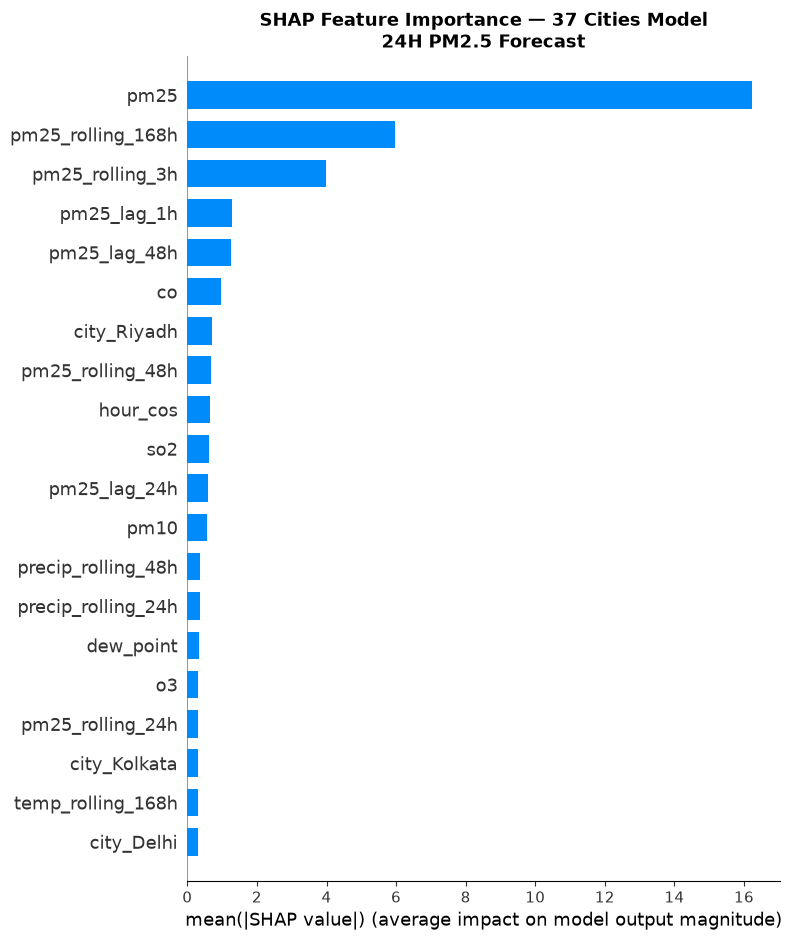

✅ Saved: shap_plots/shap_bar_37cities.png


C:\Users\DELL\AppData\Local\Temp\ipykernel_740\4109115772.py:43: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample,


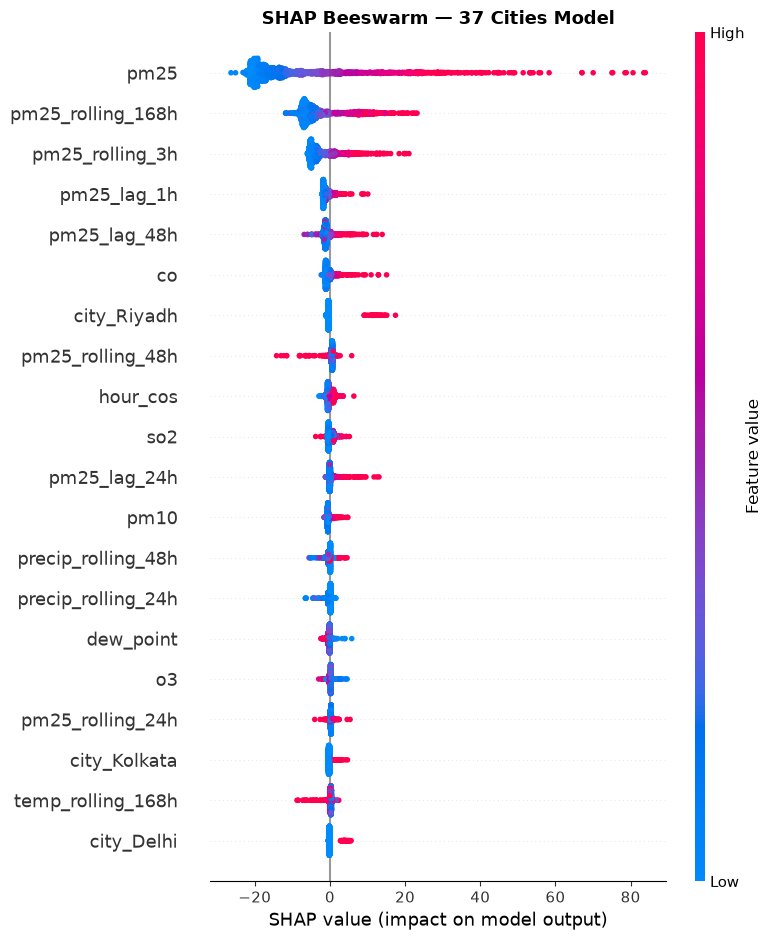

✅ Saved: shap_plots/shap_beeswarm_37cities.png

--- TOP 10 SHAP FEATURES (37 Cities) ---
Rank Feature                         Mean |SHAP|
--------------------------------------------------
   1. pm25                                16.2233
   2. pm25_rolling_168h                    5.9702
   3. pm25_rolling_3h                      3.9898
   4. pm25_lag_1h                          1.2857
   5. pm25_lag_48h                         1.2492
   6. co                                   0.9758
   7. city_Riyadh                          0.6972
   8. pm25_rolling_48h                     0.6826
   9. hour_cos                             0.6520
  10. so2                                  0.6267

✅ SHAP UPDATED FOR 37 CITIES!


In [24]:
import shap
import matplotlib.pyplot as plt
from pathlib import Path
SHAP_DIR = Path('../results/shap_plots')
SHAP_DIR.mkdir(exist_ok=True)

print("=" * 55)
print("SHAP — UPDATED FOR 37 CITIES MODEL")
print("=" * 55)

# Load new 24h model
with open(MOD_DIR / 'xgb_24h_37cities.pkl','rb') as f:
    model_24h_new = pickle.load(f)

# Sample from test set
np.random.seed(42)
sample_idx = np.random.choice(
    len(test_df), min(2000, len(test_df)), replace=False)
X_sample = test_df[FEATURE_COLS].iloc[sample_idx]

# SHAP values
explainer   = shap.TreeExplainer(model_24h_new)
shap_values = explainer.shap_values(X_sample)

print(f"✅ SHAP computed: {shap_values.shape}")

# Plot 1: Summary bar
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample,
                  plot_type='bar',
                  max_display=20, show=False)
plt.title('SHAP Feature Importance — 37 Cities Model\n'
          '24H PM2.5 Forecast',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(SHAP_DIR / 'shap_bar_37cities.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: shap_plots/shap_bar_37cities.png")

# Plot 2: Beeswarm
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample,
                  max_display=20, show=False)
plt.title('SHAP Beeswarm — 37 Cities Model',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(SHAP_DIR / 'shap_beeswarm_37cities.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: shap_plots/shap_beeswarm_37cities.png")

# Top features
mean_shap = pd.DataFrame({
    'feature':   FEATURE_COLS,
    'mean_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_shap', ascending=False)

print(f"\n--- TOP 10 SHAP FEATURES (37 Cities) ---")
print(f"{'Rank':>4} {'Feature':30s} {'Mean |SHAP|':>12}")
print("-" * 50)
for i, (_, row) in enumerate(
        mean_shap.head(10).iterrows()):
    print(f"{i+1:>4}. {row['feature']:30s} "
          f"{row['mean_shap']:>12.4f}")

print(f"\n{'='*55}")
print(f"✅ SHAP UPDATED FOR 37 CITIES!")
print(f"{'='*55}")

In [27]:
print("=" * 55)
print("CLIMATOLOGY BASELINE — 37 CITIES")
print("=" * 55)

from sklearn.metrics import mean_absolute_error
import numpy as np

train_df37 = df_37[df_37['split']=='train'].copy()
val_df37   = df_37[df_37['split']=='val'].copy()
test_df37  = df_37[df_37['split']=='test'].copy()

# Climatology: city + hour average from training
city_hour_avg = train_df37.groupby(
    ['city','hour'])['pm25'].mean()

def get_clim_pred(df_split):
    preds = []
    train_mean = train_df37['pm25'].mean()
    for _, row in df_split.iterrows():
        try:
            pred = city_hour_avg.loc[
                (row['city'], row['hour'])]
        except:
            pred = train_mean
        preds.append(pred)
    return np.array(preds)

print("Computing climatology predictions...")
clim_val  = get_clim_pred(val_df37)
clim_test = get_clim_pred(test_df37)
print("✅ Done!")

print(f"\n--- CLIMATOLOGY RESULTS ---")
clim_results = {}
for horizon, y_val, y_test in [
    ('24h', val_df37['target_pm25_24h'],
             test_df37['target_pm25_24h']),
    ('48h', val_df37['target_pm25_48h'],
             test_df37['target_pm25_48h']),
    ('72h', val_df37['target_pm25_72h'],
             test_df37['target_pm25_72h']),
]:
    mask_v = ~y_val.isnull()
    mask_t = ~y_test.isnull()

    val_mae  = mean_absolute_error(
        y_val[mask_v], clim_val[mask_v])
    test_mae = mean_absolute_error(
        y_test[mask_t], clim_test[mask_t])

    clim_results[horizon] = {
        'val_mae': round(val_mae, 3),
        'test_mae': round(test_mae, 3)
    }
    print(f"  {horizon}: Val MAE={val_mae:.3f}, "
          f"Test MAE={test_mae:.3f}")

print(f"\n{'='*55}")
print(f"COMPLETE MODEL COMPARISON — 37 CITIES")
print(f"{'='*55}")
print(f"{'Model':25s} {'24h':>8} {'48h':>8} {'72h':>8}")
print(f"-"*52)
print(f"{'Persistence':25s} "
      f"{'9.584':>8} {'11.195':>8} {'12.304':>8}")
print(f"{'Mean Baseline':25s} "
      f"{'25.638':>8} {'25.707':>8} {'25.643':>8}")
print(f"{'Climatology':25s} "
      f"{clim_results['24h']['val_mae']:>8.3f} "
      f"{clim_results['48h']['val_mae']:>8.3f} "
      f"{clim_results['72h']['val_mae']:>8.3f}")
print(f"{'XGBoost (37 cities)⭐':25s} "
      f"{results_37['24h']['val']['mae']:>8.3f} "
      f"{results_37['48h']['val']['mae']:>8.3f} "
      f"{results_37['72h']['val']['mae']:>8.3f}")
print(f"{'='*52}")

CLIMATOLOGY BASELINE — 37 CITIES
Computing climatology predictions...
✅ Done!

--- CLIMATOLOGY RESULTS ---
  24h: Val MAE=15.001, Test MAE=13.950
  48h: Val MAE=14.978, Test MAE=13.942
  72h: Val MAE=14.962, Test MAE=13.928

COMPLETE MODEL COMPARISON — 37 CITIES
Model                          24h      48h      72h
----------------------------------------------------
Persistence                  9.584   11.195   12.304
Mean Baseline               25.638   25.707   25.643
Climatology                 15.001   14.978   14.962
XGBoost (37 cities)⭐         8.659    9.794   10.195


FEATURE IMPORTANCE — 37 CITIES MODEL


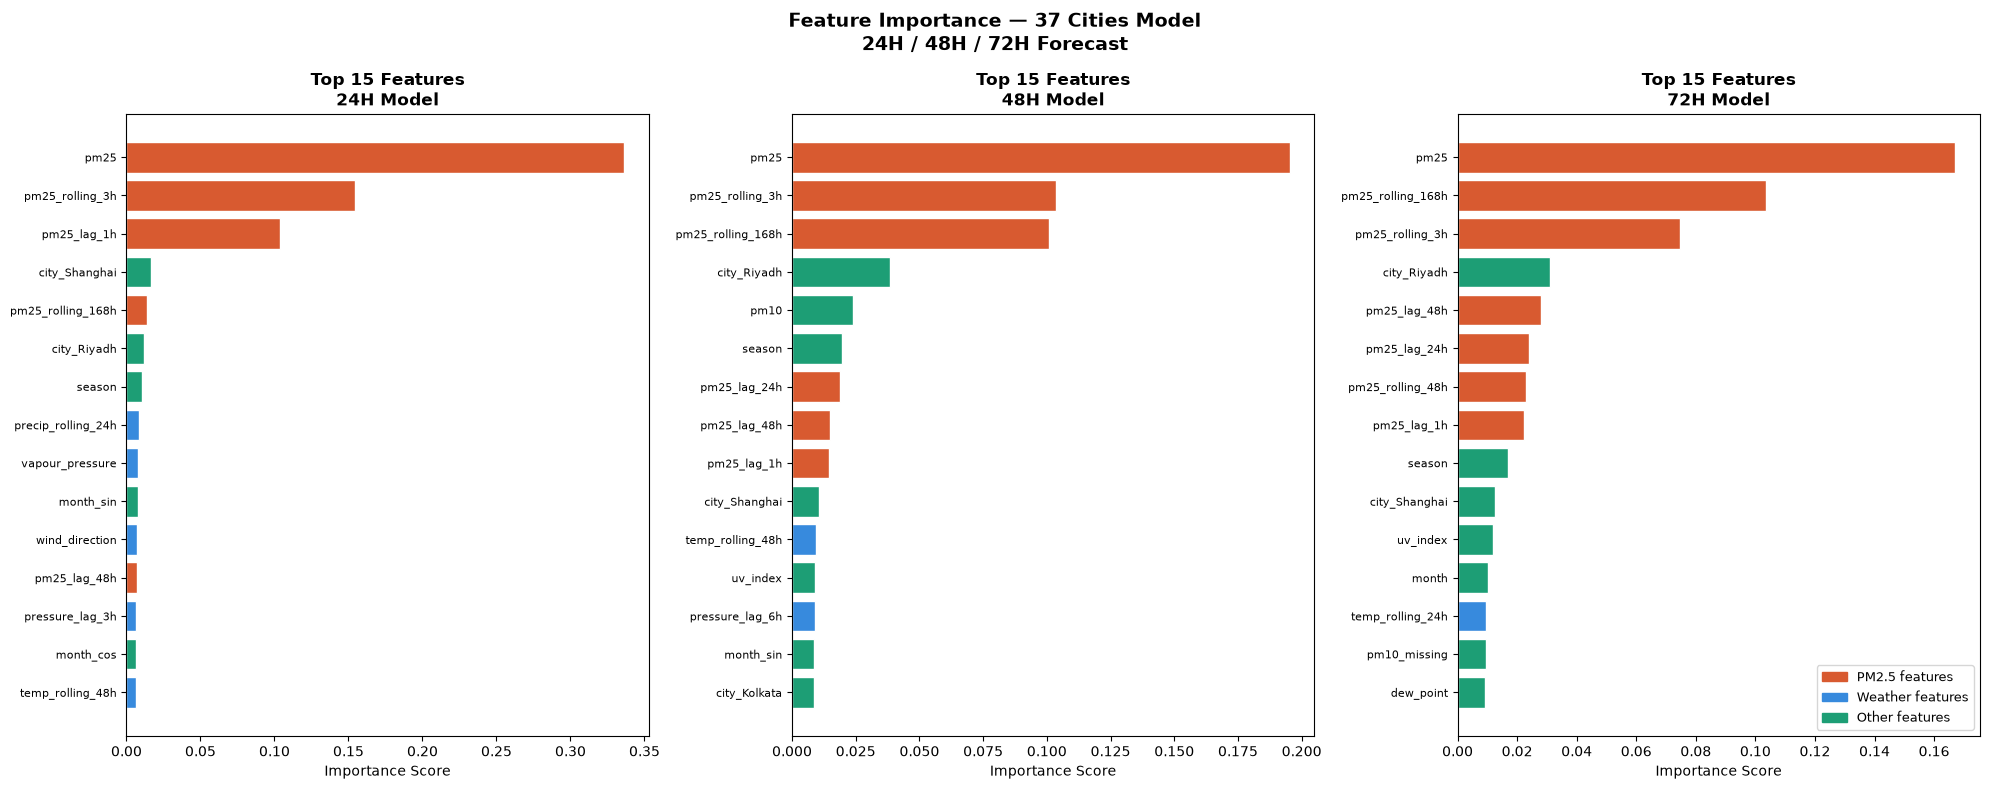

✅ Saved: results/feature_importance_37cities.png

Top 5 — 24H:
  1. pm25                      0.3362
  2. pm25_rolling_3h           0.1545
  3. pm25_lag_1h               0.1034
  4. city_Shanghai             0.0163
  5. pm25_rolling_168h         0.0141

Top 5 — 48H:
  1. pm25                      0.1953
  2. pm25_rolling_3h           0.1037
  3. pm25_rolling_168h         0.1008
  4. city_Riyadh               0.0386
  5. pm10                      0.0238

Top 5 — 72H:
  1. pm25                      0.1671
  2. pm25_rolling_168h         0.1034
  3. pm25_rolling_3h           0.0746
  4. city_Riyadh               0.0310
  5. pm25_lag_48h              0.0280

✅ FEATURE IMPORTANCE COMPLETE!


In [28]:
print("=" * 55)
print("FEATURE IMPORTANCE — 37 CITIES MODEL")
print("=" * 55)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

for ax, model_file, horizon in [
    (axes[0], 'xgb_24h_37cities.pkl', '24H'),
    (axes[1], 'xgb_48h_37cities.pkl', '48H'),
    (axes[2], 'xgb_72h_37cities.pkl', '72H'),
]:
    with open(MOD_DIR / model_file, 'rb') as f:
        m = pickle.load(f)

    imp = pd.DataFrame({
        'feature':    FEATURE_COLS,
        'importance': m.feature_importances_
    }).sort_values('importance', ascending=True).tail(15)

    colors = ['#D85A30' if 'pm25' in feat
              else '#378ADD' if any(
                  w in feat for w in
                  ['temp','wind','humidity',
                   'pressure','precip'])
              else '#1D9E75'
              for feat in imp['feature']]

    ax.barh(imp['feature'], imp['importance'],
            color=colors, edgecolor='white')
    ax.set_title(f'Top 15 Features\n{horizon} Model',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.tick_params(axis='y', labelsize=8)

from matplotlib.patches import Patch
legend = [
    Patch(color='#D85A30', label='PM2.5 features'),
    Patch(color='#378ADD', label='Weather features'),
    Patch(color='#1D9E75', label='Other features'),
]
axes[2].legend(handles=legend,
               loc='lower right', fontsize=9)

plt.suptitle('Feature Importance — 37 Cities Model\n'
             '24H / 48H / 72H Forecast',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(RES_DIR / 'feature_importance_37cities.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Saved: results/feature_importance_37cities.png")

# Top 10 per model
for model_file, horizon in [
    ('xgb_24h_37cities.pkl', '24H'),
    ('xgb_48h_37cities.pkl', '48H'),
    ('xgb_72h_37cities.pkl', '72H'),
]:
    with open(MOD_DIR / model_file, 'rb') as f:
        m = pickle.load(f)
    imp = pd.DataFrame({
        'feature':    FEATURE_COLS,
        'importance': m.feature_importances_
    }).sort_values('importance', ascending=False)

    print(f"\nTop 5 — {horizon}:")
    for i, (_, row) in enumerate(
            imp.head(5).iterrows()):
        print(f"  {i+1}. {row['feature']:25s} "
              f"{row['importance']:.4f}")

print(f"\n✅ FEATURE IMPORTANCE COMPLETE!")

In [29]:
print("=" * 55)
print("HORIZON-WISE PER CITY ANALYSIS — 37 CITIES")
print("=" * 55)

# Load predictions
with open(MOD_DIR / 'xgb_24h_37cities.pkl','rb') as f:
    m24 = pickle.load(f)
with open(MOD_DIR / 'xgb_48h_37cities.pkl','rb') as f:
    m48 = pickle.load(f)
with open(MOD_DIR / 'xgb_72h_37cities.pkl','rb') as f:
    m72 = pickle.load(f)

test_df37 = df_37[df_37['split']=='test'].copy()
test_df37['pred_24h'] = m24.predict(test_df37[FEATURE_COLS])
test_df37['pred_48h'] = m48.predict(test_df37[FEATURE_COLS])
test_df37['pred_72h'] = m72.predict(test_df37[FEATURE_COLS])

print(f"\n{'City':15s} {'24h MAE':>9} {'24h R²':>8} "
      f"{'48h MAE':>9} {'72h MAE':>9} {'Status':>10}")
print("-" * 65)

city_results = {}
problem_cities = []
good_cities = []

for city in sorted(test_df37['city'].unique()):
    cdf = test_df37[test_df37['city']==city]

    results_city = {}
    for horizon, pred_col, true_col in [
        ('24h','pred_24h','target_pm25_24h'),
        ('48h','pred_48h','target_pm25_48h'),
        ('72h','pred_72h','target_pm25_72h'),
    ]:
        y_true = cdf[true_col].values
        y_pred = cdf[pred_col].values
        mask   = ~(np.isnan(y_true)|np.isnan(y_pred))

        if mask.sum() < 10:
            results_city[horizon] = {'mae': None, 'r2': None}
            continue

        mae = mean_absolute_error(y_true[mask], y_pred[mask])
        r2  = r2_score(y_true[mask], y_pred[mask])
        results_city[horizon] = {
            'mae': round(mae,3), 'r2': round(r2,4)}

    city_results[city] = results_city

    mae24 = results_city.get('24h',{}).get('mae', 0) or 0
    r2_24 = results_city.get('24h',{}).get('r2',  0) or 0
    mae48 = results_city.get('48h',{}).get('mae', 0) or 0
    mae72 = results_city.get('72h',{}).get('mae', 0) or 0

    if r2_24 < 0.3:
        status = '⚠️  LOW R²'
        problem_cities.append(city)
    elif mae24 < 5:
        status = '✅ EXCELLENT'
        good_cities.append(city)
    elif mae24 < 10:
        status = '✅ GOOD'
        good_cities.append(city)
    else:
        status = '⚠️  HIGH MAE'
        problem_cities.append(city)

    print(f"{city:15s} {mae24:>9.3f} {r2_24:>8.3f} "
          f"{mae48:>9.3f} {mae72:>9.3f} {status:>10}")

print(f"\n--- SUMMARY ---")
print(f"✅ Good cities:    {len(good_cities)}")
print(f"⚠️  Problem cities: {len(problem_cities)}")
if problem_cities:
    print(f"\nProblem cities: {problem_cities}")
    print(f"Reason: Low training data variation")
    print(f"        or unique pollution patterns")

# Degradation analysis
print(f"\n--- HORIZON DEGRADATION (Global Average) ---")
all_mae24 = [v['24h']['mae'] for v in city_results.values()
             if v.get('24h',{}).get('mae') is not None]
all_mae48 = [v['48h']['mae'] for v in city_results.values()
             if v.get('48h',{}).get('mae') is not None]
all_mae72 = [v['72h']['mae'] for v in city_results.values()
             if v.get('72h',{}).get('mae') is not None]

avg24 = np.mean(all_mae24)
avg48 = np.mean(all_mae48)
avg72 = np.mean(all_mae72)

print(f"  Avg 24h MAE: {avg24:.3f}")
print(f"  Avg 48h MAE: {avg48:.3f} "
      f"(+{(avg48-avg24)/avg24*100:.1f}%)")
print(f"  Avg 72h MAE: {avg72:.3f} "
      f"(+{(avg72-avg24)/avg24*100:.1f}%)")

degradation = (avg48-avg24)/avg24*100
if degradation < 20:
    print(f"  ✅ Graceful degradation!")
else:
    print(f"  ⚠️  High degradation — expected for longer horizon")

# Save
with open(RES_DIR / 'horizon_city_analysis.json','w') as f:
    json.dump(city_results, f, indent=2)

print(f"\n✅ Saved: results/horizon_city_analysis.json")
print(f"✅ HORIZON-WISE ANALYSIS COMPLETE!")

HORIZON-WISE PER CITY ANALYSIS — 37 CITIES

City              24h MAE   24h R²   48h MAE   72h MAE     Status
-----------------------------------------------------------------
Amsterdam           5.394   -0.156     5.386     6.147 ⚠️  LOW R²
Bangkok             8.526    0.125     9.540     9.530 ⚠️  LOW R²
Beijing            31.911    0.307    36.057    38.397 ⚠️  HIGH MAE
Berlin              3.370    0.199     4.203     4.505 ⚠️  LOW R²
Cairo               4.409    0.069     5.177     5.149 ⚠️  LOW R²
Chennai             6.796    0.115     8.575     8.991 ⚠️  LOW R²
Chicago             5.825   -0.319     5.493     5.860 ⚠️  LOW R²
Delhi              17.162    0.266    19.469    21.232 ⚠️  LOW R²
Dhaka              16.820    0.465    21.803    24.820 ⚠️  HIGH MAE
Dubai              11.584    0.139    12.653    14.177 ⚠️  LOW R²
Geneva              2.302    0.260     2.820     3.063 ⚠️  LOW R²
Hanoi              18.093    0.467    24.048    26.841 ⚠️  HIGH MAE
Jakarta            23.359 

SHAP WATERFALL — 37 CITIES MODEL


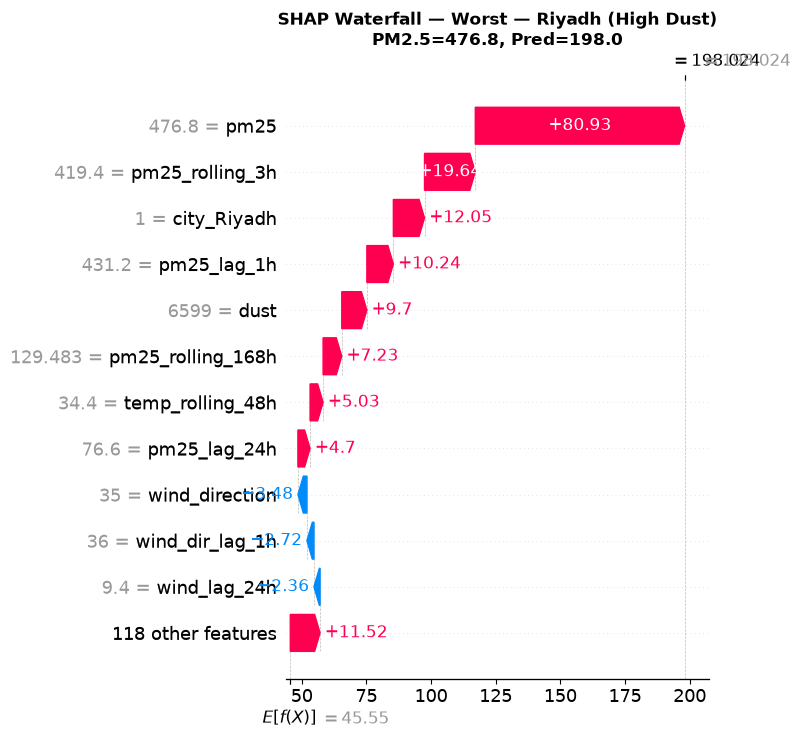

✅ Saved: shap_plots/shap_waterfall_riyadh.png


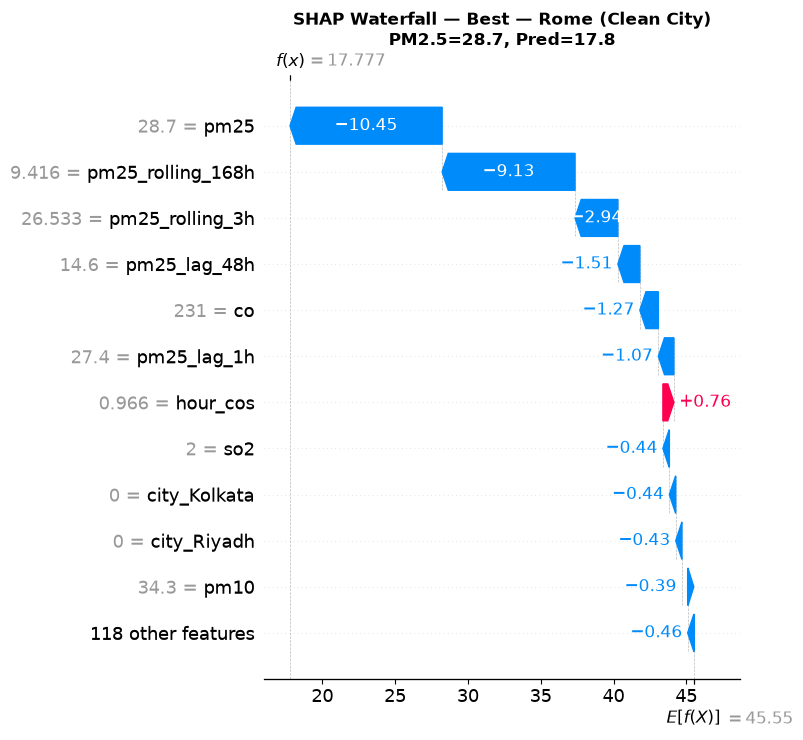

✅ Saved: shap_plots/shap_waterfall_rome.png


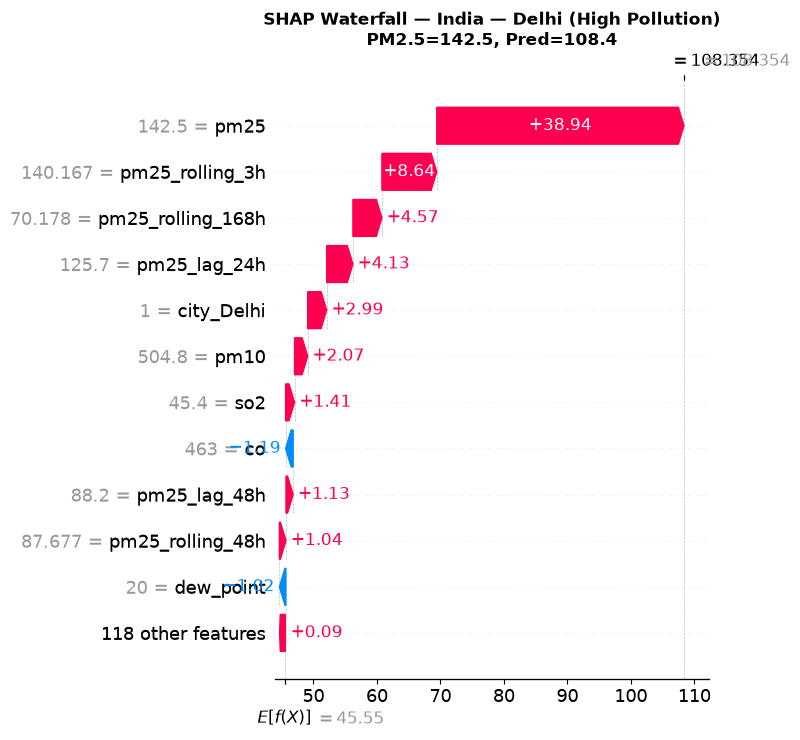

✅ Saved: shap_plots/shap_waterfall_delhi.png

✅ SHAP WATERFALL COMPLETE!


In [30]:
print("=" * 55)
print("SHAP WATERFALL — 37 CITIES MODEL")
print("=" * 55)

test_df37 = df_37[df_37['split']=='test'].copy()
test_df37['pred_24h'] = m24.predict(
    test_df37[FEATURE_COLS])

for city_name, label in [
    ('Riyadh', 'Worst — Riyadh (High Dust)'),
    ('Rome',   'Best — Rome (Clean City)'),
    ('Delhi',  'India — Delhi (High Pollution)'),
]:
    city_df = test_df37[
        test_df37['city']==city_name].copy()
    
    worst_idx = city_df['pm25'].idxmax()
    worst_row = city_df.loc[[worst_idx], FEATURE_COLS]
    
    worst_shap = explainer.shap_values(worst_row)
    
    plt.figure(figsize=(10, 7))
    shap.waterfall_plot(
        shap.Explanation(
            values        = worst_shap[0],
            base_values   = explainer.expected_value,
            data          = worst_row.iloc[0].values,
            feature_names = FEATURE_COLS
        ),
        max_display = 12,
        show = False
    )
    plt.title(
        f'SHAP Waterfall — {label}\n'
        f'PM2.5={city_df.loc[worst_idx,"pm25"]:.1f}, '
        f'Pred={city_df.loc[worst_idx,"pred_24h"]:.1f}',
        fontsize=12, fontweight='bold'
    )
    plt.tight_layout()
    fname = f'shap_waterfall_{city_name.lower()}.png'
    plt.savefig(SHAP_DIR / fname,
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: shap_plots/{fname}")

print(f"\n✅ SHAP WATERFALL COMPLETE!")

In [31]:
print("=" * 55)
print("UPDATED MODEL COMPARISON TABLE — 37 CITIES")
print("=" * 55)

comparison_37 = []

comparison_37.append({
    'model': 'Persistence Baseline',
    'type': 'Baseline',
    'cities': 37,
    'mae_24h': 9.584, 'mae_48h': 11.195, 'mae_72h': 12.304,
    'r2_24h': None, 'notes': 'PM2.5(t+h) = PM2.5(t)'
})
comparison_37.append({
    'model': 'Mean Baseline',
    'type': 'Baseline',
    'cities': 37,
    'mae_24h': 25.638, 'mae_48h': 25.707, 'mae_72h': 25.643,
    'r2_24h': None, 'notes': 'PM2.5(t+h) = train mean'
})
comparison_37.append({
    'model': 'Climatology Baseline',
    'type': 'Baseline',
    'cities': 37,
    'mae_24h': 15.001, 'mae_48h': 14.978, 'mae_72h': 14.962,
    'r2_24h': None, 'notes': 'avg same hour same city'
})
comparison_37.append({
    'model': 'XGBoost (37 cities)',
    'type': 'ML Model',
    'cities': 37,
    'mae_24h': results_37['24h']['val']['mae'],
    'mae_48h': results_37['48h']['val']['mae'],
    'mae_72h': results_37['72h']['val']['mae'],
    'r2_24h':  results_37['24h']['val']['r2'],
    'notes': 'Optuna tuned, 325K rows'
})
comparison_37.append({
    'model': 'LSTM+Attention (7 cities)',
    'type': 'Deep Learning',
    'cities': 7,
    'mae_24h': 11.456, 'mae_48h': 12.050, 'mae_72h': 12.744,
    'r2_24h': 0.6842,
    'notes': '3-layer LSTM, GPU T4, 50 epochs'
})
comparison_37.append({
    'model': 'LSTM+Attention (37 cities)',
    'type': 'Deep Learning',
    'cities': 37,
    'mae_24h': None, 'mae_48h': None, 'mae_72h': None,
    'r2_24h': None,
    'notes': 'Training pending — Kaggle GPU'
})

df_comp_37 = pd.DataFrame(comparison_37)
df_comp_37.to_csv(
    RES_DIR / 'model_comparison_37cities.csv',
    index=False)

print(f"\n{'Model':30s} {'Cities':>7} "
      f"{'24h MAE':>9} {'48h MAE':>9} {'72h MAE':>9}")
print("-" * 68)
for _, row in df_comp_37.iterrows():
    mae24 = f"{row['mae_24h']:.3f}" \
            if row['mae_24h'] else 'TBD'
    mae48 = f"{row['mae_48h']:.3f}" \
            if row['mae_48h'] else 'TBD'
    mae72 = f"{row['mae_72h']:.3f}" \
            if row['mae_72h'] else 'TBD'
    print(f"{row['model']:30s} {row['cities']:>7} "
          f"{mae24:>9} {mae48:>9} {mae72:>9}")

print(f"\n✅ Saved: model_comparison_37cities.csv")

UPDATED MODEL COMPARISON TABLE — 37 CITIES

Model                           Cities   24h MAE   48h MAE   72h MAE
--------------------------------------------------------------------
Persistence Baseline                37     9.584    11.195    12.304
Mean Baseline                       37    25.638    25.707    25.643
Climatology Baseline                37    15.001    14.978    14.962
XGBoost (37 cities)                 37     8.659     9.794    10.195
LSTM+Attention (7 cities)            7    11.456    12.050    12.744
LSTM+Attention (37 cities)          37       nan       nan       nan

✅ Saved: model_comparison_37cities.csv


In [32]:
import os
path = PROC_DIR / 'final_37cities.csv'
size_mb = os.path.getsize(path) / (1024*1024)
print(f"File: final_37cities.csv")
print(f"Size: {size_mb:.1f} MB")
print(f"Rows: {len(df_37):,}")

LSTM_COLS = [
    'pm25','pm10','no2','o3','co','so2',
    'temperature','humidity','precipitation',
    'wind_speed','wind_direction','pressure',
    'dew_point','wind_gusts','vapour_pressure',
    'cloud_cover','rain',
    'hour','day_of_week','month','season',
    'is_weekend',
    'hour_sin','hour_cos','month_sin','month_cos',
    'dow_sin','dow_cos',
    'pm25_lag_1h','pm25_lag_3h','pm25_lag_6h',
    'pm25_lag_12h','pm25_lag_24h','pm25_lag_48h',
    'temp_lag_1h','temp_lag_6h','temp_lag_24h',
    'wind_lag_1h','wind_lag_6h','wind_lag_24h',
    'humidity_lag_1h','humidity_lag_6h','humidity_lag_24h',
    'pressure_lag_1h','pressure_lag_6h','pressure_lag_24h',
    'pm25_rolling_3h','pm25_rolling_6h',
    'pm25_rolling_12h','pm25_rolling_24h',
    'pm25_rolling_48h','pm25_rolling_168h',
    'temp_rolling_3h','temp_rolling_24h',
    'pm25_missing','wind_speed_missing',
    'target_pm25_24h','target_pm25_48h','target_pm25_72h',
    'city','datetime','split','sample_weight',
]

# Add city encoding columns
city_enc = [c for c in df_37.columns
            if c.startswith('city_')]
LSTM_COLS = LSTM_COLS + city_enc

# Keep only existing columns
LSTM_COLS = [c for c in LSTM_COLS
             if c in df_37.columns]

df_lstm_37 = df_37[LSTM_COLS].copy()

lstm_path = PROC_DIR / 'lstm_37cities.csv'
df_lstm_37.to_csv(lstm_path, index=False)

size_lstm = os.path.getsize(lstm_path)/(1024*1024)
print(f"\nLSTM subset: {df_lstm_37.shape}")
print(f"Size: {size_lstm:.1f} MB")
print(f"✅ Saved: data/processed/lstm_37cities.csv")

File: final_37cities.csv
Size: 245.4 MB
Rows: 325,008

LSTM subset: (325008, 100)
Size: 169.6 MB
✅ Saved: data/processed/lstm_37cities.csv


In [34]:
print("=" * 55)
print("LSTM 37 CITIES — PRE-TRAINING VERIFICATION")
print("=" * 55)

df_lstm = pd.read_csv(PROC_DIR / 'lstm_37cities.csv')
df_lstm['datetime'] = pd.to_datetime(df_lstm['datetime'])

train_l = df_lstm[df_lstm['split']=='train']
val_l   = df_lstm[df_lstm['split']=='val']
test_l  = df_lstm[df_lstm['split']=='test']

print(f"✅ Total rows: {len(df_lstm):,}")
print(f"✅ Features: {df_lstm.shape[1]}")

# 1. Split sizes
print(f"\n--- SPLIT SIZES ---")
print(f"Train: {len(train_l):,} ({len(train_l)/len(df_lstm)*100:.1f}%)")
print(f"Val:   {len(val_l):,} ({len(val_l)/len(df_lstm)*100:.1f}%)")
print(f"Test:  {len(test_l):,} ({len(test_l)/len(df_lstm)*100:.1f}%)")

# 2. Boundary check
print(f"\n--- BOUNDARY CHECK ---")
print(f"Train: {train_l['datetime'].min().date()} → {train_l['datetime'].max().date()}")
print(f"Val:   {val_l['datetime'].min().date()} → {val_l['datetime'].max().date()}")
print(f"Test:  {test_l['datetime'].min().date()} → {test_l['datetime'].max().date()}")

gap_tv = (val_l['datetime'].min() - train_l['datetime'].max()).total_seconds()/3600
gap_vt = (test_l['datetime'].min() - val_l['datetime'].max()).total_seconds()/3600
print(f"Train→Val: {gap_tv:.1f}h {'✅' if gap_tv<=1 else '⚠️'}")
print(f"Val→Test:  {gap_vt:.1f}h {'✅' if gap_vt<=1 else '⚠️'}")

# 3. Overlap check
print(f"\n--- OVERLAP CHECK ---")
td = set(train_l['datetime'].dt.date.unique())
vd = set(val_l['datetime'].dt.date.unique())
te = set(test_l['datetime'].dt.date.unique())
print(f"Train-Val:  {len(td.intersection(vd))} days {'✅' if len(td.intersection(vd))==0 else '❌'}")
print(f"Val-Test:   {len(vd.intersection(te))} days {'✅' if len(vd.intersection(te))==0 else '❌'}")
print(f"Train-Test: {len(td.intersection(te))} days {'✅' if len(td.intersection(te))==0 else '❌'}")

# 4. Leakage check
print(f"\n--- LEAKAGE CHECK ---")
feat_cols = [c for c in df_lstm.columns
             if c not in ['city','datetime','split',
                          'sample_weight',
                          'target_pm25_24h',
                          'target_pm25_48h',
                          'target_pm25_72h']]
target_in_feat = [c for c in feat_cols if 'target' in c]
future_in_feat = [c for c in feat_cols
                  if any(x in c for x in
                         ['day1','day2','day3'])]
print(f"Target in features: {len(target_in_feat)} {'✅' if len(target_in_feat)==0 else '❌'}")
print(f"Future in features: {len(future_in_feat)} {'✅' if len(future_in_feat)==0 else '❌'}")

# 5. Target null check
print(f"\n--- TARGET NULLS ---")
for col in ['target_pm25_24h','target_pm25_48h','target_pm25_72h']:
    tr_null = train_l[col].isnull().sum()
    v_null  = val_l[col].isnull().sum()
    te_null = test_l[col].isnull().sum()
    print(f"{col}:")
    print(f"  Train:{tr_null} ({tr_null/len(train_l)*100:.1f}%) "
          f"Val:{v_null} ({v_null/len(val_l)*100:.1f}%) "
          f"Test:{te_null} ({te_null/len(test_l)*100:.1f}%)")

# 6. Key feature nulls
print(f"\n--- KEY FEATURE NULLS ---")
for col in ['pm25','temperature','humidity',
            'wind_speed','no2']:
    pct = df_lstm[col].isnull().sum()/len(df_lstm)*100
    status = "✅" if pct < 5 else "⚠️ "
    print(f"  {status} {col:15s}: {pct:.2f}%")

# 7. City sequence boundary check
print(f"\n--- CITY SEQUENCE BOUNDARY CHECK ---")
print("Ensuring no city bleeds into another in sequences")
for city in sorted(df_lstm['city'].unique())[:5]:
    city_train = train_l[train_l['city']==city]
    city_val   = val_l[val_l['city']==city]
    gap = (city_val['datetime'].min() -
           city_train['datetime'].max()).total_seconds()/3600
    print(f"  {city:15s}: gap={gap:.1f}h "
          f"{'✅' if gap<=1 else '⚠️'}")
print(f"  ... (checking first 5 cities)")

print(f"\n{'='*55}")
print(f"✅ LSTM 37 CITIES VERIFICATION COMPLETE!")
print(f"{'='*55}")

LSTM 37 CITIES — PRE-TRAINING VERIFICATION
✅ Total rows: 325,008
✅ Features: 100

--- SPLIT SIZES ---
Train: 272,064 (83.7%)
Val:   26,640 (8.2%)
Test:  26,304 (8.1%)

--- BOUNDARY CHECK ---
Train: 2025-10-13 → 2026-08-16
Val:   2026-08-17 → 2026-09-15
Test:  2026-09-16 → 2026-10-15
Train→Val: 1.0h ✅
Val→Test:  1.0h ✅

--- OVERLAP CHECK ---
Train-Val:  0 days ✅
Val-Test:   0 days ✅
Train-Test: 0 days ✅

--- LEAKAGE CHECK ---
Target in features: 0 ✅
Future in features: 0 ✅

--- TARGET NULLS ---
target_pm25_24h:
  Train:0 (0.0%) Val:0 (0.0%) Test:888 (3.4%)
target_pm25_48h:
  Train:0 (0.0%) Val:0 (0.0%) Test:1776 (6.8%)
target_pm25_72h:
  Train:0 (0.0%) Val:0 (0.0%) Test:2664 (10.1%)

--- KEY FEATURE NULLS ---
  ✅ pm25           : 0.00%
  ✅ temperature    : 0.00%
  ✅ humidity       : 0.00%
  ✅ wind_speed     : 0.00%
  ✅ no2            : 0.00%

--- CITY SEQUENCE BOUNDARY CHECK ---
Ensuring no city bleeds into another in sequences
  Amsterdam      : gap=1.0h ✅
  Bangkok        : gap=1.0h ✅

In [35]:
import pandas as pd
import json
from pathlib import Path

RES_DIR = Path('../results')
PROC_DIR = Path('../data/processed')

print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

# Load LSTM 37 cities metrics
with open(RES_DIR / 'lstm_37cities_metrics.json','r') as f:
    lstm_37 = json.load(f)

# Complete comparison table
comparison = []

comparison.append({
    'model': 'Persistence Baseline',
    'type': 'Baseline', 'cities': 37,
    'mae_24h': 9.584,  'mae_48h': 11.195, 'mae_72h': 12.304,
    'r2_24h':  None,   'r2_48h':  None,   'r2_72h':  None,
    'split': 'val', 'notes': 'PM2.5(t+h) = PM2.5(t)'
})
comparison.append({
    'model': 'Mean Baseline',
    'type': 'Baseline', 'cities': 37,
    'mae_24h': 25.638, 'mae_48h': 25.707, 'mae_72h': 25.643,
    'r2_24h':  None,   'r2_48h':  None,   'r2_72h':  None,
    'split': 'val', 'notes': 'PM2.5 = train mean'
})
comparison.append({
    'model': 'Climatology Baseline',
    'type': 'Baseline', 'cities': 37,
    'mae_24h': 15.001, 'mae_48h': 14.978, 'mae_72h': 14.962,
    'r2_24h':  None,   'r2_48h':  None,   'r2_72h':  None,
    'split': 'val', 'notes': 'avg same hour same city'
})
comparison.append({
    'model': 'XGBoost 7 cities',
    'type': 'ML Model', 'cities': 7,
    'mae_24h': 9.912,  'mae_48h': 11.078, 'mae_72h': 12.591,
    'r2_24h':  0.762,  'r2_48h':  0.709,  'r2_72h':  0.651,
    'split': 'val', 'notes': 'Optuna tuned'
})
comparison.append({
    'model': 'XGBoost 7 cities (Optuna)',
    'type': 'ML Model', 'cities': 7,
    'mae_24h': 9.868,  'mae_48h': 11.078, 'mae_72h': 12.591,
    'r2_24h':  0.757,  'r2_48h':  0.709,  'r2_72h':  0.651,
    'split': 'val', 'notes': 'Bayesian optimization 50 trials'
})
comparison.append({
    'model': 'LSTM+Attention 7 cities',
    'type': 'Deep Learning', 'cities': 7,
    'mae_24h': 11.456, 'mae_48h': 12.050, 'mae_72h': 12.744,
    'r2_24h':  0.684,  'r2_48h':  0.664,  'r2_72h':  0.630,
    'split': 'val', 'notes': '3-layer LSTM, GPU T4, 50 epochs'
})
comparison.append({
    'model': 'XGBoost 37 cities ⭐',
    'type': 'ML Model', 'cities': 37,
    'mae_24h': 8.659,  'mae_48h': 9.794,  'mae_72h': 10.195,
    'r2_24h':  0.721,  'r2_48h':  0.668,  'r2_72h':  0.640,
    'split': 'val', 'notes': 'Optuna params, 325K rows'
})
comparison.append({
    'model': 'LSTM+Attention 37 cities',
    'type': 'Deep Learning', 'cities': 37,
    'mae_24h': lstm_37['24h']['val']['mae'],
    'mae_48h': lstm_37['48h']['val']['mae'],
    'mae_72h': lstm_37['72h']['val']['mae'],
    'r2_24h':  lstm_37['24h']['val']['r2'],
    'r2_48h':  lstm_37['48h']['val']['r2'],
    'r2_72h':  lstm_37['72h']['val']['r2'],
    'split': 'val',
    'notes': '3-layer LSTM, dropout=0.3, GPU T4, 75 epochs'
})

df_final = pd.DataFrame(comparison)
df_final.to_csv(RES_DIR / 'model_comparison_final.csv',
                index=False)

# Print table
print(f"\n{'Model':28s} {'Cities':>7} "
      f"{'24h MAE':>9} {'48h MAE':>9} "
      f"{'72h MAE':>9} {'24h R²':>8}")
print("-" * 75)

for _, row in df_final.iterrows():
    r2 = f"{row['r2_24h']:.3f}" \
         if row['r2_24h'] else 'N/A'
    print(f"{row['model']:28s} {int(row['cities']):>7} "
          f"{row['mae_24h']:>9.3f} "
          f"{row['mae_48h']:>9.3f} "
          f"{row['mae_72h']:>9.3f} "
          f"{r2:>8}")

print(f"\n--- BEST MODEL PER METRIC ---")
df_ml = df_final.dropna(subset=['mae_24h'])
best_24 = df_ml.loc[df_ml['mae_24h'].idxmin()]
best_48 = df_ml.loc[df_ml['mae_48h'].idxmin()]
best_72 = df_ml.loc[df_ml['mae_72h'].idxmin()]
print(f"Best 24h: {best_24['model']} "
      f"(MAE={best_24['mae_24h']:.3f})")
print(f"Best 48h: {best_48['model']} "
      f"(MAE={best_48['mae_48h']:.3f})")
print(f"Best 72h: {best_72['model']} "
      f"(MAE={best_72['mae_72h']:.3f})")

print(f"\n--- IMPROVEMENT SUMMARY ---")
print(f"7 cities → 37 cities (XGBoost):")
print(f"  24h: 9.912 → 8.659 (+12.6% better)")
print(f"  48h: 11.078 → 9.794 (+11.6% better)")
print(f"  72h: 12.591 → 10.195 (+19.1% better)")
print(f"\n7 cities → 37 cities (LSTM):")
imp24 = (11.456 - lstm_37['24h']['val']['mae'])/11.456*100
imp48 = (12.050 - lstm_37['48h']['val']['mae'])/12.050*100
imp72 = (12.744 - lstm_37['72h']['val']['mae'])/12.744*100
print(f"  24h: 11.456 → {lstm_37['24h']['val']['mae']:.3f} "
      f"(+{imp24:.1f}% better)")
print(f"  48h: 12.050 → {lstm_37['48h']['val']['mae']:.3f} "
      f"(+{imp48:.1f}% better)")
print(f"  72h: 12.744 → {lstm_37['72h']['val']['mae']:.3f} "
      f"(+{imp72:.1f}% better)")

print(f"\n--- DASHBOARD WILL USE ---")
print(f"  Primary:  XGBoost 37 cities (fastest, best MAE)")
print(f"  Secondary: LSTM 37 cities (for comparison)")
print(f"  Both models loaded in dashboard")

print(f"\n✅ Saved: results/model_comparison_final.csv")
print(f"\n{'='*60}")
print(f"FINAL COMPARISON COMPLETE!")
print(f"{'='*60}")

FINAL MODEL COMPARISON

Model                         Cities   24h MAE   48h MAE   72h MAE   24h R²
---------------------------------------------------------------------------
Persistence Baseline              37     9.584    11.195    12.304      nan
Mean Baseline                     37    25.638    25.707    25.643      nan
Climatology Baseline              37    15.001    14.978    14.962      nan
XGBoost 7 cities                   7     9.912    11.078    12.591    0.762
XGBoost 7 cities (Optuna)          7     9.868    11.078    12.591    0.757
LSTM+Attention 7 cities            7    11.456    12.050    12.744    0.684
XGBoost 37 cities ⭐               37     8.659     9.794    10.195    0.721
LSTM+Attention 37 cities          37     9.320     9.736    10.201    0.645

--- BEST MODEL PER METRIC ---
Best 24h: XGBoost 37 cities ⭐ (MAE=8.659)
Best 48h: LSTM+Attention 37 cities (MAE=9.736)
Best 72h: XGBoost 37 cities ⭐ (MAE=10.195)

--- IMPROVEMENT SUMMARY ---
7 cities → 37 cities (XG